In [ ]:
# ============================================================
# 06_Maize_Model_Training.ipynb
# CELL 1 — ENVIRONMENT SETUP + DATASET VERIFICATION
# ============================================================

import os
import random
from pathlib import Path

import numpy as np
import torch
import torchvision

from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Reproducibility settings
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# 3. Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

# ------------------------------------------------------------
# 4. Frozen dataset path
# ------------------------------------------------------------

DATASET_ROOT = Path(
    "/content/drive/MyDrive/"
    "final_year_project/maize/"
    "Final_Maize_Dataset"
)

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR   = DATASET_ROOT / "val"
TEST_DIR  = DATASET_ROOT / "test"

CLASSES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]

EXPECTED_COUNTS = {
    "train": {
        "Healthy": 1662,
        "MLN": 1671,
        "MSV": 1709,
        "NLB": 341,
        "NLS": 379,
    },
    "val": {
        "Healthy": 357,
        "MLN": 359,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    },
    "test": {
        "Healthy": 357,
        "MLN": 358,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    }
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

# ------------------------------------------------------------
# 5. Basic environment information
# ------------------------------------------------------------

print("=" * 80)
print("MAIZE MODEL TRAINING — ENVIRONMENT SETUP")
print("=" * 80)

print(f"\nPyTorch     : {torch.__version__}")
print(f"Torchvision : {torchvision.__version__}")
print(f"Device      : {DEVICE}")

if torch.cuda.is_available():

    print(
        f"GPU         : "
        f"{torch.cuda.get_device_name(0)}"
    )

    gpu_memory = (
        torch.cuda.get_device_properties(0)
        .total_memory
        / (1024 ** 3)
    )

    print(
        f"GPU memory  : "
        f"{gpu_memory:.2f} GB"
    )

else:

    print(
        "WARNING: GPU is NOT enabled."
    )

# ------------------------------------------------------------
# 6. Verify frozen dataset
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FROZEN DATASET VERIFICATION")
print("=" * 80)

assert DATASET_ROOT.exists(), (
    f"Dataset not found:\n{DATASET_ROOT}"
)

grand_total = 0

split_paths = {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR
}

for split_name, split_dir in split_paths.items():

    assert split_dir.exists(), (
        f"Missing split folder:\n{split_dir}"
    )

    print(f"\n{split_name.upper()}")

    split_total = 0

    for class_name in CLASSES:

        class_dir = (
            split_dir / class_name
        )

        assert class_dir.exists(), (
            f"Missing class folder:\n{class_dir}"
        )

        count = sum(
            1
            for p in class_dir.iterdir()
            if p.is_file()
            and p.suffix in IMAGE_EXTENSIONS
        )

        expected = (
            EXPECTED_COUNTS
            [split_name]
            [class_name]
        )

        assert count == expected, (
            f"Count mismatch for "
            f"{split_name}/{class_name}: "
            f"expected {expected}, "
            f"found {count}"
        )

        print(
            f"  ✓ {class_name:<8}: "
            f"{count:,}"
        )

        split_total += count

    print(
        f"  {'TOTAL':<10}: "
        f"{split_total:,}"
    )

    grand_total += split_total

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

assert grand_total == 8239

print("\n" + "=" * 80)
print("SETUP COMPLETE")
print("=" * 80)

print(
    f"\nTotal frozen images : "
    f"{grand_total:,}"
)

print(
    f"Classes             : "
    f"{len(CLASSES)}"
)

print(
    f"Random seed         : "
    f"{SEED}"
)

print(
    f"Dataset             : "
    f"{DATASET_ROOT}"
)

print(
    "\n✓ Frozen train/val/test dataset verified."
)

print(
    "✓ No split was regenerated."
)

print(
    "✓ No image was modified."
)

print(
    "✓ Ready to build the training pipeline."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MAIZE MODEL TRAINING — ENVIRONMENT SETUP

PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128
Device      : cuda
GPU         : Tesla T4
GPU memory  : 14.56 GB

FROZEN DATASET VERIFICATION

TRAIN


AssertionError: Count mismatch for train/Healthy: expected 1662, found 416

In [2]:
# ============================================================
# DIAGNOSTIC — WHY DOES TRAIN/HEALTHY SHOW ONLY 416?
#
# READ-ONLY
# Does NOT modify/delete/copy anything.
# ============================================================

from pathlib import Path
import os
import glob

DATASET_ROOT = Path(
    "/content/drive/MyDrive/"
    "final_year_project/maize/"
    "Final_Maize_Dataset"
)

HEALTHY_DIR = DATASET_ROOT / "train" / "Healthy"

print("=" * 80)
print("DATASET DIAGNOSTIC")
print("=" * 80)

print(f"\nDataset root:\n{DATASET_ROOT}")
print(f"\nHealthy folder:\n{HEALTHY_DIR}")

print("\nExists:")
print("Dataset root :", DATASET_ROOT.exists())
print("Train folder :", (DATASET_ROOT / "train").exists())
print("Healthy      :", HEALTHY_DIR.exists())

# ------------------------------------------------------------
# Show dataset root
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATASET ROOT CONTENTS")
print("=" * 80)

if DATASET_ROOT.exists():

    for item in sorted(DATASET_ROOT.iterdir()):
        print(
            "[DIR] " if item.is_dir() else "[FILE]",
            item.name
        )

# ------------------------------------------------------------
# Show train folders
# ------------------------------------------------------------

TRAIN_DIR = DATASET_ROOT / "train"

print("\n" + "=" * 80)
print("TRAIN DIRECTORY CONTENTS")
print("=" * 80)

if TRAIN_DIR.exists():

    for item in sorted(TRAIN_DIR.iterdir()):

        if item.is_dir():

            try:
                n = len(os.listdir(item))
            except Exception as e:
                n = f"ERROR: {e}"

            print(
                f"{item.name:<10} "
                f"os.listdir={n}"
            )

# ------------------------------------------------------------
# Compare counting methods for Healthy
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("HEALTHY COUNT — MULTIPLE METHODS")
print("=" * 80)

if HEALTHY_DIR.exists():

    # Method 1
    try:
        listdir_items = os.listdir(HEALTHY_DIR)

        print(
            "\nos.listdir              :",
            len(listdir_items)
        )

    except Exception as e:

        print(
            "\nos.listdir ERROR:",
            e
        )

    # Method 2
    try:
        pathlib_items = list(
            HEALTHY_DIR.iterdir()
        )

        print(
            "Path.iterdir             :",
            len(pathlib_items)
        )

    except Exception as e:

        print(
            "Path.iterdir ERROR:",
            e
        )

    # Method 3
    jpg_glob = glob.glob(
        str(HEALTHY_DIR / "*.jpg")
    )

    jpeg_glob = glob.glob(
        str(HEALTHY_DIR / "*.jpeg")
    )

    png_glob = glob.glob(
        str(HEALTHY_DIR / "*.png")
    )

    print(
        "glob *.jpg               :",
        len(jpg_glob)
    )

    print(
        "glob *.jpeg              :",
        len(jpeg_glob)
    )

    print(
        "glob *.png               :",
        len(png_glob)
    )

    print(
        "glob image total         :",
        len(jpg_glob)
        + len(jpeg_glob)
        + len(png_glob)
    )

    # --------------------------------------------------------
    # Show first/last filenames
    # --------------------------------------------------------

    names = sorted(
        p.name
        for p in HEALTHY_DIR.iterdir()
        if p.is_file()
    )

    print("\nFirst 10 files:")

    for name in names[:10]:
        print(" ", name)

    print("\nLast 10 files:")

    for name in names[-10:]:
        print(" ", name)

# ------------------------------------------------------------
# Check manifest
# ------------------------------------------------------------

MANIFEST = (
    DATASET_ROOT /
    "final_maize_split_manifest.csv"
)

print("\n" + "=" * 80)
print("MANIFEST")
print("=" * 80)

print(
    "\nManifest exists:",
    MANIFEST.exists()
)

if MANIFEST.exists():

    import pandas as pd

    df = pd.read_csv(MANIFEST)

    print(
        "Manifest rows:",
        len(df)
    )

    manifest_healthy_train = len(
        df[
            (df["split"] == "train")
            &
            (df["class"] == "Healthy")
        ]
    )

    print(
        "Manifest train/Healthy:",
        manifest_healthy_train
    )

print("\n✓ Diagnostic only. Nothing was modified.")

DATASET DIAGNOSTIC

Dataset root:
/content/drive/MyDrive/final_year_project/maize/Final_Maize_Dataset

Healthy folder:
/content/drive/MyDrive/final_year_project/maize/Final_Maize_Dataset/train/Healthy

Exists:
Dataset root : True
Train folder : True
Healthy      : True

DATASET ROOT CONTENTS
[DIR]  test
[DIR]  train
[DIR]  val

TRAIN DIRECTORY CONTENTS
Healthy    os.listdir=17
MLN        os.listdir=0
MSV        os.listdir=0
NLB        os.listdir=0
NLS        os.listdir=0

HEALTHY COUNT — MULTIPLE METHODS

os.listdir              : 17
Path.iterdir             : 17
glob *.jpg               : 17
glob *.jpeg              : 0
glob *.png               : 0
glob image total         : 17

First 10 files:
  1711617163472.jpg
  1711617188132.jpg
  1711617264702.jpg
  1711617297013.jpg
  1711617326645.jpg
  1711617374256.jpg
  1711617376353.jpg
  1711617408485.jpg
  1711617420032.jpg
  1711617460935.jpg

Last 10 files:
  1711617408485.jpg
  1711617420032.jpg
  1711617460935.jpg
  1711617477850.jpg

In [1]:
# ============================================================
# FINAL DATASET — DRIVE INTEGRITY CHECK
#
# Compares EVERY manifest entry against the physical Drive copy.
#
# READ-ONLY
# Does NOT copy/delete/move anything.
# ============================================================

from pathlib import Path
import pandas as pd
from collections import Counter

DATASET_ROOT = Path(
    "/content/drive/MyDrive/"
    "final_year_project/maize/"
    "Final_Maize_Dataset"
)

MANIFEST = (
    DATASET_ROOT /
    "final_maize_split_manifest.csv"
)

print("=" * 80)
print("FINAL DATASET — GOOGLE DRIVE INTEGRITY CHECK")
print("=" * 80)

# ------------------------------------------------------------
# Load frozen manifest
# ------------------------------------------------------------

assert MANIFEST.exists(), (
    f"Manifest missing:\n{MANIFEST}"
)

df = pd.read_csv(MANIFEST)

assert len(df) == 8239

print(f"\nManifest images : {len(df):,}")

# ------------------------------------------------------------
# Check every expected destination
# ------------------------------------------------------------

missing = []
present = []

for _, row in df.iterrows():

    expected_path = (
        DATASET_ROOT /
        row["split"] /
        row["class"] /
        row["filename"]
    )

    record = {
        "split": row["split"],
        "class": row["class"],
        "filename": row["filename"],
        "expected_path": str(expected_path)
    }

    if expected_path.exists():
        present.append(record)
    else:
        missing.append(record)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("INTEGRITY RESULTS")
print("=" * 80)

print(f"\nExpected : {len(df):,}")
print(f"Present  : {len(present):,}")
print(f"Missing  : {len(missing):,}")

# ------------------------------------------------------------
# Missing by split/class
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MISSING IMAGES BY SPLIT / CLASS")
print("=" * 80)

missing_counter = Counter(
    (r["split"], r["class"])
    for r in missing
)

for split in ["train", "val", "test"]:

    print(f"\n{split.upper()}")

    for class_name in [
        "Healthy",
        "MLN",
        "MSV",
        "NLB",
        "NLS"
    ]:

        count = missing_counter[
            (split, class_name)
        ]

        print(
            f"  {class_name:<8}: "
            f"{count:,} missing"
        )

# ------------------------------------------------------------
# Save missing list
# ------------------------------------------------------------

MISSING_FILE = Path(
    "/content/final_maize_missing_from_drive.csv"
)

pd.DataFrame(missing).to_csv(
    MISSING_FILE,
    index=False
)

print("\n" + "=" * 80)

if len(missing) == 0:

    print("✓ DRIVE DATASET IS COMPLETE")

else:

    print("⚠ DRIVE DATASET IS INCOMPLETE")

print("=" * 80)

print(
    f"\nMissing-file report:\n"
    f"{MISSING_FILE}"
)

print("\n✓ Nothing was modified.")

FINAL DATASET — GOOGLE DRIVE INTEGRITY CHECK


AssertionError: Manifest missing:
/content/drive/MyDrive/final_year_project/maize/Final_Maize_Dataset/final_maize_split_manifest.csv

In [ ]:
# ============================================================
# FIND ZIP -> COPY TO COLAB -> EXTRACT -> VERIFY DATASET
# ============================================================

from google.colab import drive
from pathlib import Path
import shutil
import zipfile
import time

# ------------------------------------------------------------
# 1. Mount training Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")

ZIP_NAME = "Final_Maize_Dataset.zip"

LOCAL_ZIP = Path(
    "/content/Final_Maize_Dataset.zip"
)

FINAL_ROOT = Path(
    "/content/Final_Maize_Dataset"
)

# ------------------------------------------------------------
# 2. Find ZIP in mounted Drive
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SEARCHING FOR FINAL DATASET ZIP")
print("=" * 80)

matches = list(
    DRIVE_ROOT.rglob(ZIP_NAME)
)

if len(matches) == 0:
    raise FileNotFoundError(
        "\nFinal_Maize_Dataset.zip was not found in MyDrive.\n"
        "If it is only visible under 'Shared with me', "
        "add a shortcut of the shared final_year_project folder "
        "to My Drive and rerun this cell."
    )

print(f"\nFound {len(matches)} matching ZIP(s):")

for i, p in enumerate(matches, 1):
    print(f"{i}. {p}")

# Use first match
DRIVE_ZIP = matches[0]

print(f"\nUsing:\n{DRIVE_ZIP}")

# ------------------------------------------------------------
# 3. Verify expected ZIP size
# ------------------------------------------------------------

EXPECTED_ZIP_BYTES = 3_446_086_561

drive_size = DRIVE_ZIP.stat().st_size

print(
    f"\nDrive ZIP size: "
    f"{drive_size:,} bytes"
)

assert drive_size == EXPECTED_ZIP_BYTES, (
    "\nZIP size does not match our verified archive.\n"
    f"Expected : {EXPECTED_ZIP_BYTES:,}\n"
    f"Found    : {drive_size:,}"
)

print("✓ ZIP size matches verified archive.")

# ------------------------------------------------------------
# 4. Copy ZIP to fast Colab storage
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("COPYING ZIP TO COLAB")
print("=" * 80)

if LOCAL_ZIP.exists():
    LOCAL_ZIP.unlink()

start = time.time()

shutil.copy2(
    DRIVE_ZIP,
    LOCAL_ZIP
)

copy_time = time.time() - start

assert LOCAL_ZIP.exists()

assert (
    LOCAL_ZIP.stat().st_size
    == EXPECTED_ZIP_BYTES
)

print(
    f"\n✓ Copied to:\n{LOCAL_ZIP}"
)

print(
    f"✓ Copy time: "
    f"{copy_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 5. Test ZIP integrity
# ------------------------------------------------------------

print("\nChecking ZIP integrity...")

with zipfile.ZipFile(
    LOCAL_ZIP,
    "r"
) as zf:

    bad_file = zf.testzip()

assert bad_file is None, (
    f"Corrupted ZIP member detected: {bad_file}"
)

print("✓ ZIP integrity check passed.")

# ------------------------------------------------------------
# 6. Remove old extracted local dataset if present
# ------------------------------------------------------------

if FINAL_ROOT.exists():

    print(
        "\nRemoving old local extracted dataset..."
    )

    shutil.rmtree(FINAL_ROOT)

# ------------------------------------------------------------
# 7. Extract locally
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("EXTRACTING DATASET LOCALLY")
print("=" * 80)

start = time.time()

with zipfile.ZipFile(
    LOCAL_ZIP,
    "r"
) as zf:

    zf.extractall("/content")

extract_time = time.time() - start

assert FINAL_ROOT.exists(), (
    "Expected Final_Maize_Dataset folder "
    "was not created."
)

print(
    f"\n✓ Extraction completed in "
    f"{extract_time:.2f} seconds"
)

# ------------------------------------------------------------
# 8. Verify exact frozen counts
# ------------------------------------------------------------

EXPECTED = {
    "train": {
        "Healthy": 1662,
        "MLN": 1671,
        "MSV": 1709,
        "NLB": 341,
        "NLS": 379,
    },

    "val": {
        "Healthy": 357,
        "MLN": 359,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    },

    "test": {
        "Healthy": 357,
        "MLN": 358,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    }
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

print("\n" + "=" * 80)
print("FINAL DATASET VERIFICATION")
print("=" * 80)

grand_total = 0

for split in ["train", "val", "test"]:

    print(f"\n{split.upper()}")

    split_total = 0

    for class_name, expected in EXPECTED[split].items():

        folder = (
            FINAL_ROOT /
            split /
            class_name
        )

        assert folder.exists(), (
            f"Missing folder: {folder}"
        )

        count = sum(
            1
            for p in folder.iterdir()
            if p.is_file()
            and p.suffix in IMAGE_EXTENSIONS
        )

        status = (
            "✓"
            if count == expected
            else "✗"
        )

        print(
            f"  {status} "
            f"{class_name:<8}: "
            f"{count:,}/{expected:,}"
        )

        assert count == expected

        split_total += count

    print(
        f"  TOTAL: {split_total:,}"
    )

    grand_total += split_total

# ------------------------------------------------------------
# 9. Verify manifest
# ------------------------------------------------------------

MANIFEST = (
    FINAL_ROOT /
    "final_maize_split_manifest.csv"
)

assert MANIFEST.exists(), (
    "Frozen split manifest missing."
)

assert grand_total == 8239

print("\n" + "=" * 80)
print("✓ DATASET READY FOR TRAINING")
print("=" * 80)

print(f"""
Train : 5,762
Val   : 1,239
Test  : 1,238
----------------
Total : {grand_total:,}

Dataset root:
{FINAL_ROOT}

Manifest:
{MANIFEST}
""")

print("✓ ZIP integrity passed.")
print("✓ All frozen split counts match.")
print("✓ Training will use fast Colab local storage.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

SEARCHING FOR FINAL DATASET ZIP


FileNotFoundError: 
Final_Maize_Dataset.zip was not found in MyDrive.
If it is only visible under 'Shared with me', add a shortcut of the shared final_year_project folder to My Drive and rerun this cell.

In [3]:
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/final_year_project/maize/"
    "Final_Maize_Dataset.zip"
)

print("Exists:", path.exists())

if path.exists():
    print("Size:", f"{path.stat().st_size:,}", "bytes")

Exists: True
Size: 3,446,086,561 bytes


In [4]:
# ============================================================
# COPY ZIP TO COLAB -> EXTRACT -> VERIFY FINAL DATASET
# ============================================================

from pathlib import Path
import shutil
import zipfile
import time

DRIVE_ZIP = Path(
    "/content/drive/MyDrive/final_year_project/maize/"
    "Final_Maize_Dataset.zip"
)

LOCAL_ZIP = Path(
    "/content/Final_Maize_Dataset.zip"
)

FINAL_ROOT = Path(
    "/content/Final_Maize_Dataset"
)

EXPECTED_ZIP_BYTES = 3_446_086_561

EXPECTED = {
    "train": {
        "Healthy": 1662,
        "MLN": 1671,
        "MSV": 1709,
        "NLB": 341,
        "NLS": 379,
    },
    "val": {
        "Healthy": 357,
        "MLN": 359,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    },
    "test": {
        "Healthy": 357,
        "MLN": 358,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82,
    }
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

# ============================================================
# 1. VERIFY DRIVE ZIP
# ============================================================

print("=" * 80)
print("FINAL DATASET EXTRACTION")
print("=" * 80)

assert DRIVE_ZIP.exists(), "Drive ZIP not found."

drive_size = DRIVE_ZIP.stat().st_size

assert drive_size == EXPECTED_ZIP_BYTES, (
    f"Wrong ZIP size: {drive_size:,}"
)

print(
    f"\n✓ Drive ZIP verified: "
    f"{drive_size:,} bytes"
)

# ============================================================
# 2. COPY ZIP TO COLAB LOCAL STORAGE
# ============================================================

print("\nCopying ZIP from Drive -> Colab...")

if LOCAL_ZIP.exists():
    LOCAL_ZIP.unlink()

start = time.time()

shutil.copy2(
    DRIVE_ZIP,
    LOCAL_ZIP
)

copy_time = time.time() - start

assert LOCAL_ZIP.exists()
assert LOCAL_ZIP.stat().st_size == EXPECTED_ZIP_BYTES

print(
    f"✓ Local ZIP copied successfully "
    f"({copy_time / 60:.2f} min)"
)

# ============================================================
# 3. CHECK ZIP INTEGRITY
# ============================================================

print("\nChecking ZIP integrity...")

with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
    bad_file = zf.testzip()

assert bad_file is None, (
    f"Corrupted ZIP member: {bad_file}"
)

print("✓ ZIP integrity passed.")

# ============================================================
# 4. REMOVE OLD LOCAL EXTRACTION IF PRESENT
# ============================================================

if FINAL_ROOT.exists():

    print(
        "\nRemoving previous local "
        "Final_Maize_Dataset..."
    )

    shutil.rmtree(FINAL_ROOT)

# ============================================================
# 5. EXTRACT
# ============================================================

print("\nExtracting dataset...")

start = time.time()

with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
    zf.extractall("/content")

extract_time = time.time() - start

assert FINAL_ROOT.exists()

print(
    f"✓ Extraction completed "
    f"in {extract_time:.2f} seconds"
)

# ============================================================
# 6. VERIFY FROZEN DATASET
# ============================================================

print("\n" + "=" * 80)
print("FROZEN DATASET VERIFICATION")
print("=" * 80)

grand_total = 0

for split in ["train", "val", "test"]:

    print(f"\n{split.upper()}")

    split_total = 0

    for class_name, expected in EXPECTED[split].items():

        folder = (
            FINAL_ROOT /
            split /
            class_name
        )

        assert folder.exists(), (
            f"Missing folder: {folder}"
        )

        count = sum(
            1
            for p in folder.iterdir()
            if p.is_file()
            and p.suffix in IMAGE_EXTENSIONS
        )

        assert count == expected, (
            f"{split}/{class_name}: "
            f"expected {expected}, found {count}"
        )

        print(
            f"  ✓ {class_name:<8}: "
            f"{count:,}"
        )

        split_total += count

    print(
        f"  {'-' * 35}"
    )
    print(
        f"  TOTAL: {split_total:,}"
    )

    grand_total += split_total

# ============================================================
# 7. VERIFY MANIFEST
# ============================================================

MANIFEST = (
    FINAL_ROOT /
    "final_maize_split_manifest.csv"
)

assert MANIFEST.exists(), (
    "Frozen split manifest is missing."
)

assert grand_total == 8239

# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 80)
print("✓ DATASET READY FOR TRAINING")
print("=" * 80)

print(f"""
Train : 5,762
Val   : 1,239
Test  : 1,238
----------------
Total : {grand_total:,}

Dataset:
{FINAL_ROOT}

Manifest:
{MANIFEST}
""")

print("✓ ZIP integrity passed.")
print("✓ Frozen split preserved.")
print("✓ All 8,239 images verified.")
print("✓ Dataset is now on fast Colab local storage.")

FINAL DATASET EXTRACTION

✓ Drive ZIP verified: 3,446,086,561 bytes

Copying ZIP from Drive -> Colab...
✓ Local ZIP copied successfully (1.52 min)

Checking ZIP integrity...
✓ ZIP integrity passed.

Extracting dataset...
✓ Extraction completed in 18.29 seconds

FROZEN DATASET VERIFICATION

TRAIN
  ✓ Healthy : 1,662
  ✓ MLN     : 1,671
  ✓ MSV     : 1,709
  ✓ NLB     : 341
  ✓ NLS     : 379
  -----------------------------------
  TOTAL: 5,762

VAL
  ✓ Healthy : 357
  ✓ MLN     : 359
  ✓ MSV     : 367
  ✓ NLB     : 74
  ✓ NLS     : 82
  -----------------------------------
  TOTAL: 1,239

TEST
  ✓ Healthy : 357
  ✓ MLN     : 358
  ✓ MSV     : 367
  ✓ NLB     : 74
  ✓ NLS     : 82
  -----------------------------------
  TOTAL: 1,238

✓ DATASET READY FOR TRAINING

Train : 5,762
Val   : 1,239
Test  : 1,238
----------------
Total : 8,239

Dataset:
/content/Final_Maize_Dataset

Manifest:
/content/Final_Maize_Dataset/final_maize_split_manifest.csv

✓ ZIP integrity passed.
✓ Frozen split preserv

In [5]:
# ============================================================
# CELL 2 — MAIZE DATA PIPELINE
# Strong augmentation + ImageFolder + class balancing
# ============================================================

import random
import numpy as np
import torch

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Dataset paths
# ------------------------------------------------------------

DATASET_ROOT = Path("/content/Final_Maize_Dataset")

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR   = DATASET_ROOT / "val"
TEST_DIR  = DATASET_ROOT / "test"

assert TRAIN_DIR.exists()
assert VAL_DIR.exists()
assert TEST_DIR.exists()

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

IMAGE_SIZE = 256
BATCH_SIZE = 32

NUM_WORKERS = 2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ============================================================
# TRAINING AUGMENTATION
# ============================================================
#
# Strong but disease-safe augmentation.
#
# We want robustness to:
# - camera angle
# - framing
# - scale
# - lighting
# - field orientation
#
# But we DON'T want transformations that destroy
# lesion morphology.
# ============================================================

train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.70, 1.0),
        ratio=(0.80, 1.20)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.20
    ),

    transforms.RandomRotation(
        degrees=20
    ),

    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.25,
                contrast=0.25,
                saturation=0.20,
                hue=0.03
            )
        ],
        p=0.70
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.2)
            )
        ],
        p=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ============================================================
# VALIDATION / TEST TRANSFORM
# ============================================================
#
# No random augmentation.
# Deterministic evaluation only.
# ============================================================

eval_transform = transforms.Compose([

    transforms.Resize(288),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ============================================================
# DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

# IMPORTANT:
# We define the location but do NOT create/use the test
# DataLoader during model development.

print("=" * 75)
print("MAIZE DATA PIPELINE")
print("=" * 75)

print("\nClass mapping:")
print(train_dataset.class_to_idx)

assert (
    train_dataset.class_to_idx
    == val_dataset.class_to_idx
)

NUM_CLASSES = len(
    train_dataset.classes
)

print(
    f"\nNumber of classes: "
    f"{NUM_CLASSES}"
)

print(
    f"Training images   : "
    f"{len(train_dataset):,}"
)

print(
    f"Validation images : "
    f"{len(val_dataset):,}"
)

print(
    f"Test images       : "
    f"{sum(1 for p in TEST_DIR.rglob('*') if p.is_file()):,}"
)

# ============================================================
# TRAIN CLASS DISTRIBUTION
# ============================================================

targets = np.array(
    train_dataset.targets
)

class_counts = np.bincount(
    targets
)

print("\nTraining class distribution:")

for class_name, count in zip(
    train_dataset.classes,
    class_counts
):
    print(
        f"  {class_name:<8}: "
        f"{count:,}"
    )

# ============================================================
# WEIGHTED RANDOM SAMPLER
# ============================================================
#
# NLB and NLS have substantially fewer training examples.
#
# WeightedRandomSampler gives minority classes more chances
# to appear during an epoch without deleting majority images.
# ============================================================

class_weights = (
    len(targets)
    /
    (
        NUM_CLASSES
        * class_counts
    )
)

sample_weights = class_weights[
    targets
]

sample_weights = torch.DoubleTensor(
    sample_weights
)

generator = torch.Generator()

generator.manual_seed(
    SEED
)

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
    generator=generator
)

print("\nSampling weights:")

for class_name, weight in zip(
    train_dataset.classes,
    class_weights
):
    print(
        f"  {class_name:<8}: "
        f"{weight:.4f}"
    )

# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    )
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    )
)

# ============================================================
# BATCH TEST
# ============================================================

images, labels = next(
    iter(train_loader)
)

print("\n" + "=" * 75)
print("BATCH TEST")
print("=" * 75)

print(
    f"\nImage batch shape : "
    f"{images.shape}"
)

print(
    f"Label batch shape : "
    f"{labels.shape}"
)

print(
    f"Tensor dtype      : "
    f"{images.dtype}"
)

print(
    f"Image min         : "
    f"{images.min().item():.3f}"
)

print(
    f"Image max         : "
    f"{images.max().item():.3f}"
)

print(
    "\nLabels in first batch:"
)

unique, counts = torch.unique(
    labels,
    return_counts=True
)

for label, count in zip(
    unique.tolist(),
    counts.tolist()
):

    print(
        f"  "
        f"{train_dataset.classes[label]:<8}: "
        f"{count}"
    )

print("\n" + "=" * 75)
print("✓ DATA PIPELINE READY")
print("=" * 75)

print(
    "\n✓ Strong training augmentation enabled."
)

print(
    "✓ Validation is deterministic."
)

print(
    "✓ Minority classes handled with weighted sampling."
)

print(
    "✓ Test set remains untouched."
)

KeyboardInterrupt: 

In [ ]:
# ============================================================
# CELL 3 — HYBRID RESNET-50 + TRANSFORMER MODEL
# ============================================================

import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

EMBED_DIM = 512
NUM_HEADS = 8
NUM_TRANSFORMER_LAYERS = 4
MLP_DIM = 2048
DROPOUT = 0.20

NUM_CLASSES = 5

# ============================================================
# HYBRID MODEL
# ============================================================

class ResNetTransformerHybrid(nn.Module):

    def __init__(
        self,
        num_classes=5,
        embed_dim=512,
        num_heads=8,
        num_layers=4,
        mlp_dim=2048,
        dropout=0.20
    ):

        super().__init__()

        # ----------------------------------------------------
        # 1. PRETRAINED RESNET-50 BACKBONE
        # ----------------------------------------------------

        weights = ResNet50_Weights.IMAGENET1K_V2

        backbone = resnet50(
            weights=weights
        )

        # Keep convolutional feature extractor only.
        #
        # Remove:
        # - global average pooling
        # - original 1000-class FC layer

        self.backbone = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,

            backbone.layer1,
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        # ResNet-50 output:
        #
        # [B, 2048, H/32, W/32]
        #
        # For 256x256:
        # [B, 2048, 8, 8]

        # ----------------------------------------------------
        # 2. FEATURE PROJECTION
        # ----------------------------------------------------
        #
        # Transformer doesn't need 2048-dimensional tokens.
        # Project each spatial feature vector:
        #
        # 2048 -> 512
        # ----------------------------------------------------

        self.projection = nn.Conv2d(
            in_channels=2048,
            out_channels=embed_dim,
            kernel_size=1
        )

        # ----------------------------------------------------
        # 3. POSITIONAL EMBEDDING
        # ----------------------------------------------------
        #
        # 256 / 32 = 8
        #
        # 8 × 8 = 64 spatial tokens
        # ----------------------------------------------------

        self.num_tokens = 64

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_tokens,
                embed_dim
            )
        )

        nn.init.trunc_normal_(
            self.pos_embedding,
            std=0.02
        )

        # ----------------------------------------------------
        # 4. TRANSFORMER ENCODER
        # ----------------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(

            d_model=embed_dim,

            nhead=num_heads,

            dim_feedforward=mlp_dim,

            dropout=dropout,

            activation="gelu",

            batch_first=True,

            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # ----------------------------------------------------
        # 5. FINAL NORMALIZATION
        # ----------------------------------------------------

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # 6. CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Dropout(
                p=0.30
            ),

            nn.Linear(
                embed_dim,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                p=0.20
            ),

            nn.Linear(
                256,
                num_classes
            )
        )

    # ========================================================
    # FORWARD
    # ========================================================

    def forward(self, x):

        # ----------------------------------------------------
        # ResNet spatial features
        # ----------------------------------------------------

        x = self.backbone(x)

        # Expected:
        # [B, 2048, 8, 8]

        # ----------------------------------------------------
        # Project channels
        # ----------------------------------------------------

        x = self.projection(x)

        # [B, 512, 8, 8]

        # ----------------------------------------------------
        # Convert spatial feature map into tokens
        # ----------------------------------------------------

        x = x.flatten(2)

        # [B, 512, 64]

        x = x.transpose(1, 2)

        # [B, 64, 512]

        # ----------------------------------------------------
        # Positional information
        # ----------------------------------------------------

        x = x + self.pos_embedding

        # ----------------------------------------------------
        # Transformer
        # ----------------------------------------------------

        x = self.transformer(x)

        x = self.norm(x)

        # ----------------------------------------------------
        # Global token pooling
        # ----------------------------------------------------
        #
        # Mean of all spatial tokens.
        # This avoids relying on a synthetic CLS token.
        # ----------------------------------------------------

        x = x.mean(
            dim=1
        )

        # [B, 512]

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(x)

        return logits


# ============================================================
# CREATE MODEL
# ============================================================

model = ResNetTransformerHybrid(

    num_classes=NUM_CLASSES,

    embed_dim=EMBED_DIM,

    num_heads=NUM_HEADS,

    num_layers=NUM_TRANSFORMER_LAYERS,

    mlp_dim=MLP_DIM,

    dropout=DROPOUT
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)

# ============================================================
# PARAMETER INFORMATION
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 75)
print("HYBRID RESNET + TRANSFORMER")
print("=" * 75)

print(
    f"\nDevice           : {device}"
)

print(
    f"Total parameters : "
    f"{total_params:,}"
)

print(
    f"Trainable params : "
    f"{trainable_params:,}"
)

print(
    "\nArchitecture:"
)

print(
    "256×256"
    " → ResNet50"
    " → 8×8 feature map"
    " → 64 tokens"
    " → Transformer×4"
    " → Classifier"
)

# ============================================================
# TEST FORWARD PASS
# ============================================================

print("\nRunning forward-pass test...")

model.eval()

with torch.no_grad():

    dummy = torch.randn(
        2,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE
    ).to(device)

    output = model(dummy)

print(
    f"\nInput shape  : "
    f"{dummy.shape}"
)

print(
    f"Output shape : "
    f"{output.shape}"
)

assert output.shape == (
    2,
    NUM_CLASSES
)

assert torch.isfinite(
    output
).all()

print(
    "\n✓ Forward pass successful."
)

# ============================================================
# FEATURE-SHAPE CHECK
# ============================================================

with torch.no_grad():

    features = model.backbone(
        dummy
    )

    projected = model.projection(
        features
    )

print(
    f"\nResNet feature map : "
    f"{features.shape}"
)

print(
    f"Projected map      : "
    f"{projected.shape}"
)

assert features.shape[1:] == (
    2048,
    8,
    8
)

assert projected.shape[1:] == (
    512,
    8,
    8
)

print("\n" + "=" * 75)
print("✓ HYBRID MODEL READY")
print("=" * 75)

In [ ]:
# ============================================================
# CELL 4 — STAGE 1 TRAINING CONFIGURATION
# Freeze ResNet + configure loss / optimizer / AMP
# ============================================================

import torch
import torch.nn as nn
from torch.optim import AdamW

# ============================================================
# 1. FREEZE RESNET BACKBONE
# ============================================================

for param in model.backbone.parameters():
    param.requires_grad = False

# Projection remains trainable
for param in model.projection.parameters():
    param.requires_grad = True

# Transformer remains trainable
for param in model.transformer.parameters():
    param.requires_grad = True

# Normalization remains trainable
for param in model.norm.parameters():
    param.requires_grad = True

# Classifier remains trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# ============================================================
# 2. PARAMETER COUNTS
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = (
    total_params - trainable_params
)

print("=" * 75)
print("STAGE 1 — TRAINING CONFIGURATION")
print("=" * 75)

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Frozen parameters    : {frozen_params:,}")

print(
    f"Trainable percentage : "
    f"{100 * trainable_params / total_params:.2f}%"
)

# ============================================================
# 3. LOSS
# ============================================================
#
# WeightedRandomSampler is already handling class imbalance.
#
# Therefore we DON'T simultaneously use aggressive
# class-weighted CrossEntropy here.
#
# Mild label smoothing improves regularization.
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.10
)

# ============================================================
# 4. OPTIMIZER
# ============================================================

STAGE1_LR = 3e-4
WEIGHT_DECAY = 1e-4

trainable_parameters = [
    p
    for p in model.parameters()
    if p.requires_grad
]

optimizer = AdamW(
    trainable_parameters,
    lr=STAGE1_LR,
    weight_decay=WEIGHT_DECAY
)

# ============================================================
# 5. MIXUP CONFIGURATION
# ============================================================

USE_MIXUP = True

MIXUP_ALPHA = 0.20
MIXUP_PROB = 0.50

print("\nRegularization:")
print(f"  Label smoothing : 0.10")
print(f"  MixUp enabled   : {USE_MIXUP}")
print(f"  MixUp alpha     : {MIXUP_ALPHA}")
print(f"  MixUp probability: {MIXUP_PROB}")

# ============================================================
# 6. AMP CONFIGURATION
# ============================================================

USE_AMP = (
    device.type == "cuda"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print(f"\nAMP enabled: {USE_AMP}")

# ============================================================
# 7. TRAINING SETTINGS
# ============================================================

STAGE1_EPOCHS = 12

EARLY_STOPPING_PATIENCE = 4

GRAD_CLIP = 1.0

print("\nStage 1 settings:")

print(
    f"  Epochs max      : "
    f"{STAGE1_EPOCHS}"
)

print(
    f"  Learning rate   : "
    f"{STAGE1_LR}"
)

print(
    f"  Weight decay    : "
    f"{WEIGHT_DECAY}"
)

print(
    f"  Gradient clip   : "
    f"{GRAD_CLIP}"
)

print(
    f"  Early-stop wait : "
    f"{EARLY_STOPPING_PATIENCE}"
)

# ============================================================
# 8. VERIFY BACKBONE IS ACTUALLY FROZEN
# ============================================================

backbone_trainable = sum(
    p.numel()
    for p in model.backbone.parameters()
    if p.requires_grad
)

assert backbone_trainable == 0

print(
    f"\nResNet trainable parameters: "
    f"{backbone_trainable:,}"
)

# ============================================================
# 9. CHECK TRAINABLE MODULES
# ============================================================

print("\nTrainable modules:")

for name, module in [
    ("ResNet backbone", model.backbone),
    ("Projection", model.projection),
    ("Transformer", model.transformer),
    ("LayerNorm", model.norm),
    ("Classifier", model.classifier)
]:

    count = sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

    print(
        f"  {name:<18}: "
        f"{count:,}"
    )

print("\n" + "=" * 75)
print("✓ STAGE 1 CONFIGURATION READY")
print("=" * 75)

print(
    "\nNext: training loop with "
    "MixUp + AMP + macro-F1 checkpointing."
)

In [ ]:
# ============================================================
# CELL 5 — STAGE 1 TRAINING WITH LIVE PROGRESS BARS
# ============================================================

import time
import random
import numpy as np
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# CHECKPOINT
# ============================================================

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/maize/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_BEST_PATH = (
    CHECKPOINT_DIR /
    "maize_hybrid_stage1_best.pth"
)

# ============================================================
# MIXUP
# ============================================================

def mixup_batch(images, labels, alpha=0.2):

    lam = np.random.beta(alpha, alpha)

    index = torch.randperm(
        images.size(0),
        device=images.device
    )

    mixed_images = (
        lam * images
        + (1.0 - lam) * images[index]
    )

    return (
        mixed_images,
        labels,
        labels[index],
        lam
    )


def mixup_loss(
    criterion,
    predictions,
    labels_a,
    labels_b,
    lam
):

    return (
        lam * criterion(predictions, labels_a)
        + (1.0 - lam)
        * criterion(predictions, labels_b)
    )


# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device,
    epoch
):

    model.train()

    # Frozen ResNet must remain in eval mode so its
    # BatchNorm running statistics are not changed.
    model.backbone.eval()

    running_loss = 0.0
    total_samples = 0

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d} TRAIN",
        leave=True,
        dynamic_ncols=True
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        use_mixup = (
            USE_MIXUP
            and random.random() < MIXUP_PROB
        )

        if use_mixup:

            (
                inputs,
                labels_a,
                labels_b,
                lam
            ) = mixup_batch(
                images,
                labels,
                MIXUP_ALPHA
            )

        else:

            inputs = images

        with torch.amp.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ):

            outputs = model(inputs)

            if use_mixup:

                loss = mixup_loss(
                    criterion,
                    outputs,
                    labels_a,
                    labels_b,
                    lam
                )

            else:

                loss = criterion(
                    outputs,
                    labels
                )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model.parameters()
                if p.requires_grad
            ],
            GRAD_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

        current_loss = (
            running_loss / total_samples
        )

        progress.set_postfix(
            loss=f"{current_loss:.4f}",
            mixup="ON" if use_mixup else "OFF"
        )

    return running_loss / total_samples


# ============================================================
# VALIDATION
# ============================================================

@torch.no_grad()
def validate(
    model,
    loader,
    criterion,
    device,
    epoch
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_predictions = []

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d} VAL  ",
        leave=True,
        dynamic_ncols=True
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        predictions = outputs.argmax(
            dim=1
        )

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

        all_labels.extend(
            labels.cpu().tolist()
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        progress.set_postfix(
            loss=f"{running_loss / total_samples:.4f}"
        )

    val_loss = (
        running_loss / total_samples
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": val_loss,
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }


# ============================================================
# STAGE 1
# ============================================================

print("=" * 78)
print("STAGE 1 — HYBRID MAIZE TRAINING")
print("=" * 78)

print(f"\nDevice         : {device}")
print(f"Epochs         : {STAGE1_EPOCHS}")
print(f"Train batches  : {len(train_loader)}")
print(f"Val batches    : {len(val_loader)}")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Checkpoint     : {STAGE1_BEST_PATH}")

best_macro_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

stage1_history = []

training_start = time.time()


for epoch in range(
    1,
    STAGE1_EPOCHS + 1
):

    print(
        "\n" + "-" * 78
    )

    print(
        f"EPOCH {epoch}/{STAGE1_EPOCHS}"
    )

    epoch_start = time.time()

    # ================= TRAIN =================

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device,
        epoch
    )

    # ================= VALIDATE ==============

    metrics = validate(
        model,
        val_loader,
        criterion,
        device,
        epoch
    )

    epoch_minutes = (
        time.time() - epoch_start
    ) / 60

    # ================= HISTORY ===============

    stage1_history.append({

        "epoch": epoch,

        "train_loss":
            train_loss,

        "val_loss":
            metrics["loss"],

        "val_accuracy":
            metrics["accuracy"],

        "val_macro_precision":
            metrics["macro_precision"],

        "val_macro_recall":
            metrics["macro_recall"],

        "val_macro_f1":
            metrics["macro_f1"]
    })

    # ================= RESULTS ===============

    print(
        f"\nEpoch {epoch:02d} results"
    )

    print(
        f"Train Loss      : {train_loss:.4f}"
    )

    print(
        f"Val Loss        : {metrics['loss']:.4f}"
    )

    print(
        f"Val Accuracy    : {metrics['accuracy']:.4f}"
    )

    print(
        f"Macro Precision : "
        f"{metrics['macro_precision']:.4f}"
    )

    print(
        f"Macro Recall    : "
        f"{metrics['macro_recall']:.4f}"
    )

    print(
        f"Macro F1        : "
        f"{metrics['macro_f1']:.4f}"
    )

    print(
        f"Epoch time      : "
        f"{epoch_minutes:.2f} min"
    )

    # ================= CHECKPOINT ============

    if metrics["macro_f1"] > best_macro_f1:

        best_macro_f1 = (
            metrics["macro_f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0

        torch.save(
            {
                "stage": 1,

                "epoch": epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_macro_f1":
                    best_macro_f1,

                "class_to_idx":
                    train_dataset.class_to_idx,

                "image_size":
                    IMAGE_SIZE,

                "architecture":
                    "ResNet50_Transformer_Hybrid",

                "embed_dim":
                    EMBED_DIM,

                "num_heads":
                    NUM_HEADS,

                "num_transformer_layers":
                    NUM_TRANSFORMER_LAYERS,

                "mlp_dim":
                    MLP_DIM,

                "history":
                    stage1_history
            },

            STAGE1_BEST_PATH
        )

        print(
            "\n✓ NEW BEST CHECKPOINT SAVED"
        )

    else:

        epochs_without_improvement += 1

        print(
            "\nNo Macro-F1 improvement: "
            f"{epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )

    # ================= EARLY STOP ============

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\n✓ Early stopping triggered."
        )

        break


# ============================================================
# SUMMARY
# ============================================================

total_minutes = (
    time.time() - training_start
) / 60

print("\n" + "=" * 78)
print("STAGE 1 COMPLETE")
print("=" * 78)

print(
    f"\nBest epoch    : {best_epoch}"
)

print(
    f"Best Macro-F1 : {best_macro_f1:.4f}"
)

print(
    f"Training time : {total_minutes:.2f} min"
)

print(
    f"Best model    : {STAGE1_BEST_PATH}"
)


# ============================================================
# RESTORE BEST MODEL
# ============================================================

best_checkpoint = torch.load(
    STAGE1_BEST_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

print(
    "\n✓ Best Stage-1 model restored."
)

STAGE 1 — HYBRID MAIZE TRAINING

Device         : cuda
Epochs         : 12
Train batches  : 181
Val batches    : 39
Batch size     : 32
Checkpoint     : /content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage1_best.pth

------------------------------------------------------------------------------
EPOCH 1/12


Epoch 01 TRAIN:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch 01 VAL  :   0%|          | 0/39 [00:00<?, ?it/s]


Epoch 01 results
Train Loss      : 0.6245
Val Loss        : 0.4828
Val Accuracy    : 0.9629
Macro Precision : 0.9631
Macro Recall    : 0.9668
Macro F1        : 0.9643
Epoch time      : 7.65 min

✓ NEW BEST CHECKPOINT SAVED

------------------------------------------------------------------------------
EPOCH 2/12


Epoch 02 TRAIN:   0%|          | 0/181 [00:00<?, ?it/s]

...


Epoch 08 results
Train Loss      : 0.5424
Val Loss        : 0.4610
Val Accuracy    : 0.9677
Macro Precision : 0.9762
Macro Recall    : 0.9720
Macro F1        : 0.9738
Epoch time      : 8.28 min

No Macro-F1 improvement: 2/4

------------------------------------------------------------------------------
EPOCH 9/12


Epoch 09 TRAIN:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch 09 VAL  :   0%|          | 0/39 [00:00<?, ?it/s]


Epoch 09 results
Train Loss      : 0.5178
Val Loss        : 0.4698
Val Accuracy    : 0.9637
Macro Precision : 0.9634
Macro Recall    : 0.9674
Macro F1        : 0.9649
Epoch time      : 8.05 min

No Macro-F1 improvement: 3/4

------------------------------------------------------------------------------
EPOCH 10/12


Epoch 10 TRAIN:   0%|          | 0/181 [00:00<?, ?it/s]

In [6]:
# ============================================================
# FIX — RECREATE DATALOADERS WITHOUT MULTIPROCESSING
# ============================================================

from torch.utils.data import DataLoader

NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("=" * 70)
print("DATALOADER FIX")
print("=" * 70)

print(f"Workers       : {NUM_WORKERS}")
print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")

# Test actual loading
print("\nTesting first training batch...")

images_test, labels_test = next(iter(train_loader))

print("✓ Batch loaded successfully")
print("Image shape :", images_test.shape)
print("Label shape :", labels_test.shape)

print("\n" + "=" * 70)
print("✓ DATALOADERS READY")
print("=" * 70)

NameError: name 'train_dataset' is not defined

In [7]:
# ============================================================
# LOAD STAGE-1 BEST CHECKPOINT
# ============================================================

import torch
from pathlib import Path

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage1_best.pth"
)

assert CHECKPOINT_PATH.exists(), "Checkpoint not found!"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

model.to(device)
model.eval()

print("="*70)
print("STAGE-1 CHECKPOINT LOADED")
print("="*70)

print("Epoch          :", checkpoint["epoch"])
print("Best Macro F1  :", round(checkpoint["best_macro_f1"],4))
print("Architecture   :", checkpoint["architecture"])
print("Image size     :", checkpoint["image_size"])
print("Classes        :", checkpoint["class_to_idx"])

NameError: name 'device' is not defined

In [8]:

# ============================================================
# RUNTIME DEVICE SETUP
# ============================================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("RUNTIME DEVICE")
print("=" * 60)

print("PyTorch :", torch.__version__)
print("Device  :", device)

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
else:
    print("⚠ GPU is NOT available")

RUNTIME DEVICE
PyTorch : 2.11.0+cu128
Device  : cuda
GPU     : Tesla T4


In [9]:
# ============================================================
# CELL 2 — RESTORE FROZEN MAIZE DATASET
# ============================================================

import shutil
import zipfile
import time
from pathlib import Path

DRIVE_ZIP = Path(
    "/content/drive/MyDrive/final_year_project/maize/Final_Maize_Dataset.zip"
)

LOCAL_ZIP = Path(
    "/content/Final_Maize_Dataset.zip"
)

DATASET_ROOT = Path(
    "/content/Final_Maize_Dataset"
)

assert DRIVE_ZIP.exists(), (
    f"Dataset ZIP not found:\n{DRIVE_ZIP}"
)

print("=" * 70)
print("RESTORING FROZEN MAIZE DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Copy ZIP from Drive to local Colab storage
# ------------------------------------------------------------

if not LOCAL_ZIP.exists():

    print("\nCopying ZIP from Drive → Colab...")

    start = time.time()

    shutil.copy2(
        DRIVE_ZIP,
        LOCAL_ZIP
    )

    print(
        f"✓ Copy complete in "
        f"{(time.time()-start)/60:.2f} min"
    )

else:

    print("\n✓ Local ZIP already exists.")

# ------------------------------------------------------------
# Integrity check
# ------------------------------------------------------------

print("\nChecking ZIP integrity...")

with zipfile.ZipFile(
    LOCAL_ZIP,
    "r"
) as zf:

    bad_file = zf.testzip()

assert bad_file is None, (
    f"Corrupted ZIP member: {bad_file}"
)

print("✓ ZIP integrity passed.")

# ------------------------------------------------------------
# Extract
# ------------------------------------------------------------

if not DATASET_ROOT.exists():

    print("\nExtracting dataset...")

    start = time.time()

    with zipfile.ZipFile(
        LOCAL_ZIP,
        "r"
    ) as zf:

        zf.extractall("/content")

    print(
        f"✓ Extraction complete in "
        f"{time.time()-start:.2f} sec"
    )

else:

    print("\n✓ Dataset already extracted.")

print("\nDataset root:")
print(DATASET_ROOT)

RESTORING FROZEN MAIZE DATASET

✓ Local ZIP already exists.

Checking ZIP integrity...
✓ ZIP integrity passed.

✓ Dataset already extracted.

Dataset root:
/content/Final_Maize_Dataset


In [10]:
# ============================================================
# CELL 3 — VERIFY DATASET
# ============================================================

from pathlib import Path

expected = {

    "train": {
        "Healthy": 1662,
        "MLN": 1671,
        "MSV": 1709,
        "NLB": 341,
        "NLS": 379
    },

    "val": {
        "Healthy": 357,
        "MLN": 359,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82
    },

    "test": {
        "Healthy": 357,
        "MLN": 358,
        "MSV": 367,
        "NLB": 74,
        "NLS": 82
    }
}

print("=" * 70)
print("FROZEN DATASET VERIFICATION")
print("=" * 70)

grand_total = 0

for split in [
    "train",
    "val",
    "test"
]:

    print(f"\n{split.upper()}")

    split_total = 0

    for cls, expected_count in expected[split].items():

        folder = (
            DATASET_ROOT /
            split /
            cls
        )

        assert folder.exists(), (
            f"Missing folder: {folder}"
        )

        count = sum(
            1
            for p in folder.iterdir()
            if p.is_file()
        )

        status = (
            "✓"
            if count == expected_count
            else "✗"
        )

        print(
            f"{status} {cls:<8}: "
            f"{count:,}"
        )

        assert count == expected_count, (
            f"{split}/{cls}: "
            f"expected {expected_count}, "
            f"found {count}"
        )

        split_total += count

    print(
        f"Total: {split_total:,}"
    )

    grand_total += split_total


assert grand_total == 8239

print("\n" + "=" * 70)
print(f"✓ EXACT FROZEN DATASET VERIFIED: {grand_total:,}")
print("=" * 70)

FROZEN DATASET VERIFICATION

TRAIN
✓ Healthy : 1,662
✓ MLN     : 1,671
✓ MSV     : 1,709
✓ NLB     : 341
✓ NLS     : 379
Total: 5,762

VAL
✓ Healthy : 357
✓ MLN     : 359
✓ MSV     : 367
✓ NLB     : 74
✓ NLS     : 82
Total: 1,239

TEST
✓ Healthy : 357
✓ MLN     : 358
✓ MSV     : 367
✓ NLB     : 74
✓ NLS     : 82
Total: 1,238

✓ EXACT FROZEN DATASET VERIFIED: 8,239


In [11]:
# ============================================================
# CELL 4 — VALIDATION DATASET + DATALOADER
# ============================================================

import torch

from torchvision import (
    datasets,
    transforms
)

from torch.utils.data import DataLoader

IMAGE_SIZE = 256
BATCH_SIZE = 32

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

# EXACT deterministic evaluation transform
# used during training.

eval_transform = transforms.Compose([

    transforms.Resize(288),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


VAL_DIR = (
    DATASET_ROOT /
    "val"
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

# Use 0 workers because 2 workers crashed
# in this Colab environment previously.

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=True
)

print("=" * 70)
print("VALIDATION DATASET")
print("=" * 70)

print(
    "\nClasses:"
)

print(
    val_dataset.class_to_idx
)

print(
    "\nValidation images:",
    len(val_dataset)
)

print(
    "Validation batches:",
    len(val_loader)
)

assert val_dataset.class_to_idx == {

    "Healthy": 0,
    "MLN": 1,
    "MSV": 2,
    "NLB": 3,
    "NLS": 4
}

assert len(val_dataset) == 1239

print(
    "\n✓ Validation loader ready."
)

VALIDATION DATASET

Classes:
{'Healthy': 0, 'MLN': 1, 'MSV': 2, 'NLB': 3, 'NLS': 4}

Validation images: 1239
Validation batches: 39

✓ Validation loader ready.


In [12]:
# ============================================================
# CELL 5 — REBUILD HYBRID MODEL
# ============================================================

import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

NUM_CLASSES = 5

EMBED_DIM = 512
NUM_HEADS = 8
NUM_TRANSFORMER_LAYERS = 4
MLP_DIM = 2048
DROPOUT = 0.20


class ResNetTransformerHybrid(nn.Module):

    def __init__(
        self,
        num_classes=5,
        embed_dim=512,
        num_heads=8,
        num_layers=4,
        mlp_dim=2048,
        dropout=0.20
    ):

        super().__init__()

        # ============================
        # ResNet50
        # ============================

        backbone = resnet50(
            weights=None
        )

        self.backbone = nn.Sequential(

            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,

            backbone.layer1,
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        # ============================
        # Projection
        # ============================

        self.projection = nn.Conv2d(

            in_channels=2048,

            out_channels=embed_dim,

            kernel_size=1
        )

        # ============================
        # Positional embedding
        # ============================

        self.num_tokens = 64

        self.pos_embedding = nn.Parameter(

            torch.zeros(
                1,
                self.num_tokens,
                embed_dim
            )
        )

        # ============================
        # Transformer
        # ============================

        encoder_layer = nn.TransformerEncoderLayer(

            d_model=embed_dim,

            nhead=num_heads,

            dim_feedforward=mlp_dim,

            dropout=dropout,

            activation="gelu",

            batch_first=True,

            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(

            encoder_layer,

            num_layers=num_layers
        )

        # ============================
        # Normalization
        # ============================

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ============================
        # Classifier
        # ============================

        self.classifier = nn.Sequential(

            nn.Dropout(0.30),

            nn.Linear(
                embed_dim,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.20),

            nn.Linear(
                256,
                num_classes
            )
        )


    def forward(
        self,
        x
    ):

        x = self.backbone(x)

        x = self.projection(x)

        x = x.flatten(2)

        x = x.transpose(1, 2)

        x = (
            x +
            self.pos_embedding
        )

        x = self.transformer(x)

        x = self.norm(x)

        x = x.mean(dim=1)

        return self.classifier(x)


# ============================================================
# CREATE MODEL
# ============================================================

model = ResNetTransformerHybrid(

    num_classes=NUM_CLASSES,

    embed_dim=EMBED_DIM,

    num_heads=NUM_HEADS,

    num_layers=NUM_TRANSFORMER_LAYERS,

    mlp_dim=MLP_DIM,

    dropout=DROPOUT
)

model = model.to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("=" * 70)
print("HYBRID MODEL REBUILT")
print("=" * 70)

print(
    f"\nParameters : "
    f"{total_params:,}"
)

print(
    f"Device     : "
    f"{device}"
)

assert total_params == 37_333_061

print(
    "\n✓ Architecture matches "
    "Stage-1 model."
)

/tmp/ipykernel_4937/818492186.py:106: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


HYBRID MODEL REBUILT

Parameters : 37,333,061
Device     : cuda

✓ Architecture matches Stage-1 model.


In [13]:
# ============================================================
# CELL 6 — LOAD BEST STAGE-1 CHECKPOINT
# ============================================================

from pathlib import Path
import torch

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage1_best.pth"
)

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found:\n"
    f"{CHECKPOINT_PATH}"
)

print("=" * 70)
print("LOADING STAGE-1 CHECKPOINT")
print("=" * 70)

checkpoint = torch.load(

    CHECKPOINT_PATH,

    map_location=device,

    weights_only=False
)

# ------------------------------------------------------------
# Verify architecture metadata
# ------------------------------------------------------------

print(
    "\nSaved epoch       :",
    checkpoint["epoch"]
)

print(
    "Saved Macro-F1    :",
    checkpoint["best_macro_f1"]
)

print(
    "Architecture      :",
    checkpoint["architecture"]
)

print(
    "Image size        :",
    checkpoint["image_size"]
)

print(
    "Class mapping     :",
    checkpoint["class_to_idx"]
)

assert checkpoint["class_to_idx"] == (
    val_dataset.class_to_idx
)

assert checkpoint["image_size"] == 256

# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

model.to(device)

model.eval()

print("\n✓ MODEL WEIGHTS LOADED")

# ------------------------------------------------------------
# Forward-pass verification
# ------------------------------------------------------------

images, labels = next(
    iter(val_loader)
)

images = images[:2].to(device)

with torch.no_grad():

    outputs = model(images)

print(
    "\nForward output shape:",
    outputs.shape
)

assert outputs.shape == (
    2,
    5
)

assert torch.isfinite(
    outputs
).all()

print(
    "\n" + "=" * 70
)

print(
    "✓ BEST STAGE-1 MODEL READY FOR ANALYSIS"
)

print(
    "=" * 70
)

LOADING STAGE-1 CHECKPOINT

Saved epoch       : 6
Saved Macro-F1    : 0.9740417835301585
Architecture      : ResNet50_Transformer_Hybrid
Image size        : 256
Class mapping     : {'Healthy': 0, 'MLN': 1, 'MSV': 2, 'NLB': 3, 'NLS': 4}

✓ MODEL WEIGHTS LOADED

Forward output shape: torch.Size([2, 5])

✓ BEST STAGE-1 MODEL READY FOR ANALYSIS


RUNNING VALIDATION INFERENCE

BEST STAGE-1 — VALIDATION PERFORMANCE
Accuracy           : 0.9742 (97.42%)
Balanced Accuracy  : 0.9736 (97.36%)
Macro Precision    : 0.9752
Macro Recall       : 0.9736
Macro F1           : 0.9740

Correct predictions: 1,207 / 1,239
Wrong predictions  : 32

PER-CLASS PERFORMANCE
  Class Precision Recall     F1  Support
Healthy    0.9615 0.9804 0.9709      357
    MLN    0.9826 0.9443 0.9631      359
    MSV    0.9786 0.9973 0.9879      367
    NLB    1.0000 0.9459 0.9722       74
    NLS    0.9535 1.0000 0.9762       82

CONFUSION MATRIX — RAW COUNTS
              Pred Healthy  Pred MLN  Pred MSV  Pred NLB  Pred NLS
True Healthy           350         4         3         0         0
True MLN                14       339         5         0         1
True MSV                 0         1       366         0         0
True NLB                 0         1         0        70         3
True NLS                 0         0         0         0        82


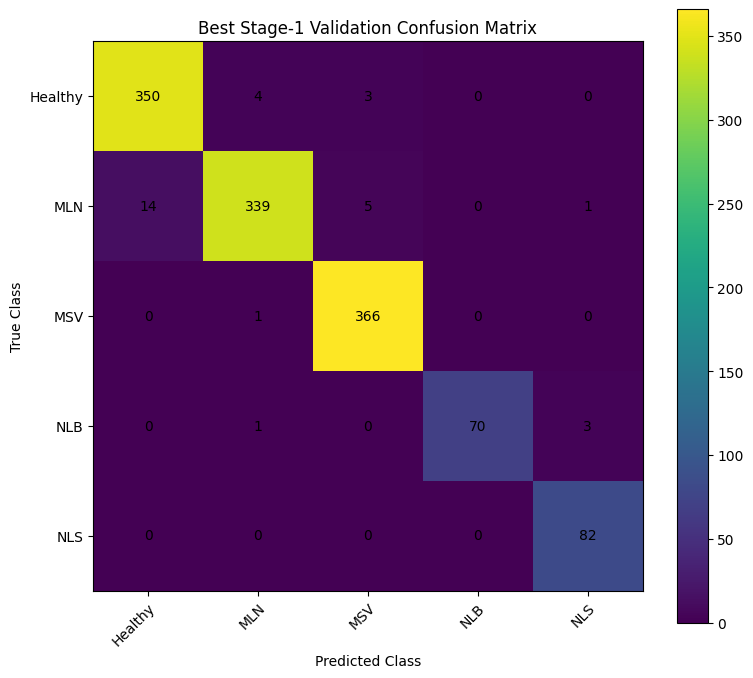


NLB ↔ NLS CONFUSION
NLB incorrectly predicted as NLS : 3
NLS incorrectly predicted as NLB : 0
Total NLB ↔ NLS confusion        : 3


In [14]:
# ============================================================
# VALIDATION ANALYSIS — BEST STAGE-1 CHECKPOINT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Run inference on COMPLETE validation set
# ------------------------------------------------------------

all_labels = []
all_preds = []
all_probs = []

model.eval()

print("=" * 70)
print("RUNNING VALIDATION INFERENCE")
print("=" * 70)

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = probabilities.argmax(
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_probs.extend(
            probabilities.cpu().numpy()
        )


all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(all_labels) == 1239
assert len(all_preds) == 1239
assert all_probs.shape == (1239, 5)


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_preds
)

balanced_acc = balanced_accuracy_score(
    all_labels,
    all_preds
)

macro_precision = precision_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)


print("\n" + "=" * 70)
print("BEST STAGE-1 — VALIDATION PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy           : {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Balanced Accuracy  : {balanced_acc:.4f} "
    f"({balanced_acc * 100:.2f}%)"
)

print(
    f"Macro Precision    : {macro_precision:.4f}"
)

print(
    f"Macro Recall       : {macro_recall:.4f}"
)

print(
    f"Macro F1           : {macro_f1:.4f}"
)

print(
    f"\nCorrect predictions: "
    f"{(all_labels == all_preds).sum():,} / {len(all_labels):,}"
)

print(
    f"Wrong predictions  : "
    f"{(all_labels != all_preds).sum():,}"
)


# ------------------------------------------------------------
# Per-class report
# ------------------------------------------------------------

class_names = val_dataset.classes

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_rows = []

for class_name in class_names:

    r = report[class_name]

    class_rows.append({

        "Class": class_name,

        "Precision": r["precision"],

        "Recall": r["recall"],

        "F1": r["f1-score"],

        "Support": int(r["support"])
    })


class_df = pd.DataFrame(
    class_rows
)

print("\n" + "=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

print(
    class_df.to_string(
        index=False,
        formatters={
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_preds
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX — RAW COUNTS")
print("=" * 70)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"True {x}"
        for x in class_names
    ],
    columns=[
        f"Pred {x}"
        for x in class_names
    ]
)

print(cm_df)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(len(class_names))
)

ax.set_yticks(
    np.arange(len(class_names))
)

ax.set_xticklabels(
    class_names
)

ax.set_yticklabels(
    class_names
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

ax.set_xlabel(
    "Predicted Class"
)

ax.set_ylabel(
    "True Class"
)

ax.set_title(
    "Best Stage-1 Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Specific NLB / NLS confusion
# ------------------------------------------------------------

nlb_idx = class_names.index("NLB")
nls_idx = class_names.index("NLS")

nlb_to_nls = cm[
    nlb_idx,
    nls_idx
]

nls_to_nlb = cm[
    nls_idx,
    nlb_idx
]

print("\n" + "=" * 70)
print("NLB ↔ NLS CONFUSION")
print("=" * 70)

print(
    f"NLB incorrectly predicted as NLS : "
    f"{nlb_to_nls}"
)

print(
    f"NLS incorrectly predicted as NLB : "
    f"{nls_to_nlb}"
)

print(
    f"Total NLB ↔ NLS confusion        : "
    f"{nlb_to_nls + nls_to_nlb}"
)

In [15]:
# ============================================================
# NEXT CELL — ANALYZE ALL VALIDATION MISTAKES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

class_names = val_dataset.classes

# ------------------------------------------------------------
# Find incorrect predictions
# ------------------------------------------------------------

wrong_indices = np.where(
    all_labels != all_preds
)[0]

print("=" * 75)
print("VALIDATION ERROR ANALYSIS")
print("=" * 75)

print(f"\nTotal validation images : {len(val_dataset)}")
print(f"Total mistakes          : {len(wrong_indices)}")


# ------------------------------------------------------------
# Build error table
# ------------------------------------------------------------

error_records = []

for idx in wrong_indices:

    true_idx = int(all_labels[idx])
    pred_idx = int(all_preds[idx])

    confidence = float(
        all_probs[idx][pred_idx]
    )

    true_probability = float(
        all_probs[idx][true_idx]
    )

    image_path, _ = val_dataset.samples[idx]

    error_records.append({
        "Dataset_Index": idx,
        "Filename": image_path.split("/")[-1],
        "True": class_names[true_idx],
        "Predicted": class_names[pred_idx],
        "Pred_Confidence": confidence,
        "True_Probability": true_probability,
        "Path": image_path
    })


error_df = pd.DataFrame(error_records)

# Highest-confidence mistakes first
error_df = error_df.sort_values(
    "Pred_Confidence",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Print table
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ALL MISCLASSIFICATIONS — HIGHEST CONFIDENCE FIRST")
print("=" * 75)

display(
    error_df[
        [
            "Filename",
            "True",
            "Predicted",
            "Pred_Confidence",
            "True_Probability"
        ]
    ].style.format({
        "Pred_Confidence": "{:.4f}",
        "True_Probability": "{:.4f}"
    })
)


# ------------------------------------------------------------
# Error-pair summary
# ------------------------------------------------------------

pair_summary = (
    error_df
    .groupby(
        ["True", "Predicted"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        "Count",
        ascending=False
    )
)

print("\n" + "=" * 75)
print("ERROR PAIRS")
print("=" * 75)

display(pair_summary)


# ------------------------------------------------------------
# Confidence summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("WRONG-PREDICTION CONFIDENCE")
print("=" * 75)

print(
    f"Mean   : {error_df['Pred_Confidence'].mean():.4f}"
)

print(
    f"Median : {error_df['Pred_Confidence'].median():.4f}"
)

print(
    f"Min    : {error_df['Pred_Confidence'].min():.4f}"
)

print(
    f"Max    : {error_df['Pred_Confidence'].max():.4f}"
)

print(
    "\nWrong predictions with confidence >= 90% :",
    (error_df["Pred_Confidence"] >= 0.90).sum()
)

print(
    "Wrong predictions with confidence >= 80% :",
    (error_df["Pred_Confidence"] >= 0.80).sum()
)


# ------------------------------------------------------------
# Display ALL 32 incorrect images
# ------------------------------------------------------------

n_errors = len(error_df)

cols = 4
rows = int(np.ceil(n_errors / cols))

plt.figure(
    figsize=(16, rows * 4)
)

for i, row in error_df.iterrows():

    img = Image.open(
        row["Path"]
    ).convert("RGB")

    plt.subplot(
        rows,
        cols,
        i + 1
    )

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        f"True: {row['True']}\n"
        f"Pred: {row['Predicted']}\n"
        f"Confidence: {row['Pred_Confidence']*100:.1f}%",
        fontsize=10
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Save error report locally
# ------------------------------------------------------------

ERROR_REPORT_PATH = (
    "/content/stage1_validation_errors.csv"
)

error_df.to_csv(
    ERROR_REPORT_PATH,
    index=False
)

print("\n✓ Error report saved:")
print(ERROR_REPORT_PATH)

Output hidden; open in https://colab.research.google.com to view.

In [16]:
# ============================================================
# SHOW ONLY MLN → HEALTHY ERRORS
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

mln_healthy = error_df[
    (error_df["True"] == "MLN") &
    (error_df["Predicted"] == "Healthy")
].reset_index(drop=True)

print("=" * 70)
print("MLN → HEALTHY ERRORS")
print("=" * 70)

print(f"Images: {len(mln_healthy)}")

cols = 3
rows = int(np.ceil(len(mln_healthy) / cols))

plt.figure(figsize=(15, rows * 5))

for i, row in mln_healthy.iterrows():

    img = Image.open(row["Path"]).convert("RGB")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"{i+1}. {row['Filename']}\n"
        f"Label: MLN | Pred: Healthy\n"
        f"Confidence: {row['Pred_Confidence']*100:.1f}%",
        fontsize=10
    )

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [17]:
# ============================================================
# STAGE 2 — FINE-TUNING SETUP
# Unfreeze ResNet layer4 only
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("STAGE 2 — FINE-TUNING SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Freeze complete backbone first
# ------------------------------------------------------------

for param in model.backbone.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# 2. Unfreeze ResNet layer4
#
# backbone structure:
# 0 = conv1
# 1 = bn1
# 2 = relu
# 3 = maxpool
# 4 = layer1
# 5 = layer2
# 6 = layer3
# 7 = layer4
# ------------------------------------------------------------

for param in model.backbone[7].parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# 3. Projection / Transformer / Norm / Classifier remain
#    trainable
# ------------------------------------------------------------

for module in [
    model.projection,
    model.transformer,
    model.norm,
    model.classifier
]:
    for param in module.parameters():
        param.requires_grad = True


# ------------------------------------------------------------
# 4. Parameter counts
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = (
    total_params -
    trainable_params
)

layer4_params = sum(
    p.numel()
    for p in model.backbone[7].parameters()
    if p.requires_grad
)

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Frozen parameters    : {frozen_params:,}")

print(
    f"Trainable percentage : "
    f"{100 * trainable_params / total_params:.2f}%"
)

print(
    f"\nResNet layer4 params : "
    f"{layer4_params:,}"
)


# ------------------------------------------------------------
# 5. Loss
# Keep same label smoothing
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.10
)


# ------------------------------------------------------------
# 6. Differential learning rates
#
# Backbone gets smallest LR.
# Classification head gets largest LR.
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(

    [

        # ResNet layer4
        {
            "params": model.backbone[7].parameters(),
            "lr": 1e-5
        },

        # Projection
        {
            "params": model.projection.parameters(),
            "lr": 5e-5
        },

        # Transformer
        {
            "params": model.transformer.parameters(),
            "lr": 5e-5
        },

        # LayerNorm
        {
            "params": model.norm.parameters(),
            "lr": 5e-5
        },

        # Classifier
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }

    ],

    weight_decay=1e-4
)


# ------------------------------------------------------------
# 7. Stage-2 configuration
# ------------------------------------------------------------

STAGE2_MAX_EPOCHS = 8

STAGE2_PATIENCE = 3

GRAD_CLIP = 1.0

STAGE2_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "final_year_project/maize/checkpoints/"
    "maize_hybrid_stage2_best.pth"
)


# ------------------------------------------------------------
# 8. AMP
# ------------------------------------------------------------

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


# ------------------------------------------------------------
# 9. Verify learning rates
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LEARNING RATES")
print("=" * 70)

names = [
    "ResNet layer4",
    "Projection",
    "Transformer",
    "LayerNorm",
    "Classifier"
]

for name, group in zip(
    names,
    optimizer.param_groups
):

    print(
        f"{name:<18}: "
        f"{group['lr']:.1e}"
    )


print("\nStage-2 max epochs :", STAGE2_MAX_EPOCHS)
print("Early-stop patience:", STAGE2_PATIENCE)

print("\nCheckpoint:")
print(STAGE2_CHECKPOINT)

print("\n" + "=" * 70)
print("✓ STAGE 2 SETUP COMPLETE")
print("=" * 70)

STAGE 2 — FINE-TUNING SETUP

Total parameters     : 37,333,061
Trainable parameters : 28,789,765
Frozen parameters    : 8,543,296
Trainable percentage : 77.12%

ResNet layer4 params : 14,964,736

LEARNING RATES
ResNet layer4     : 1.0e-05
Projection        : 5.0e-05
Transformer       : 5.0e-05
LayerNorm         : 5.0e-05
Classifier        : 1.0e-04

Stage-2 max epochs : 8
Early-stop patience: 3

Checkpoint:
/content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage2_best.pth

✓ STAGE 2 SETUP COMPLETE


In [18]:
# ============================================================
# STAGE 2 — RECREATE TRAINING PIPELINE
# ============================================================

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np

IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_WORKERS = 0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# Training augmentation
# Same morphology-preserving augmentation used in Stage 1
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.70, 1.0),
        ratio=(0.80, 1.20)
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    transforms.RandomVerticalFlip(
        p=0.20
    ),

    transforms.RandomRotation(
        degrees=20
    ),

    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.25,
                contrast=0.25,
                saturation=0.20,
                hue=0.03
            )
        ],
        p=0.70
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.2)
            )
        ],
        p=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ------------------------------------------------------------
# Training dataset
# ------------------------------------------------------------

TRAIN_DIR = DATASET_ROOT / "train"

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)


# ------------------------------------------------------------
# Verify exact class mapping
# ------------------------------------------------------------

expected_mapping = {
    "Healthy": 0,
    "MLN": 1,
    "MSV": 2,
    "NLB": 3,
    "NLS": 4
}

assert train_dataset.class_to_idx == expected_mapping
assert len(train_dataset) == 5762


# ------------------------------------------------------------
# Calculate class counts
# ------------------------------------------------------------

targets = np.array(
    train_dataset.targets
)

class_counts = np.bincount(
    targets,
    minlength=len(train_dataset.classes)
)

# Inverse-frequency sample weights
class_weights = (
    len(targets) /
    (
        len(class_counts) *
        class_counts
    )
)

sample_weights = class_weights[
    targets
]


# ------------------------------------------------------------
# Weighted sampler
# ------------------------------------------------------------

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(sample_weights),
    replacement=True
)


# ------------------------------------------------------------
# DataLoader
# ------------------------------------------------------------

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    sampler=sampler,

    num_workers=NUM_WORKERS,

    pin_memory=True
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print("STAGE 2 — TRAINING PIPELINE")
print("=" * 70)

print(f"\nTraining images : {len(train_dataset):,}")
print(f"Training batches: {len(train_loader)}")

print("\nClass counts:")

for i, class_name in enumerate(
    train_dataset.classes
):

    print(
        f"{class_name:<8}: "
        f"{class_counts[i]:,}"
    )


print("\nSampling weights:")

for i, class_name in enumerate(
    train_dataset.classes
):

    print(
        f"{class_name:<8}: "
        f"{class_weights[i]:.4f}"
    )


# ------------------------------------------------------------
# Test one batch
# ------------------------------------------------------------

images, labels = next(
    iter(train_loader)
)

print("\nBatch image shape :", images.shape)
print("Batch label shape :", labels.shape)

assert images.shape[1:] == (
    3,
    256,
    256
)

print("\n✓ STAGE-2 TRAINING LOADER READY")

STAGE 2 — TRAINING PIPELINE

Training images : 5,762
Training batches: 181

Class counts:
Healthy : 1,662
MLN     : 1,671
MSV     : 1,709
NLB     : 341
NLS     : 379

Sampling weights:
Healthy : 0.6934
MLN     : 0.6896
MSV     : 0.6743
NLB     : 3.3795
NLS     : 3.0406

Batch image shape : torch.Size([32, 3, 256, 256])
Batch label shape : torch.Size([32])

✓ STAGE-2 TRAINING LOADER READY


In [19]:
# ============================================================
# STAGE 2 — FINE-TUNING
# ResNet layer4 + Projection + Transformer + Classifier
# ============================================================

import os
import time
import copy
import numpy as np
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

MIXUP_ALPHA = 0.20
MIXUP_PROB = 0.50

STAGE2_MAX_EPOCHS = 8
STAGE2_PATIENCE = 3
GRAD_CLIP = 1.0

STAGE2_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "final_year_project/maize/checkpoints/"
    "maize_hybrid_stage2_best.pth"
)

os.makedirs(
    os.path.dirname(STAGE2_CHECKPOINT),
    exist_ok=True
)


# ------------------------------------------------------------
# MixUp
# ------------------------------------------------------------

def mixup_batch(images, labels, alpha=0.20):

    lam = np.random.beta(alpha, alpha)

    batch_size = images.size(0)

    index = torch.randperm(
        batch_size,
        device=images.device
    )

    mixed_images = (
        lam * images +
        (1.0 - lam) * images[index]
    )

    labels_a = labels
    labels_b = labels[index]

    return (
        mixed_images,
        labels_a,
        labels_b,
        lam
    )


def mixup_loss(
    criterion,
    predictions,
    labels_a,
    labels_b,
    lam
):

    return (
        lam * criterion(predictions, labels_a)
        +
        (1.0 - lam) *
        criterion(predictions, labels_b)
    )


# ------------------------------------------------------------
# Baseline = best Stage-1 Macro-F1
# ------------------------------------------------------------

STAGE1_BEST_F1 = float(
    checkpoint["best_macro_f1"]
)

best_stage2_f1 = -1.0
best_stage2_epoch = 0

epochs_without_improvement = 0

stage2_history = []


print("=" * 75)
print("STAGE 2 — RESNET LAYER4 FINE-TUNING")
print("=" * 75)

print(
    f"\nStage-1 baseline Macro-F1 : "
    f"{STAGE1_BEST_F1:.4f}"
)

print(
    f"Maximum epochs            : "
    f"{STAGE2_MAX_EPOCHS}"
)

print(
    f"Early stopping patience   : "
    f"{STAGE2_PATIENCE}"
)

print(
    f"Training batches / epoch  : "
    f"{len(train_loader)}"
)

print(
    f"Validation images         : "
    f"{len(val_dataset)}"
)

print("\nStarting Stage 2...\n")


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    STAGE2_MAX_EPOCHS + 1
):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    # Keep frozen part of ResNet in evaluation mode.
    #
    # backbone[0:7] =
    # conv1/bn1/relu/maxpool/layer1/layer2/layer3
    #
    # layer4 remains trainable.
    for module in model.backbone[:7]:
        module.eval()

    model.backbone[7].train()

    running_loss = 0.0
    processed_samples = 0


    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{STAGE2_MAX_EPOCHS} [Train]",
        leave=True
    )


    for images, labels in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # Random MixUp
        # ----------------------------------------------------

        use_mixup = (
            np.random.random()
            < MIXUP_PROB
        )

        if use_mixup:

            (
                model_inputs,
                labels_a,
                labels_b,
                lam
            ) = mixup_batch(
                images,
                labels,
                MIXUP_ALPHA
            )

        else:

            model_inputs = images


        # ----------------------------------------------------
        # Forward + loss with AMP
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):

            outputs = model(
                model_inputs
            )

            if use_mixup:

                loss = mixup_loss(
                    criterion,
                    outputs,
                    labels_a,
                    labels_b,
                    lam
                )

            else:

                loss = criterion(
                    outputs,
                    labels
                )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            [
                p
                for p in model.parameters()
                if p.requires_grad
            ],
            GRAD_CLIP
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        batch_size = images.size(0)

        running_loss += (
            loss.item() *
            batch_size
        )

        processed_samples += batch_size

        progress_bar.set_postfix(
            loss=f"{running_loss / processed_samples:.4f}",
            mixup="ON" if use_mixup else "OFF"
        )


    train_loss = (
        running_loss /
        processed_samples
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_running_loss = 0.0

    val_labels = []
    val_preds = []


    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch}/{STAGE2_MAX_EPOCHS} [Val]",
        leave=False
    )


    with torch.inference_mode():

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )


            val_running_loss += (
                loss.item() *
                images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

            val_preds.extend(
                predictions.cpu().numpy()
            )


    val_loss = (
        val_running_loss /
        len(val_dataset)
    )


    # ========================================================
    # METRICS
    # ========================================================

    val_accuracy = accuracy_score(
        val_labels,
        val_preds
    )

    val_precision = precision_score(
        val_labels,
        val_preds,
        average="macro",
        zero_division=0
    )

    val_recall = recall_score(
        val_labels,
        val_preds,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro",
        zero_division=0
    )


    epoch_minutes = (
        time.time() -
        epoch_start
    ) / 60


    stage2_history.append({

        "epoch": epoch,

        "train_loss": train_loss,

        "val_loss": val_loss,

        "val_accuracy": val_accuracy,

        "macro_precision": val_precision,

        "macro_recall": val_recall,

        "macro_f1": val_f1
    })


    # ========================================================
    # PRINT EPOCH RESULT
    # ========================================================

    print("\n" + "=" * 75)

    print(
        f"STAGE 2 — EPOCH "
        f"{epoch}/{STAGE2_MAX_EPOCHS}"
    )

    print("=" * 75)

    print(
        f"Train Loss      : "
        f"{train_loss:.4f}"
    )

    print(
        f"Val Loss        : "
        f"{val_loss:.4f}"
    )

    print(
        f"Val Accuracy    : "
        f"{val_accuracy:.4f} "
        f"({val_accuracy*100:.2f}%)"
    )

    print(
        f"Macro Precision : "
        f"{val_precision:.4f}"
    )

    print(
        f"Macro Recall    : "
        f"{val_recall:.4f}"
    )

    print(
        f"Macro F1        : "
        f"{val_f1:.4f}"
    )

    print(
        f"Time            : "
        f"{epoch_minutes:.2f} min"
    )


    # ========================================================
    # SAVE BEST STAGE-2 CHECKPOINT
    # ========================================================

    if val_f1 > best_stage2_f1:

        best_stage2_f1 = val_f1
        best_stage2_epoch = epoch

        epochs_without_improvement = 0

        torch.save({

            "stage": 2,

            "epoch": epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "best_macro_f1":
                best_stage2_f1,

            "stage1_baseline_macro_f1":
                STAGE1_BEST_F1,

            "class_to_idx":
                train_dataset.class_to_idx,

            "architecture":
                "ResNet50_Transformer_Hybrid",

            "image_size":
                IMAGE_SIZE,

            "history":
                stage2_history,

            "fine_tuned_backbone":
                "ResNet50_layer4",

            "learning_rates": {
                "layer4": 1e-5,
                "projection": 5e-5,
                "transformer": 5e-5,
                "norm": 5e-5,
                "classifier": 1e-4
            }

        }, STAGE2_CHECKPOINT)


        print(
            "\n✓ NEW BEST STAGE-2 CHECKPOINT"
        )

        print(
            f"  Macro-F1: "
            f"{best_stage2_f1:.4f}"
        )

        print(
            f"  Saved to: "
            f"{STAGE2_CHECKPOINT}"
        )


    else:

        epochs_without_improvement += 1

        print(
            f"\nNo Stage-2 improvement: "
            f"{epochs_without_improvement}/"
            f"{STAGE2_PATIENCE}"
        )


    # --------------------------------------------------------
    # Compare against Stage 1
    # --------------------------------------------------------

    difference = (
        val_f1 -
        STAGE1_BEST_F1
    )

    print(
        f"\nDifference vs Stage-1 baseline: "
        f"{difference:+.4f}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >= STAGE2_PATIENCE
    ):

        print("\n" + "=" * 75)

        print(
            "EARLY STOPPING TRIGGERED"
        )

        print("=" * 75)

        break


# ============================================================
# LOAD BEST STAGE-2 MODEL
# ============================================================

print("\n" + "=" * 75)
print("STAGE 2 COMPLETE")
print("=" * 75)

best_stage2_checkpoint = torch.load(
    STAGE2_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    best_stage2_checkpoint[
        "model_state_dict"
    ]
)

model.to(device)
model.eval()


print(
    f"\nBest Stage-2 epoch    : "
    f"{best_stage2_epoch}"
)

print(
    f"Best Stage-2 Macro-F1 : "
    f"{best_stage2_f1:.4f}"
)

print(
    f"Stage-1 Macro-F1      : "
    f"{STAGE1_BEST_F1:.4f}"
)

print(
    f"Difference            : "
    f"{best_stage2_f1 - STAGE1_BEST_F1:+.4f}"
)


if best_stage2_f1 > STAGE1_BEST_F1:

    print(
        "\n✓ Stage 2 exceeded the Stage-1 "
        "validation Macro-F1."
    )

else:

    print(
        "\nStage 2 did not exceed Stage 1."
    )

print(
    "\nBest Stage-2 checkpoint:"
)

print(
    STAGE2_CHECKPOINT
)

STAGE 2 — RESNET LAYER4 FINE-TUNING

Stage-1 baseline Macro-F1 : 0.9740
Maximum epochs            : 8
Early stopping patience   : 3
Training batches / epoch  : 181
Validation images         : 1239

Starting Stage 2...



Epoch 1/8 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch 1/8 [Val]:   0%|          | 0/39 [00:00<?, ?it/s]


STAGE 2 — EPOCH 1/8
Train Loss      : 0.5530
Val Loss        : 0.4846
Val Accuracy    : 0.9621 (96.21%)
Macro Precision : 0.9727
Macro Recall    : 0.9738
Macro F1        : 0.9725
Time            : 8.40 min

✓ NEW BEST STAGE-2 CHECKPOINT
  Macro-F1: 0.9725
  Saved to: /content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage2_best.pth

Difference vs Stage-1 baseline: -0.0015


Epoch 2/8 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

...

Epoch 4/8 [Val]:   0%|          | 0/39 [00:00<?, ?it/s]


STAGE 2 — EPOCH 4/8
Train Loss      : 0.5612
Val Loss        : 0.4686
Val Accuracy    : 0.9709 (97.09%)
Macro Precision : 0.9786
Macro Recall    : 0.9778
Macro F1        : 0.9779
Time            : 7.73 min

No Stage-2 improvement: 2/3

Difference vs Stage-1 baseline: +0.0038


Epoch 5/8 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch 5/8 [Val]:   0%|          | 0/39 [00:00<?, ?it/s]


STAGE 2 — EPOCH 5/8
Train Loss      : 0.5495
Val Loss        : 0.4613
Val Accuracy    : 0.9734 (97.34%)
Macro Precision : 0.9801
Macro Recall    : 0.9816
Macro F1        : 0.9806
Time            : 7.61 min

No Stage-2 improvement: 3/3

Difference vs Stage-1 baseline: +0.0066

EARLY STOPPING TRIGGERED

STAGE 2 COMPLETE

Best Stage-2 epoch    : 2
Best Stage-2 Macro-F1 : 0.9810
Stage-1 Macro-F1      : 0.9740
Difference            : +0.0070

✓ Stage 2 exceeded the Stage-1 validation Macro-F1.

Best Stage-2 checkpoint:
/content/drive/MyDrive/final_year_project/maize/checkpoints/maize_hybrid_stage2_best.pth


ANALYZING BEST STAGE-2 CHECKPOINT

BEST STAGE-2 VALIDATION PERFORMANCE
Accuracy          : 0.9726 (97.26%)
Balanced Accuracy : 0.9811 (98.11%)
Macro Precision   : 0.9813
Macro Recall      : 0.9811
Macro F1          : 0.9810

Correct : 1,205 / 1,239
Wrong   : 34

PER-CLASS PERFORMANCE
  Class Precision Recall     F1  Support
Healthy    0.9510 0.9776 0.9641      357
    MLN    0.9796 0.9359 0.9573      359
    MSV    0.9759 0.9918 0.9838      367
    NLB    1.0000 1.0000 1.0000       74
    NLS    1.0000 1.0000 1.0000       82

CONFUSION MATRIX
              Pred Healthy  Pred MLN  Pred MSV  Pred NLB  Pred NLS
True Healthy           349         4         4         0         0
True MLN                18       336         5         0         0
True MSV                 0         3       364         0         0
True NLB                 0         0         0        74         0
True NLS                 0         0         0         0        82


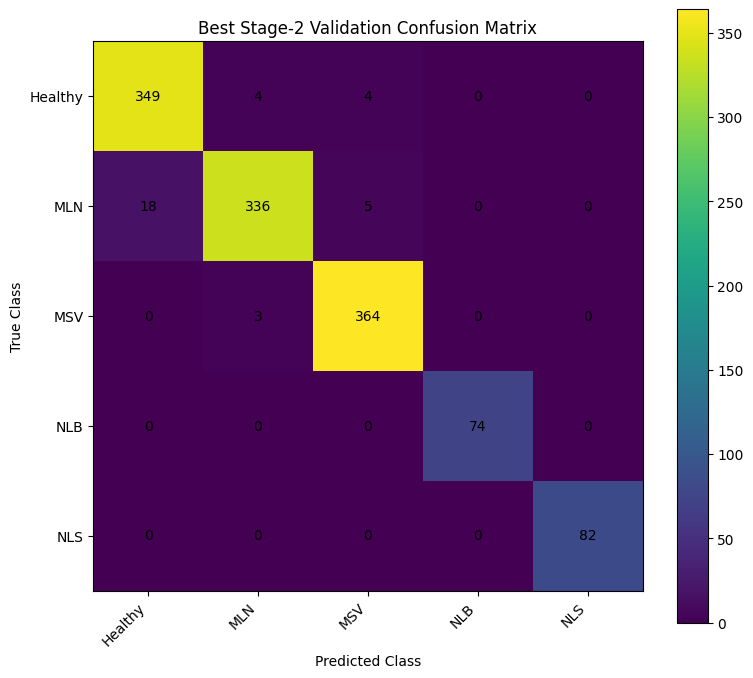


NLB ↔ NLS CONFUSION
NLB → NLS : 0
NLS → NLB : 0
Total     : 0


In [20]:
# ============================================================
# STAGE 2 — BEST CHECKPOINT VALIDATION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

stage2_labels = []
stage2_preds = []
stage2_probs = []

model.eval()

print("=" * 70)
print("ANALYZING BEST STAGE-2 CHECKPOINT")
print("=" * 70)

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        preds = probs.argmax(
            dim=1
        )

        stage2_labels.extend(
            labels.numpy()
        )

        stage2_preds.extend(
            preds.cpu().numpy()
        )

        stage2_probs.extend(
            probs.cpu().numpy()
        )


stage2_labels = np.array(stage2_labels)
stage2_preds = np.array(stage2_preds)
stage2_probs = np.array(stage2_probs)

assert len(stage2_labels) == 1239


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    stage2_labels,
    stage2_preds
)

balanced_acc = balanced_accuracy_score(
    stage2_labels,
    stage2_preds
)

macro_precision = precision_score(
    stage2_labels,
    stage2_preds,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    stage2_labels,
    stage2_preds,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    stage2_labels,
    stage2_preds,
    average="macro",
    zero_division=0
)


print("\n" + "=" * 70)
print("BEST STAGE-2 VALIDATION PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy          : {accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Balanced Accuracy : {balanced_acc:.4f} "
    f"({balanced_acc*100:.2f}%)"
)

print(
    f"Macro Precision   : {macro_precision:.4f}"
)

print(
    f"Macro Recall      : {macro_recall:.4f}"
)

print(
    f"Macro F1          : {macro_f1:.4f}"
)

correct = (
    stage2_labels == stage2_preds
).sum()

wrong = (
    stage2_labels != stage2_preds
).sum()

print(
    f"\nCorrect : {correct:,} / "
    f"{len(stage2_labels):,}"
)

print(
    f"Wrong   : {wrong:,}"
)


# ------------------------------------------------------------
# Per-class metrics
# ------------------------------------------------------------

class_names = val_dataset.classes

report = classification_report(
    stage2_labels,
    stage2_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

rows = []

for cls in class_names:

    r = report[cls]

    rows.append({
        "Class": cls,
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1": r["f1-score"],
        "Support": int(r["support"])
    })

stage2_class_df = pd.DataFrame(rows)


print("\n" + "=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

print(
    stage2_class_df.to_string(
        index=False,
        formatters={
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    stage2_labels,
    stage2_preds
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"True {x}"
        for x in class_names
    ],
    columns=[
        f"Pred {x}"
        for x in class_names
    ]
)

print(cm_df)


# ------------------------------------------------------------
# Plot confusion matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(len(class_names))
)

ax.set_yticks(
    np.arange(len(class_names))
)

ax.set_xticklabels(
    class_names
)

ax.set_yticklabels(
    class_names
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_title(
    "Best Stage-2 Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# NLB ↔ NLS
# ------------------------------------------------------------

nlb = class_names.index("NLB")
nls = class_names.index("NLS")

print("\n" + "=" * 70)
print("NLB ↔ NLS CONFUSION")
print("=" * 70)

print(
    "NLB → NLS :",
    cm[nlb, nls]
)

print(
    "NLS → NLB :",
    cm[nls, nlb]
)

print(
    "Total     :",
    cm[nlb, nls] +
    cm[nls, nlb]
)

In [21]:
# ============================================================
# FINAL TEST — CREATE TEST DATASET + LOADER
# ============================================================

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_WORKERS = 0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# EXACT SAME deterministic preprocessing used for validation
# ------------------------------------------------------------

test_transform = transforms.Compose([

    transforms.Resize(288),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ------------------------------------------------------------
# Test dataset
# ------------------------------------------------------------

TEST_DIR = DATASET_ROOT / "test"

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)


# ------------------------------------------------------------
# Critical verification
# ------------------------------------------------------------

expected_mapping = {
    "Healthy": 0,
    "MLN": 1,
    "MSV": 2,
    "NLB": 3,
    "NLS": 4
}

expected_counts = {
    "Healthy": 357,
    "MLN": 358,
    "MSV": 367,
    "NLB": 74,
    "NLS": 82
}

assert test_dataset.class_to_idx == expected_mapping

assert len(test_dataset) == 1238


# Count each class directly

actual_counts = {
    cls: 0
    for cls in test_dataset.classes
}

for _, label in test_dataset.samples:
    actual_counts[
        test_dataset.classes[label]
    ] += 1


print("=" * 70)
print("FINAL TEST SET VERIFICATION")
print("=" * 70)

print("\nClass mapping:")
print(test_dataset.class_to_idx)

print("\nTest class counts:")

for cls in test_dataset.classes:

    count = actual_counts[cls]
    expected = expected_counts[cls]

    status = (
        "✓"
        if count == expected
        else "✗"
    )

    print(
        f"{status} {cls:<8}: "
        f"{count:,}"
    )

    assert count == expected


print(
    f"\nTotal test images: "
    f"{len(test_dataset):,}"
)


# ------------------------------------------------------------
# Loader
# ------------------------------------------------------------

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=True
)


print(
    f"Test batches      : "
    f"{len(test_loader)}"
)


# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

images, labels = next(
    iter(test_loader)
)

print(
    "\nBatch image shape:",
    images.shape
)

print(
    "Batch label shape:",
    labels.shape
)

assert images.shape[1:] == (
    3,
    256,
    256
)

print("\n" + "=" * 70)
print("✓ UNTOUCHED TEST SET READY")
print("=" * 70)

FINAL TEST SET VERIFICATION

Class mapping:
{'Healthy': 0, 'MLN': 1, 'MSV': 2, 'NLB': 3, 'NLS': 4}

Test class counts:
✓ Healthy : 357
✓ MLN     : 358
✓ MSV     : 367
✓ NLB     : 74
✓ NLS     : 82

Total test images: 1,238
Test batches      : 39

Batch image shape: torch.Size([32, 3, 256, 256])
Batch label shape: torch.Size([32])

✓ UNTOUCHED TEST SET READY


FINAL TEST EVALUATION

Selected checkpoint : Stage 2
Stage-2 epoch       : 2
Validation Macro-F1 : 0.9810

Running inference on 1,238 untouched test images...

FINAL TEST PERFORMANCE
Accuracy          : 0.9774 (97.74%)
Balanced Accuracy : 0.9845 (98.45%)
Macro Precision   : 0.9844
Macro Recall      : 0.9845
Macro F1          : 0.9844

Correct : 1,210 / 1,238
Wrong   : 28

PER-CLASS TEST PERFORMANCE
  Class Precision Recall     F1  Support
Healthy    0.9722 0.9804 0.9763      357
    MLN    0.9637 0.9637 0.9637      358
    MSV    0.9863 0.9782 0.9822      367
    NLB    1.0000 1.0000 1.0000       74
    NLS    1.0000 1.0000 1.0000       82

TEST CONFUSION MATRIX
              Pred Healthy  Pred MLN  Pred MSV  Pred NLB  Pred NLS
True Healthy           350         5         2         0         0
True MLN                10       345         3         0         0
True MSV                 0         8       359         0         0
True NLB                 0         0         0        74     

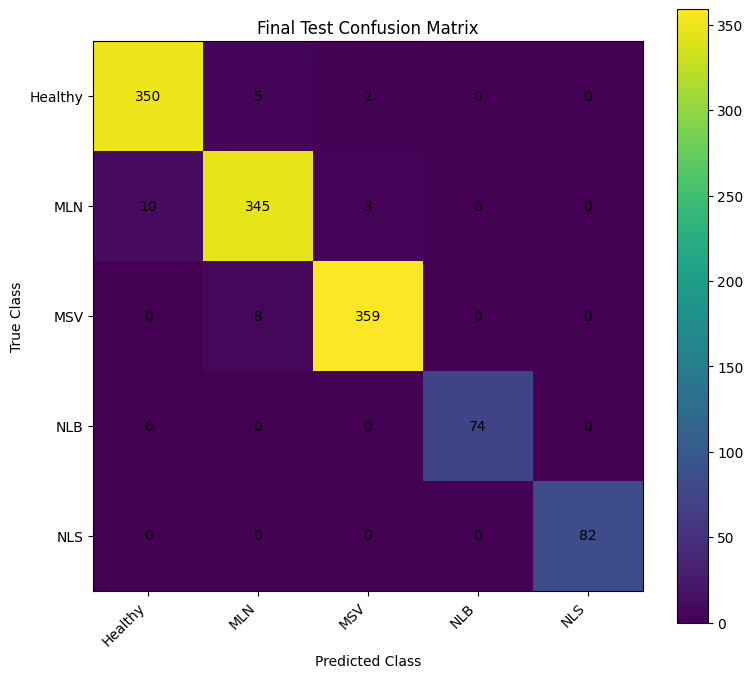


TEST NLB ↔ NLS CONFUSION
NLB → NLS : 0
NLS → NLB : 0
Total     : 0


In [22]:
# ============================================================
# FINAL TEST EVALUATION
# Selected model: Stage-2 Epoch-2 checkpoint
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ------------------------------------------------------------
# Ensure BEST Stage-2 checkpoint is loaded
# ------------------------------------------------------------

best_stage2_checkpoint = torch.load(
    STAGE2_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    best_stage2_checkpoint[
        "model_state_dict"
    ]
)

model.to(device)
model.eval()


print("=" * 75)
print("FINAL TEST EVALUATION")
print("=" * 75)

print(
    "\nSelected checkpoint : Stage 2"
)

print(
    "Stage-2 epoch       :",
    best_stage2_checkpoint["epoch"]
)

print(
    "Validation Macro-F1 :",
    f'{best_stage2_checkpoint["best_macro_f1"]:.4f}'
)

print(
    "\nRunning inference on "
    f"{len(test_dataset):,} untouched test images..."
)


# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

test_labels = []
test_preds = []
test_probs = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = probabilities.argmax(
            dim=1
        )

        test_labels.extend(
            labels.numpy()
        )

        test_preds.extend(
            predictions.cpu().numpy()
        )

        test_probs.extend(
            probabilities.cpu().numpy()
        )


test_labels = np.array(test_labels)
test_preds = np.array(test_preds)
test_probs = np.array(test_probs)


assert len(test_labels) == 1238
assert test_probs.shape == (1238, 5)


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    test_labels,
    test_preds
)

test_balanced_accuracy = balanced_accuracy_score(
    test_labels,
    test_preds
)

test_macro_precision = precision_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)


correct = (
    test_labels == test_preds
).sum()

wrong = (
    test_labels != test_preds
).sum()


print("\n" + "=" * 75)
print("FINAL TEST PERFORMANCE")
print("=" * 75)

print(
    f"Accuracy          : "
    f"{test_accuracy:.4f} "
    f"({test_accuracy*100:.2f}%)"
)

print(
    f"Balanced Accuracy : "
    f"{test_balanced_accuracy:.4f} "
    f"({test_balanced_accuracy*100:.2f}%)"
)

print(
    f"Macro Precision   : "
    f"{test_macro_precision:.4f}"
)

print(
    f"Macro Recall      : "
    f"{test_macro_recall:.4f}"
)

print(
    f"Macro F1          : "
    f"{test_macro_f1:.4f}"
)

print(
    f"\nCorrect : "
    f"{correct:,} / {len(test_labels):,}"
)

print(
    f"Wrong   : "
    f"{wrong:,}"
)


# ------------------------------------------------------------
# Per-class report
# ------------------------------------------------------------

class_names = test_dataset.classes

report = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

rows = []

for cls in class_names:

    r = report[cls]

    rows.append({
        "Class": cls,
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1": r["f1-score"],
        "Support": int(r["support"])
    })


test_class_df = pd.DataFrame(rows)


print("\n" + "=" * 75)
print("PER-CLASS TEST PERFORMANCE")
print("=" * 75)

print(
    test_class_df.to_string(
        index=False,
        formatters={
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

test_cm = confusion_matrix(
    test_labels,
    test_preds
)

print("\n" + "=" * 75)
print("TEST CONFUSION MATRIX")
print("=" * 75)

test_cm_df = pd.DataFrame(
    test_cm,
    index=[
        f"True {x}"
        for x in class_names
    ],
    columns=[
        f"Pred {x}"
        for x in class_names
    ]
)

print(test_cm_df)


# ------------------------------------------------------------
# Plot confusion matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7)
)

im = ax.imshow(
    test_cm
)

ax.set_xticks(
    np.arange(len(class_names))
)

ax.set_yticks(
    np.arange(len(class_names))
)

ax.set_xticklabels(
    class_names
)

ax.set_yticklabels(
    class_names
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(test_cm.shape[0]):

    for j in range(test_cm.shape[1]):

        ax.text(
            j,
            i,
            str(test_cm[i, j]),
            ha="center",
            va="center"
        )

ax.set_xlabel(
    "Predicted Class"
)

ax.set_ylabel(
    "True Class"
)

ax.set_title(
    "Final Test Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# NLB ↔ NLS confusion
# ------------------------------------------------------------

nlb_idx = class_names.index("NLB")
nls_idx = class_names.index("NLS")

print("\n" + "=" * 75)
print("TEST NLB ↔ NLS CONFUSION")
print("=" * 75)

print(
    "NLB → NLS :",
    test_cm[
        nlb_idx,
        nls_idx
    ]
)

print(
    "NLS → NLB :",
    test_cm[
        nls_idx,
        nlb_idx
    ]
)

print(
    "Total     :",
    test_cm[nlb_idx, nls_idx]
    +
    test_cm[nls_idx, nlb_idx]
)

In [23]:
# ============================================================
# GRAD-CAM — STEP 1
# VERIFY MODEL + TARGET CONVOLUTIONAL LAYER
# ============================================================

import torch
import torch.nn as nn

print("=" * 75)
print("GRAD-CAM — MODEL VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# Keep final selected classifier loaded
# ------------------------------------------------------------

model.to(device)
model.eval()

for param in model.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# ResNet structure
#
# backbone[7] = layer4
# layer4[-1]  = final Bottleneck block
# conv3       = final convolution in that block
# ------------------------------------------------------------

target_layer = model.backbone[7][-1].conv3

print("\nSelected Grad-CAM target layer:")
print(target_layer)


# ------------------------------------------------------------
# Verify that the target layer produces spatial features
# ------------------------------------------------------------

captured_shape = None

def shape_hook(module, inputs, output):
    global captured_shape
    captured_shape = tuple(output.shape)


hook = target_layer.register_forward_hook(
    shape_hook
)


# Use one TEST image only for structural verification

image, label = test_dataset[0]

x = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(x)

hook.remove()


print("\nInput shape:")
print(tuple(x.shape))

print("\nTarget-layer activation shape:")
print(captured_shape)

print("\nModel output shape:")
print(tuple(output.shape))

print("\nTrue class:")
print(test_dataset.classes[label])

print("\nPredicted class:")
print(
    test_dataset.classes[
        output.argmax(dim=1).item()
    ]
)


# ------------------------------------------------------------
# Critical checks
# ------------------------------------------------------------

assert captured_shape is not None

assert captured_shape[0] == 1

assert captured_shape[1] == 2048

assert captured_shape[2:] == (8, 8)

assert output.shape == (1, 5)


print("\n" + "=" * 75)
print("✓ GRAD-CAM TARGET LAYER VERIFIED")
print("=" * 75)

print(
    "\nExpected Grad-CAM feature map: "
    "2048 channels × 8 × 8 spatial grid"
)

GRAD-CAM — MODEL VERIFICATION

Selected Grad-CAM target layer:
Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)

Input shape:
(1, 3, 256, 256)

Target-layer activation shape:
(1, 2048, 8, 8)

Model output shape:
(1, 5)

True class:
Healthy

Predicted class:
Healthy

✓ GRAD-CAM TARGET LAYER VERIFIED

Expected Grad-CAM feature map: 2048 channels × 8 × 8 spatial grid


In [24]:
# ============================================================
# GRAD-CAM — STEP 2
# IMPLEMENT GRAD-CAM FOR HYBRID RESNET50 + TRANSFORMER
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np


class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        # Capture forward activations
        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )


    def _forward_hook(self, module, inputs, output):

        self.activations = output

        # Register gradient hook directly on activation tensor
        if output.requires_grad:

            output.register_hook(
                self._save_gradient
            )


    def _save_gradient(self, grad):

        self.gradients = grad


    def generate(self, image_tensor, target_class=None):

        self.model.eval()

        self.activations = None
        self.gradients = None

        # ----------------------------------------------------
        # Gradients are required through the computation graph.
        # Model parameters remain frozen.
        # ----------------------------------------------------

        image_tensor = (
            image_tensor
            .clone()
            .detach()
            .to(device)
        )

        image_tensor.requires_grad_(True)

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        logits = self.model(
            image_tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )


        # ----------------------------------------------------
        # Choose class
        # ----------------------------------------------------

        if target_class is None:

            target_class = (
                logits.argmax(
                    dim=1
                ).item()
            )


        # ----------------------------------------------------
        # Backward from TARGET CLASS LOGIT
        # ----------------------------------------------------

        self.model.zero_grad(
            set_to_none=True
        )

        target_score = logits[
            0,
            target_class
        ]

        target_score.backward()


        # ----------------------------------------------------
        # Verify hooks captured tensors
        # ----------------------------------------------------

        if self.activations is None:

            raise RuntimeError(
                "Grad-CAM activations were not captured."
            )

        if self.gradients is None:

            raise RuntimeError(
                "Grad-CAM gradients were not captured."
            )


        # ----------------------------------------------------
        # Detach
        #
        # Shape:
        # activations = [1, 2048, 8, 8]
        # gradients   = [1, 2048, 8, 8]
        # ----------------------------------------------------

        activations = (
            self.activations
            .detach()
        )

        gradients = (
            self.gradients
            .detach()
        )


        # ----------------------------------------------------
        # Global-average-pool gradients
        #
        # One importance weight per feature channel
        # ----------------------------------------------------

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )


        # ----------------------------------------------------
        # Weighted combination of feature maps
        # ----------------------------------------------------

        cam = (
            weights *
            activations
        ).sum(
            dim=1,
            keepdim=True
        )


        # Standard Grad-CAM keeps positive evidence
        cam = F.relu(cam)


        # ----------------------------------------------------
        # Resize 8×8 CAM → input resolution
        # ----------------------------------------------------

        cam = F.interpolate(
            cam,
            size=image_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )


        # ----------------------------------------------------
        # Normalize to [0, 1]
        # ----------------------------------------------------

        cam_min = cam.min()
        cam_max = cam.max()

        if (
            cam_max - cam_min
        ).item() > 1e-8:

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = torch.zeros_like(
                cam
            )


        cam = (
            cam[0, 0]
            .cpu()
            .numpy()
        )


        return {
            "cam": cam,

            "logits":
                logits.detach().cpu(),

            "probabilities":
                probabilities.detach().cpu(),

            "predicted_class":
                logits.argmax(
                    dim=1
                ).item(),

            "target_class":
                target_class
        }


    def remove_hooks(self):

        self.forward_handle.remove()


# ============================================================
# INITIALIZE
# ============================================================

gradcam = GradCAM(
    model=model,
    target_layer=target_layer
)


print("=" * 75)
print("GRAD-CAM IMPLEMENTATION READY")
print("=" * 75)


# ============================================================
# SANITY TEST ON ONE TEST IMAGE
# ============================================================

image, true_label = test_dataset[0]

result = gradcam.generate(
    image.unsqueeze(0)
)


cam = result["cam"]

pred_idx = result[
    "predicted_class"
]

confidence = result[
    "probabilities"
][0, pred_idx].item()


print(
    "\nTrue class      :",
    class_names[true_label]
)

print(
    "Predicted class :",
    class_names[pred_idx]
)

print(
    "Confidence      :",
    f"{confidence*100:.2f}%"
)

print(
    "\nGrad-CAM shape  :",
    cam.shape
)

print(
    "Grad-CAM min    :",
    f"{cam.min():.6f}"
)

print(
    "Grad-CAM max    :",
    f"{cam.max():.6f}"
)

print(
    "Grad-CAM mean   :",
    f"{cam.mean():.6f}"
)


# ============================================================
# VALIDATION
# ============================================================

assert cam.shape == (
    256,
    256
)

assert np.isfinite(
    cam
).all()

assert cam.min() >= 0.0

assert cam.max() <= 1.0


print("\n" + "=" * 75)
print("✓ GRAD-CAM SANITY CHECK PASSED")
print("=" * 75)


GRAD-CAM IMPLEMENTATION READY

True class      : Healthy
Predicted class : Healthy
Confidence      : 94.74%

Grad-CAM shape  : (256, 256)
Grad-CAM min    : 0.000000
Grad-CAM max    : 1.000000
Grad-CAM mean   : 0.267284

✓ GRAD-CAM SANITY CHECK PASSED


In [25]:
# ============================================================
# GRAD-CAM — STEP 3
# VISUALIZE CORRECT PREDICTIONS FROM ALL 5 CLASSES
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import random


# ------------------------------------------------------------
# ImageNet de-normalization
# ------------------------------------------------------------

mean = np.array(
    [0.485, 0.456, 0.406]
).reshape(3, 1, 1)

std = np.array(
    [0.229, 0.224, 0.225]
).reshape(3, 1, 1)


def denormalize_image(tensor):

    img = (
        tensor.detach()
        .cpu()
        .numpy()
    )

    img = (
        img * std
        + mean
    )

    img = np.clip(
        img,
        0,
        1
    )

    img = np.transpose(
        img,
        (1, 2, 0)
    )

    return img


# ------------------------------------------------------------
# Find correctly predicted samples
# ------------------------------------------------------------

correct_by_class = {
    i: []
    for i in range(
        len(class_names)
    )
}


model.eval()

print("=" * 75)
print("SEARCHING FOR CORRECT EXAMPLES")
print("=" * 75)


with torch.inference_mode():

    for idx in range(
        len(test_dataset)
    ):

        image, true_label = (
            test_dataset[idx]
        )

        output = model(
            image
            .unsqueeze(0)
            .to(device)
        )

        pred = output.argmax(
            dim=1
        ).item()

        if (
            pred == true_label
            and
            len(
                correct_by_class[
                    true_label
                ]
            ) < 3
        ):

            correct_by_class[
                true_label
            ].append(idx)


        # Stop once every class has 3 examples
        if all(
            len(v) >= 3
            for v in correct_by_class.values()
        ):

            break


print("\nSelected samples:")

for class_idx, indices in (
    correct_by_class.items()
):

    print(
        f"{class_names[class_idx]:<8}: "
        f"{indices}"
    )


# ------------------------------------------------------------
# Generate Grad-CAM visualizations
# ------------------------------------------------------------

for class_idx in range(
    len(class_names)
):

    print("\n" + "=" * 75)
    print(
        f"CLASS: {class_names[class_idx]}"
    )
    print("=" * 75)


    for sample_number, idx in enumerate(
        correct_by_class[class_idx],
        start=1
    ):

        image, true_label = (
            test_dataset[idx]
        )


        # --------------------------------------------
        # Grad-CAM
        # --------------------------------------------

        result = gradcam.generate(
            image.unsqueeze(0)
        )

        cam = result["cam"]

        pred_idx = result[
            "predicted_class"
        ]

        confidence = result[
            "probabilities"
        ][0, pred_idx].item()


        # --------------------------------------------
        # Recover displayable RGB image
        # --------------------------------------------

        original = denormalize_image(
            image
        )


        # --------------------------------------------
        # Plot
        # --------------------------------------------

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(13, 4)
        )


        # Original
        axes[0].imshow(
            original
        )

        axes[0].set_title(
            "Original"
        )

        axes[0].axis("off")


        # CAM
        heat = axes[1].imshow(
            cam,
            cmap="jet",
            vmin=0,
            vmax=1
        )

        axes[1].set_title(
            "Grad-CAM"
        )

        axes[1].axis("off")


        # Overlay
        axes[2].imshow(
            original
        )

        axes[2].imshow(
            cam,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        axes[2].set_title(
            f"Overlay\n"
            f"True: {class_names[true_label]} | "
            f"Pred: {class_names[pred_idx]}\n"
            f"Confidence: {confidence*100:.2f}%"
        )

        axes[2].axis("off")


        fig.colorbar(
            heat,
            ax=axes,
            fraction=0.02,
            pad=0.02
        )

        plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [26]:
# ============================================================
# GRAD-CAM — STEP 4
# RANDOM CORRECT TEST SAMPLES
# 5 samples per class — fixed seed for reproducibility
# ============================================================

import random
import numpy as np
import matplotlib.pyplot as plt
import torch


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

RANDOM_SEED = 42
SAMPLES_PER_CLASS = 5

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


# ------------------------------------------------------------
# Use predictions already generated during FINAL TEST
#
# test_labels
# test_preds
# test_probs
#
# These correspond to test_dataset because:
# test_loader had shuffle=False
# ------------------------------------------------------------

assert len(test_labels) == len(test_dataset)
assert len(test_preds) == len(test_dataset)


# ------------------------------------------------------------
# Collect all CORRECT indices by class
# ------------------------------------------------------------

correct_indices_by_class = {}

for class_idx, class_name in enumerate(class_names):

    indices = np.where(
        (test_labels == class_idx)
        &
        (test_preds == class_idx)
    )[0]

    correct_indices_by_class[
        class_idx
    ] = indices.tolist()


print("=" * 80)
print("RANDOM GRAD-CAM SAMPLE SELECTION")
print("=" * 80)

print(
    f"\nRandom seed       : {RANDOM_SEED}"
)

print(
    f"Samples per class : {SAMPLES_PER_CLASS}"
)


# ------------------------------------------------------------
# Randomly select 5 from each class
# ------------------------------------------------------------

random_samples = {}

for class_idx, class_name in enumerate(class_names):

    available = correct_indices_by_class[
        class_idx
    ]

    assert len(available) >= SAMPLES_PER_CLASS

    selected = random.sample(
        available,
        SAMPLES_PER_CLASS
    )

    random_samples[
        class_idx
    ] = selected

    print(
        f"\n{class_name:<8}"
        f" correct available: {len(available):>3}"
        f" | selected: {selected}"
    )


# ------------------------------------------------------------
# Visualize
# ------------------------------------------------------------

for class_idx, class_name in enumerate(class_names):

    indices = random_samples[
        class_idx
    ]

    print("\n" + "=" * 80)
    print(
        f"CLASS: {class_name}"
    )
    print("=" * 80)

    fig, axes = plt.subplots(
        SAMPLES_PER_CLASS,
        3,
        figsize=(13, 4 * SAMPLES_PER_CLASS)
    )


    for row, idx in enumerate(indices):

        image, true_label = test_dataset[
            idx
        ]


        # ----------------------------------------------------
        # Generate Grad-CAM
        # ----------------------------------------------------

        result = gradcam.generate(
            image.unsqueeze(0)
        )

        cam = result[
            "cam"
        ]

        pred_idx = result[
            "predicted_class"
        ]

        confidence = result[
            "probabilities"
        ][0, pred_idx].item()


        # ----------------------------------------------------
        # Recover RGB image
        # ----------------------------------------------------

        original = denormalize_image(
            image
        )


        # ----------------------------------------------------
        # ORIGINAL
        # ----------------------------------------------------

        axes[row, 0].imshow(
            original
        )

        axes[row, 0].set_title(
            f"Original\n"
            f"Test index: {idx}"
        )

        axes[row, 0].axis(
            "off"
        )


        # ----------------------------------------------------
        # HEATMAP
        # ----------------------------------------------------

        heat = axes[row, 1].imshow(
            cam,
            cmap="jet",
            vmin=0,
            vmax=1
        )

        axes[row, 1].set_title(
            "Grad-CAM"
        )

        axes[row, 1].axis(
            "off"
        )


        # ----------------------------------------------------
        # OVERLAY
        # ----------------------------------------------------

        axes[row, 2].imshow(
            original
        )

        axes[row, 2].imshow(
            cam,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        axes[row, 2].set_title(
            f"True: {class_names[true_label]} | "
            f"Pred: {class_names[pred_idx]}\n"
            f"Confidence: {confidence*100:.2f}%"
        )

        axes[row, 2].axis(
            "off"
        )


    plt.suptitle(
        f"{class_name} — "
        f"Random Correct Predictions",
        fontsize=16,
        y=1.002
    )

    plt.tight_layout()

    plt.show()


print("\n" + "=" * 80)
print("✓ RANDOM GRAD-CAM ANALYSIS COMPLETE")
print("=" * 80)

print(
    "\nTotal visualized:",
    len(class_names)
    * SAMPLES_PER_CLASS
)

print(
    "Selection seed:",
    RANDOM_SEED
)

Output hidden; open in https://colab.research.google.com to view.

In [27]:
# ============================================================
# GRAD-CAM — STEP 5
# IDENTIFY ALL MISCLASSIFIED TEST IMAGES
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Find errors
# ------------------------------------------------------------

error_indices = np.where(
    test_labels != test_preds
)[0]

assert len(error_indices) == 28


# ------------------------------------------------------------
# Build error table
# ------------------------------------------------------------

error_records = []

for idx in error_indices:

    true_idx = int(
        test_labels[idx]
    )

    pred_idx = int(
        test_preds[idx]
    )

    pred_confidence = float(
        test_probs[
            idx,
            pred_idx
        ]
    )

    true_probability = float(
        test_probs[
            idx,
            true_idx
        ]
    )

    margin = (
        pred_confidence
        -
        true_probability
    )

    image_path = (
        test_dataset.samples[idx][0]
    )

    error_records.append({

        "Test_Index":
            int(idx),

        "True_Class":
            class_names[true_idx],

        "Predicted_Class":
            class_names[pred_idx],

        "Pred_Confidence":
            pred_confidence,

        "True_Class_Prob":
            true_probability,

        "Probability_Margin":
            margin,

        "Filename":
            image_path.split("/")[-1]
    })


error_df = pd.DataFrame(
    error_records
)


# ------------------------------------------------------------
# Sort by prediction confidence
# ------------------------------------------------------------

error_df = (
    error_df
    .sort_values(
        "Pred_Confidence",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 90)
print("FINAL TEST — MISCLASSIFICATION ANALYSIS")
print("=" * 90)

print(
    f"\nTotal test images : "
    f"{len(test_dataset):,}"
)

print(
    f"Correct           : "
    f"{(test_labels == test_preds).sum():,}"
)

print(
    f"Misclassified     : "
    f"{len(error_indices):,}"
)


print("\n" + "=" * 90)
print("ERROR TYPES")
print("=" * 90)

error_type_counts = (
    error_df
    .groupby(
        [
            "True_Class",
            "Predicted_Class"
        ]
    )
    .size()
    .reset_index(
        name="Count"
    )
)

print(
    error_type_counts.to_string(
        index=False
    )
)


print("\n" + "=" * 90)
print("ALL 28 ERRORS — HIGHEST CONFIDENCE FIRST")
print("=" * 90)

display_df = error_df.copy()

display_df[
    "Pred_Confidence"
] = (
    display_df[
        "Pred_Confidence"
    ] * 100
)

display_df[
    "True_Class_Prob"
] = (
    display_df[
        "True_Class_Prob"
    ] * 100
)

display_df[
    "Probability_Margin"
] = (
    display_df[
        "Probability_Margin"
    ] * 100
)


print(
    display_df[
        [
            "Test_Index",
            "True_Class",
            "Predicted_Class",
            "Pred_Confidence",
            "True_Class_Prob",
            "Probability_Margin",
            "Filename"
        ]
    ].to_string(
        index=False,
        formatters={
            "Pred_Confidence":
                "{:.2f}%".format,

            "True_Class_Prob":
                "{:.2f}%".format,

            "Probability_Margin":
                "{:.2f}%".format
        }
    )
)


print("\n" + "=" * 90)
print("✓ ERROR LIST READY FOR GRAD-CAM")
print("=" * 90)

FINAL TEST — MISCLASSIFICATION ANALYSIS

Total test images : 1,238
Correct           : 1,210
Misclassified     : 28

ERROR TYPES
True_Class Predicted_Class  Count
   Healthy             MLN      5
   Healthy             MSV      2
       MLN         Healthy     10
       MLN             MSV      3
       MSV             MLN      8

ALL 28 ERRORS — HIGHEST CONFIDENCE FIRST
 Test_Index True_Class Predicted_Class Pred_Confidence True_Class_Prob Probability_Margin          Filename
        491        MLN         Healthy          94.75%           1.60%             93.15% 1722242125888.jpg
        426        MLN             MSV          94.32%           1.94%             92.38% 1713192244893.jpg
        595        MLN             MSV          93.83%           2.35%             91.48% 1726047200117.jpg
        489        MLN         Healthy          93.69%           2.18%             91.50% 1722005716308.jpg
        452        MLN         Healthy          92.98%           2.72%             90

In [28]:
# ============================================================
# GRAD-CAM — STEP 6
# VISUALIZE ALL 28 MISCLASSIFIED TEST IMAGES
# GROUPED BY ERROR TYPE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# Error groups
# ------------------------------------------------------------

error_groups = (
    error_df
    .groupby(
        ["True_Class", "Predicted_Class"],
        sort=False
    )
)


print("=" * 85)
print("GRAD-CAM — MISCLASSIFIED TEST IMAGES")
print("=" * 85)

total_visualized = 0


# ------------------------------------------------------------
# Visualize each confusion type separately
# ------------------------------------------------------------

for (true_name, pred_name), group in error_groups:

    # Highest-confidence mistakes first
    group = group.sort_values(
        "Pred_Confidence",
        ascending=False
    )

    n = len(group)

    print("\n" + "=" * 85)
    print(
        f"{true_name} → {pred_name} "
        f"({n} images)"
    )
    print("=" * 85)

    fig, axes = plt.subplots(
        n,
        3,
        figsize=(13, 4 * n),
        squeeze=False
    )

    for row, (_, record) in enumerate(
        group.iterrows()
    ):

        idx = int(
            record["Test_Index"]
        )

        image, true_label = (
            test_dataset[idx]
        )

        # ----------------------------------------------------
        # Grad-CAM for the model's PREDICTED class
        # ----------------------------------------------------

        result = gradcam.generate(
            image.unsqueeze(0)
        )

        cam = result["cam"]

        pred_idx = result[
            "predicted_class"
        ]

        confidence = result[
            "probabilities"
        ][0, pred_idx].item()

        true_probability = result[
            "probabilities"
        ][0, true_label].item()


        # ----------------------------------------------------
        # RGB image
        # ----------------------------------------------------

        original = denormalize_image(
            image
        )


        # ----------------------------------------------------
        # Original
        # ----------------------------------------------------

        axes[row, 0].imshow(
            original
        )

        axes[row, 0].set_title(
            f"Original\n"
            f"Index {idx} | "
            f"{record['Filename']}"
        )

        axes[row, 0].axis(
            "off"
        )


        # ----------------------------------------------------
        # Heatmap
        # ----------------------------------------------------

        axes[row, 1].imshow(
            cam,
            cmap="jet",
            vmin=0,
            vmax=1
        )

        axes[row, 1].set_title(
            f"Grad-CAM for\n"
            f"Predicted: "
            f"{class_names[pred_idx]}"
        )

        axes[row, 1].axis(
            "off"
        )


        # ----------------------------------------------------
        # Overlay
        # ----------------------------------------------------

        axes[row, 2].imshow(
            original
        )

        axes[row, 2].imshow(
            cam,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        axes[row, 2].set_title(
            f"TRUE: {class_names[true_label]}  →  "
            f"PRED: {class_names[pred_idx]}\n"
            f"Pred conf: {confidence*100:.2f}% | "
            f"True prob: {true_probability*100:.2f}%"
        )

        axes[row, 2].axis(
            "off"
        )

        total_visualized += 1


    fig.suptitle(
        f"Misclassification: "
        f"{true_name} → {pred_name}",
        fontsize=16,
        y=1.001
    )

    plt.tight_layout()
    plt.show()


print("\n" + "=" * 85)
print("✓ MISCLASSIFICATION GRAD-CAM COMPLETE")
print("=" * 85)

print(
    f"\nTotal error images visualized: "
    f"{total_visualized}"
)

assert total_visualized == 28

Output hidden; open in https://colab.research.google.com to view.

CALIBRATION — BASELINE VALIDATION ANALYSIS

Validation images : 1,239

BASELINE CALIBRATION RESULTS
Accuracy    : 0.9726 (97.26%)
NLL         : 0.153467
Brier Score : 0.051805
ECE         : 0.056711 (5.67%)

CONFIDENCE ANALYSIS
Correct predictions : 1,205
Wrong predictions   : 34

Mean confidence — correct : 92.82%
Mean confidence — wrong   : 84.06%

Minimum confidence — correct : 47.34%
Maximum confidence — wrong   : 94.71%


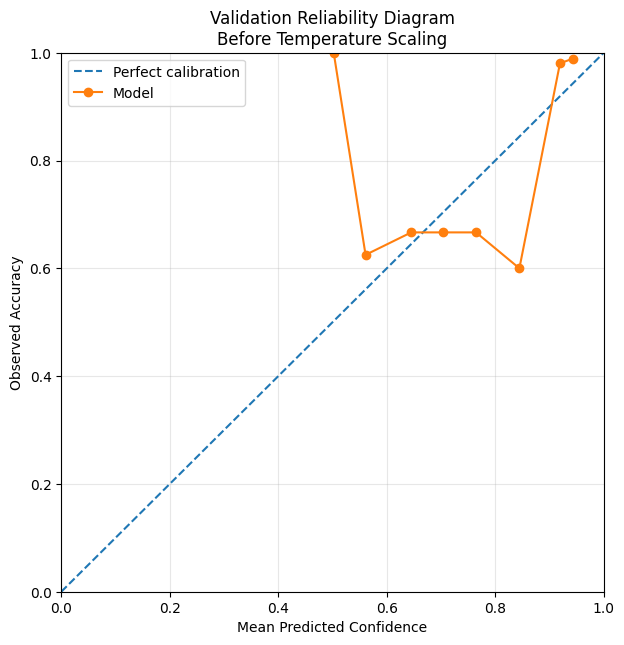


✓ BASELINE CALIBRATION ANALYSIS COMPLETE


In [29]:
# ============================================================
# CALIBRATION — STEP 1
# BASELINE VALIDATION CALIBRATION
#
# Measures:
#   1. Accuracy
#   2. Negative Log-Likelihood (NLL)
#   3. Brier Score
#   4. Expected Calibration Error (ECE)
#   5. Reliability Diagram
#
# IMPORTANT:
# - Validation set only
# - No model weights are changed
# - Test set is NOT used for calibration
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score


# ------------------------------------------------------------
# 1. Collect VALIDATION logits
# ------------------------------------------------------------

model.eval()

val_logits_list = []
val_labels_list = []

print("=" * 75)
print("CALIBRATION — BASELINE VALIDATION ANALYSIS")
print("=" * 75)

print(
    f"\nValidation images : {len(val_dataset):,}"
)

print(
    "Collecting logits..."
)


with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        val_logits_list.append(
            logits.cpu()
        )

        val_labels_list.append(
            labels.cpu()
        )


val_logits = torch.cat(
    val_logits_list,
    dim=0
)

val_cal_labels = torch.cat(
    val_labels_list,
    dim=0
)


assert val_logits.shape == (
    len(val_dataset),
    len(class_names)
)

assert len(val_cal_labels) == len(
    val_dataset
)


# ------------------------------------------------------------
# 2. Convert logits → probabilities
# ------------------------------------------------------------

val_probabilities = F.softmax(
    val_logits,
    dim=1
)

val_confidences, val_predictions = (
    val_probabilities.max(
        dim=1
    )
)


# ------------------------------------------------------------
# 3. Accuracy
# ------------------------------------------------------------

baseline_accuracy = accuracy_score(
    val_cal_labels.numpy(),
    val_predictions.numpy()
)


# ------------------------------------------------------------
# 4. Negative Log-Likelihood
# ------------------------------------------------------------

baseline_nll = F.cross_entropy(
    val_logits,
    val_cal_labels
).item()


# ------------------------------------------------------------
# 5. Multi-class Brier score
#
# Mean squared difference between
# predicted probability vector and
# one-hot target vector.
# ------------------------------------------------------------

one_hot_labels = F.one_hot(
    val_cal_labels,
    num_classes=len(class_names)
).float()

baseline_brier = torch.mean(
    torch.sum(
        (
            val_probabilities
            -
            one_hot_labels
        ) ** 2,
        dim=1
    )
).item()


# ------------------------------------------------------------
# 6. Expected Calibration Error
# ------------------------------------------------------------

def calculate_ece(
    probabilities,
    labels,
    n_bins=15
):

    confidences, predictions = (
        probabilities.max(
            dim=1
        )
    )

    accuracies = (
        predictions == labels
    ).float()

    bin_boundaries = torch.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = torch.tensor(
        0.0
    )

    bin_stats = []

    for i in range(n_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == 0:

            in_bin = (
                (confidences >= lower)
                &
                (confidences <= upper)
            )

        else:

            in_bin = (
                (confidences > lower)
                &
                (confidences <= upper)
            )

        count = in_bin.sum().item()

        if count > 0:

            bin_accuracy = (
                accuracies[in_bin]
                .mean()
                .item()
            )

            bin_confidence = (
                confidences[in_bin]
                .mean()
                .item()
            )

            fraction = (
                count
                /
                len(labels)
            )

            ece += (
                fraction
                *
                abs(
                    bin_accuracy
                    -
                    bin_confidence
                )
            )

            bin_stats.append({
                "lower":
                    float(lower),

                "upper":
                    float(upper),

                "count":
                    int(count),

                "accuracy":
                    bin_accuracy,

                "confidence":
                    bin_confidence
            })


    return (
        float(ece),
        bin_stats
    )


baseline_ece, baseline_bins = (
    calculate_ece(
        val_probabilities,
        val_cal_labels,
        n_bins=15
    )
)


# ------------------------------------------------------------
# 7. Confidence statistics
# ------------------------------------------------------------

correct_mask = (
    val_predictions
    ==
    val_cal_labels
)

wrong_mask = ~correct_mask


correct_confidence = (
    val_confidences[
        correct_mask
    ]
)

wrong_confidence = (
    val_confidences[
        wrong_mask
    ]
)


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BASELINE CALIBRATION RESULTS")
print("=" * 75)

print(
    f"Accuracy    : "
    f"{baseline_accuracy:.4f} "
    f"({baseline_accuracy*100:.2f}%)"
)

print(
    f"NLL         : "
    f"{baseline_nll:.6f}"
)

print(
    f"Brier Score : "
    f"{baseline_brier:.6f}"
)

print(
    f"ECE         : "
    f"{baseline_ece:.6f} "
    f"({baseline_ece*100:.2f}%)"
)


print("\n" + "=" * 75)
print("CONFIDENCE ANALYSIS")
print("=" * 75)

print(
    f"Correct predictions : "
    f"{correct_mask.sum().item():,}"
)

print(
    f"Wrong predictions   : "
    f"{wrong_mask.sum().item():,}"
)

print(
    f"\nMean confidence — correct : "
    f"{correct_confidence.mean().item()*100:.2f}%"
)

print(
    f"Mean confidence — wrong   : "
    f"{wrong_confidence.mean().item()*100:.2f}%"
)

print(
    f"\nMinimum confidence — correct : "
    f"{correct_confidence.min().item()*100:.2f}%"
)

print(
    f"Maximum confidence — wrong   : "
    f"{wrong_confidence.max().item()*100:.2f}%"
)


# ------------------------------------------------------------
# 8. Reliability diagram
# ------------------------------------------------------------

bin_confidences = [
    x["confidence"]
    for x in baseline_bins
]

bin_accuracies = [
    x["accuracy"]
    for x in baseline_bins
]


plt.figure(
    figsize=(7, 7)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    bin_confidences,
    bin_accuracies,
    marker="o",
    label="Model"
)

plt.xlabel(
    "Mean Predicted Confidence"
)

plt.ylabel(
    "Observed Accuracy"
)

plt.title(
    "Validation Reliability Diagram\n"
    "Before Temperature Scaling"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


print("\n" + "=" * 75)
print("✓ BASELINE CALIBRATION ANALYSIS COMPLETE")
print("=" * 75)

TEMPERATURE SCALING

Optimizing temperature...

TEMPERATURE SCALING RESULTS
Optimal Temperature : 0.740006

Prediction changes   : 0
Accuracy             : 97.26% (unchanged)

Before → After
NLL         : 0.153467 → 0.125898
Brier Score : 0.051805 → 0.050209
ECE         : 5.67% → 0.71%

CONFIDENCE AFTER TEMPERATURE SCALING
Mean confidence — correct : 97.82%
Mean confidence — wrong   : 91.23%
Minimum confidence — correct : 54.47%
Maximum confidence — wrong   : 98.76%


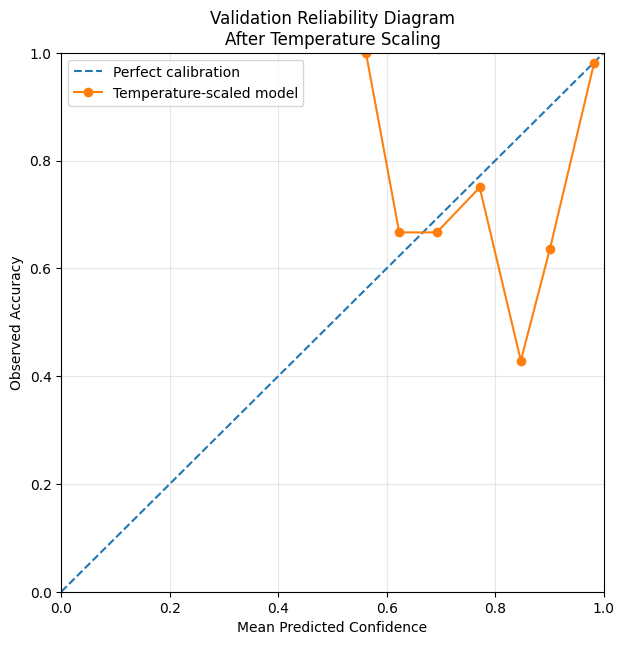


✓ TEMPERATURE SCALING COMPLETE


In [30]:
# ============================================================
# CALIBRATION — STEP 2
# TEMPERATURE SCALING ON VALIDATION LOGITS
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


print("=" * 75)
print("TEMPERATURE SCALING")
print("=" * 75)


# ------------------------------------------------------------
# Keep original tensors on CPU
# ------------------------------------------------------------

logits = val_logits.detach().clone()
labels = val_cal_labels.detach().clone()


# ------------------------------------------------------------
# Optimize log(T), guaranteeing T > 0
# ------------------------------------------------------------

log_temperature = torch.nn.Parameter(
    torch.zeros(1)
)

optimizer_temp = torch.optim.LBFGS(
    [log_temperature],
    lr=0.1,
    max_iter=100,
    line_search_fn="strong_wolfe"
)


def temperature_objective():

    optimizer_temp.zero_grad()

    temperature = torch.exp(
        log_temperature
    )

    scaled_logits = (
        logits / temperature
    )

    loss = F.cross_entropy(
        scaled_logits,
        labels
    )

    loss.backward()

    return loss


print("\nOptimizing temperature...")

optimizer_temp.step(
    temperature_objective
)


temperature = torch.exp(
    log_temperature
).item()


# ------------------------------------------------------------
# Apply fitted temperature
# ------------------------------------------------------------

scaled_logits = (
    logits / temperature
)

scaled_probabilities = F.softmax(
    scaled_logits,
    dim=1
)

scaled_confidences, scaled_predictions = (
    scaled_probabilities.max(
        dim=1
    )
)


# ------------------------------------------------------------
# Verify class predictions DID NOT change
# ------------------------------------------------------------

prediction_changes = (
    scaled_predictions
    !=
    val_predictions
).sum().item()

assert prediction_changes == 0


# ------------------------------------------------------------
# Metrics after calibration
# ------------------------------------------------------------

scaled_nll = F.cross_entropy(
    scaled_logits,
    labels
).item()


scaled_one_hot = F.one_hot(
    labels,
    num_classes=len(class_names)
).float()


scaled_brier = torch.mean(
    torch.sum(
        (
            scaled_probabilities
            -
            scaled_one_hot
        ) ** 2,
        dim=1
    )
).item()


scaled_ece, scaled_bins = (
    calculate_ece(
        scaled_probabilities,
        labels,
        n_bins=15
    )
)


# ------------------------------------------------------------
# Correct vs wrong confidence
# ------------------------------------------------------------

scaled_correct_mask = (
    scaled_predictions
    ==
    labels
)

scaled_wrong_mask = (
    ~scaled_correct_mask
)


scaled_correct_conf = (
    scaled_confidences[
        scaled_correct_mask
    ]
)

scaled_wrong_conf = (
    scaled_confidences[
        scaled_wrong_mask
    ]
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TEMPERATURE SCALING RESULTS")
print("=" * 75)

print(
    f"Optimal Temperature : "
    f"{temperature:.6f}"
)

print(
    f"\nPrediction changes   : "
    f"{prediction_changes}"
)

print(
    f"Accuracy             : "
    f"{baseline_accuracy*100:.2f}% "
    f"(unchanged)"
)


print("\nBefore → After")

print(
    f"NLL         : "
    f"{baseline_nll:.6f} "
    f"→ {scaled_nll:.6f}"
)

print(
    f"Brier Score : "
    f"{baseline_brier:.6f} "
    f"→ {scaled_brier:.6f}"
)

print(
    f"ECE         : "
    f"{baseline_ece*100:.2f}% "
    f"→ {scaled_ece*100:.2f}%"
)


print("\n" + "=" * 75)
print("CONFIDENCE AFTER TEMPERATURE SCALING")
print("=" * 75)

print(
    f"Mean confidence — correct : "
    f"{scaled_correct_conf.mean().item()*100:.2f}%"
)

print(
    f"Mean confidence — wrong   : "
    f"{scaled_wrong_conf.mean().item()*100:.2f}%"
)

print(
    f"Minimum confidence — correct : "
    f"{scaled_correct_conf.min().item()*100:.2f}%"
)

print(
    f"Maximum confidence — wrong   : "
    f"{scaled_wrong_conf.max().item()*100:.2f}%"
)


# ------------------------------------------------------------
# Reliability diagram AFTER scaling
# ------------------------------------------------------------

after_conf = [
    x["confidence"]
    for x in scaled_bins
]

after_acc = [
    x["accuracy"]
    for x in scaled_bins
]


plt.figure(
    figsize=(7, 7)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    after_conf,
    after_acc,
    marker="o",
    label="Temperature-scaled model"
)

plt.xlabel(
    "Mean Predicted Confidence"
)

plt.ylabel(
    "Observed Accuracy"
)

plt.title(
    "Validation Reliability Diagram\n"
    "After Temperature Scaling"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


print("\n" + "=" * 75)
print("✓ TEMPERATURE SCALING COMPLETE")
print("=" * 75)

In [31]:
# ============================================================
# OOD / INPUT VALIDATION — STEP 1
# PREPARE FINAL FROZEN CLASSIFIER
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

# ------------------------------------------------------------
# Final calibration value already fitted on validation set
# ------------------------------------------------------------

CALIBRATION_TEMPERATURE = 0.740006


# ------------------------------------------------------------
# Freeze final classifier
# ------------------------------------------------------------

model.to(device)
model.eval()

for param in model.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# Helper: calibrated prediction
# ------------------------------------------------------------

@torch.inference_mode()
def calibrated_predict(images):

    images = images.to(
        device,
        non_blocking=True
    )

    # Raw model output
    logits = model(images)

    # Temperature-scaled probabilities
    calibrated_probs = F.softmax(
        logits / CALIBRATION_TEMPERATURE,
        dim=1
    )

    confidence, prediction = calibrated_probs.max(
        dim=1
    )

    return {
        "logits": logits.cpu(),
        "probabilities": calibrated_probs.cpu(),
        "confidence": confidence.cpu(),
        "prediction": prediction.cpu()
    }


# ------------------------------------------------------------
# Sanity check using VALIDATION batch
# ------------------------------------------------------------

images, labels = next(
    iter(val_loader)
)

result = calibrated_predict(
    images
)

predictions = result[
    "prediction"
]

confidences = result[
    "confidence"
]


print("=" * 75)
print("OOD / INPUT VALIDATION — BASE MODEL READY")
print("=" * 75)

print(
    f"\nCalibration temperature : "
    f"{CALIBRATION_TEMPERATURE}"
)

print(
    f"Batch size              : "
    f"{len(labels)}"
)

print(
    f"Probability shape       : "
    f"{tuple(result['probabilities'].shape)}"
)

print(
    f"Minimum confidence      : "
    f"{confidences.min().item()*100:.2f}%"
)

print(
    f"Maximum confidence      : "
    f"{confidences.max().item()*100:.2f}%"
)

print("\nSample predictions:")

for i in range(
    min(10, len(labels))
):

    true_name = class_names[
        labels[i].item()
    ]

    pred_name = class_names[
        predictions[i].item()
    ]

    conf = (
        confidences[i].item()
        * 100
    )

    print(
        f"{i+1:>2}. "
        f"True={true_name:<8} "
        f"Pred={pred_name:<8} "
        f"Confidence={conf:6.2f}%"
    )


# ------------------------------------------------------------
# Critical checks
# ------------------------------------------------------------

assert result[
    "probabilities"
].shape[1] == 5

assert torch.allclose(
    result[
        "probabilities"
    ].sum(dim=1),
    torch.ones(
        len(labels)
    ),
    atol=1e-5
)


print("\n" + "=" * 75)
print("✓ FINAL CALIBRATED CLASSIFIER READY FOR OOD WORK")
print("=" * 75)

print(
    "\nIMPORTANT:"
    "\nNo rejection threshold has been applied yet."
    "\nKnown maize images are NOT being rejected."
)

OOD / INPUT VALIDATION — BASE MODEL READY

Calibration temperature : 0.740006
Batch size              : 32
Probability shape       : (32, 5)
Minimum confidence      : 59.38%
Maximum confidence      : 98.82%

Sample predictions:
 1. True=Healthy  Pred=Healthy  Confidence= 98.74%
 2. True=Healthy  Pred=Healthy  Confidence= 98.75%
 3. True=Healthy  Pred=Healthy  Confidence= 98.58%
 4. True=Healthy  Pred=Healthy  Confidence= 98.78%
 5. True=Healthy  Pred=Healthy  Confidence= 98.22%
 6. True=Healthy  Pred=Healthy  Confidence= 97.07%
 7. True=Healthy  Pred=Healthy  Confidence= 98.75%
 8. True=Healthy  Pred=Healthy  Confidence= 98.27%
 9. True=Healthy  Pred=Healthy  Confidence= 97.37%
10. True=Healthy  Pred=MLN      Confidence= 61.91%

✓ FINAL CALIBRATED CLASSIFIER READY FOR OOD WORK

IMPORTANT:
No rejection threshold has been applied yet.
Known maize images are NOT being rejected.


In [32]:
# ============================================================
# OOD — STEP 2
# INSPECT MODEL TO LOCATE THE PRE-CLASSIFIER FEATURE LAYER
# ============================================================

print("=" * 75)
print("OOD — MODEL FEATURE STRUCTURE")
print("=" * 75)

print("\nComplete model:\n")
print(model)

print("\n" + "=" * 75)
print("TOP-LEVEL MODULES")
print("=" * 75)

for name, module in model.named_children():

    print(
        f"\n{name}"
        f"\n{'-' * len(name)}"
    )

    print(module)

print("\n" + "=" * 75)
print("✓ MODEL STRUCTURE DISPLAYED")
print("=" * 75)

OOD — MODEL FEATURE STRUCTURE

Complete model:

ResNetTransformerHybrid(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=T

In [33]:
# ============================================================
# OOD — STEP 3
# EXTRACT 512-D KNOWN-MAIZE VALIDATION EMBEDDINGS
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

model.eval()

# ------------------------------------------------------------
# Capture output of model.norm
#
# model.norm output:
#     [B, 64, 512]
#
# The model then mean-pools the 64 tokens.
# We capture that exact representation and perform the same
# mean pooling ourselves:
#
#     [B, 64, 512] -> [B, 512]
# ------------------------------------------------------------

captured_norm_output = None


def norm_hook(module, inputs, output):
    global captured_norm_output
    captured_norm_output = output.detach()


hook_handle = model.norm.register_forward_hook(
    norm_hook
)


# ------------------------------------------------------------
# Extract validation embeddings
# ------------------------------------------------------------

all_embeddings = []
all_labels = []
all_logits = []
all_confidences = []
all_predictions = []

print("=" * 75)
print("OOD — EXTRACTING KNOWN-MAIZE VALIDATION EMBEDDINGS")
print("=" * 75)


with torch.inference_mode():

    for batch_idx, (images, labels) in enumerate(val_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        # Forward pass
        logits = model(images)

        # Make sure hook captured norm output
        assert captured_norm_output is not None

        norm_features = captured_norm_output

        # Expected:
        # [batch, 64 tokens, 512 dimensions]
        assert norm_features.ndim == 3
        assert norm_features.shape[-1] == 512

        # Same pooling used by our classifier
        embeddings = norm_features.mean(dim=1)

        # L2-normalized copy for cosine-distance OOD later
        embeddings = F.normalize(
            embeddings,
            p=2,
            dim=1
        )

        # Calibrated probabilities
        probs = F.softmax(
            logits / CALIBRATION_TEMPERATURE,
            dim=1
        )

        confidence, prediction = probs.max(
            dim=1
        )

        all_embeddings.append(
            embeddings.cpu()
        )

        all_labels.append(
            labels.cpu()
        )

        all_logits.append(
            logits.cpu()
        )

        all_confidences.append(
            confidence.cpu()
        )

        all_predictions.append(
            prediction.cpu()
        )


# Remove hook after extraction
hook_handle.remove()


# ------------------------------------------------------------
# Combine batches
# ------------------------------------------------------------

val_embeddings = torch.cat(
    all_embeddings,
    dim=0
)

val_labels_ood = torch.cat(
    all_labels,
    dim=0
)

val_logits_ood = torch.cat(
    all_logits,
    dim=0
)

val_confidences_ood = torch.cat(
    all_confidences,
    dim=0
)

val_predictions_ood = torch.cat(
    all_predictions,
    dim=0
)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert val_embeddings.shape == (
    len(val_dataset),
    512
)

assert len(val_labels_ood) == len(val_dataset)

assert torch.isfinite(
    val_embeddings
).all()

norms = torch.linalg.vector_norm(
    val_embeddings,
    dim=1
)


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print(
    f"\nValidation images       : "
    f"{len(val_embeddings):,}"
)

print(
    f"Embedding shape         : "
    f"{tuple(val_embeddings.shape)}"
)

print(
    f"Embedding dtype         : "
    f"{val_embeddings.dtype}"
)

print(
    f"\nL2 norm mean            : "
    f"{norms.mean().item():.6f}"
)

print(
    f"L2 norm min             : "
    f"{norms.min().item():.6f}"
)

print(
    f"L2 norm max             : "
    f"{norms.max().item():.6f}"
)


# ------------------------------------------------------------
# Class counts
# ------------------------------------------------------------

print("\nKNOWN-MAIZE EMBEDDINGS BY CLASS")
print("-" * 45)

for class_idx, class_name in enumerate(class_names):

    count = (
        val_labels_ood == class_idx
    ).sum().item()

    print(
        f"{class_name:<10}: "
        f"{count:,}"
    )


# ------------------------------------------------------------
# Prediction sanity check
# ------------------------------------------------------------

accuracy = (
    val_predictions_ood
    ==
    val_labels_ood
).float().mean().item()

print(
    f"\nValidation accuracy     : "
    f"{accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# Save locally
# ------------------------------------------------------------

np.save(
    "/content/maize_val_embeddings_512.npy",
    val_embeddings.numpy()
)

np.save(
    "/content/maize_val_labels_ood.npy",
    val_labels_ood.numpy()
)

np.save(
    "/content/maize_val_logits_ood.npy",
    val_logits_ood.numpy()
)


print("\nSaved:")

print(
    "/content/maize_val_embeddings_512.npy"
)

print(
    "/content/maize_val_labels_ood.npy"
)

print(
    "/content/maize_val_logits_ood.npy"
)


print("\n" + "=" * 75)
print("✓ KNOWN-MAIZE REFERENCE EMBEDDINGS READY")
print("=" * 75)

OOD — EXTRACTING KNOWN-MAIZE VALIDATION EMBEDDINGS

Validation images       : 1,239
Embedding shape         : (1239, 512)
Embedding dtype         : torch.float32

L2 norm mean            : 1.000000
L2 norm min             : 1.000000
L2 norm max             : 1.000000

KNOWN-MAIZE EMBEDDINGS BY CLASS
---------------------------------------------
Healthy   : 357
MLN       : 359
MSV       : 367
NLB       : 74
NLS       : 82

Validation accuracy     : 97.26%

Saved:
/content/maize_val_embeddings_512.npy
/content/maize_val_labels_ood.npy
/content/maize_val_logits_ood.npy

✓ KNOWN-MAIZE REFERENCE EMBEDDINGS READY


In [34]:
# ============================================================
# OOD — STEP 4
# KNOWN-MAIZE CLASS PROTOTYPE DISTANCE ANALYSIS
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

print("=" * 75)
print("OOD — KNOWN-MAIZE PROTOTYPE DISTANCE ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Build one normalized prototype per maize class
# ------------------------------------------------------------

class_prototypes = []

for class_idx in range(len(class_names)):

    class_mask = (
        val_labels_ood == class_idx
    )

    class_features = val_embeddings[
        class_mask
    ]

    # Mean feature vector for this class
    prototype = class_features.mean(
        dim=0
    )

    # Normalize prototype for cosine similarity
    prototype = F.normalize(
        prototype,
        p=2,
        dim=0
    )

    class_prototypes.append(
        prototype
    )


class_prototypes = torch.stack(
    class_prototypes
)

print(
    "\nPrototype shape:",
    tuple(class_prototypes.shape)
)

assert class_prototypes.shape == (
    len(class_names),
    512
)


# ------------------------------------------------------------
# 2. Cosine similarity of every validation image
#    against every class prototype
#
# val_embeddings already have L2 norm = 1
# prototypes also have L2 norm = 1
# ------------------------------------------------------------

similarity_matrix = (
    val_embeddings
    @
    class_prototypes.T
)

print(
    "Similarity matrix shape:",
    tuple(similarity_matrix.shape)
)


# ------------------------------------------------------------
# 3. Similarity to TRUE class prototype
# ------------------------------------------------------------

row_indices = torch.arange(
    len(val_embeddings)
)

true_class_similarity = similarity_matrix[
    row_indices,
    val_labels_ood
]

true_class_distance = (
    1.0 - true_class_similarity
)


# ------------------------------------------------------------
# 4. Similarity to nearest prototype
#
# Later useful for an image whose true class is unknown.
# ------------------------------------------------------------

nearest_similarity, nearest_class = (
    similarity_matrix.max(
        dim=1
    )
)

nearest_distance = (
    1.0 - nearest_similarity
)


# ------------------------------------------------------------
# 5. Overall known-maize statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TRUE-CLASS COSINE SIMILARITY")
print("=" * 75)

percentiles = [
    0,
    1,
    2.5,
    5,
    10,
    25,
    50,
    75,
    90,
    95,
    97.5,
    99,
    100
]

true_sim_np = (
    true_class_similarity.numpy()
)

for p in percentiles:

    value = np.percentile(
        true_sim_np,
        p
    )

    print(
        f"{p:>5}% : {value:.6f}"
    )


print("\n" + "=" * 75)
print("TRUE-CLASS COSINE DISTANCE")
print("=" * 75)

true_dist_np = (
    true_class_distance.numpy()
)

for p in percentiles:

    value = np.percentile(
        true_dist_np,
        p
    )

    print(
        f"{p:>5}% : {value:.6f}"
    )


# ------------------------------------------------------------
# 6. Per-class statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PER-CLASS TRUE-PROTOTYPE SIMILARITY")
print("=" * 75)

for class_idx, class_name in enumerate(
    class_names
):

    mask = (
        val_labels_ood
        ==
        class_idx
    )

    sims = true_class_similarity[
        mask
    ].numpy()

    print(
        f"\n{class_name}"
    )

    print(
        f"  Count  : {len(sims)}"
    )

    print(
        f"  Mean   : {sims.mean():.6f}"
    )

    print(
        f"  Min    : {sims.min():.6f}"
    )

    print(
        f"  P01    : {np.percentile(sims, 1):.6f}"
    )

    print(
        f"  P05    : {np.percentile(sims, 5):.6f}"
    )

    print(
        f"  Median : {np.median(sims):.6f}"
    )

    print(
        f"  P95    : {np.percentile(sims, 95):.6f}"
    )

    print(
        f"  Max    : {sims.max():.6f}"
    )


# ------------------------------------------------------------
# 7. How often is TRUE class also nearest prototype?
# ------------------------------------------------------------

prototype_accuracy = (
    nearest_class
    ==
    val_labels_ood
).float().mean().item()

print("\n" + "=" * 75)

print(
    "Nearest-prototype agreement with true class:"
)

print(
    f"{prototype_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# 8. Inspect lowest-similarity genuine maize images
#
# Important because these are the known maize images most
# vulnerable to being falsely rejected by an OOD threshold.
# ------------------------------------------------------------

num_show = 20

lowest_indices = torch.argsort(
    true_class_similarity
)[:num_show]


print("\n" + "=" * 75)
print("20 LOWEST-SIMILARITY GENUINE MAIZE VALIDATION IMAGES")
print("=" * 75)

for rank, idx in enumerate(
    lowest_indices,
    start=1
):

    idx = idx.item()

    true_idx = (
        val_labels_ood[idx].item()
    )

    nearest_idx = (
        nearest_class[idx].item()
    )

    print(
        f"{rank:>2}. "
        f"Index={idx:<4} "
        f"True={class_names[true_idx]:<8} "
        f"TrueSim={true_class_similarity[idx]:.6f} "
        f"Nearest={class_names[nearest_idx]:<8} "
        f"NearestSim={nearest_similarity[idx]:.6f}"
    )


# ------------------------------------------------------------
# 9. Save prototype information
# ------------------------------------------------------------

np.save(
    "/content/maize_class_prototypes_512.npy",
    class_prototypes.numpy()
)

np.save(
    "/content/maize_val_true_similarity.npy",
    true_class_similarity.numpy()
)

np.save(
    "/content/maize_val_nearest_similarity.npy",
    nearest_similarity.numpy()
)


print("\nSaved:")
print(
    "/content/maize_class_prototypes_512.npy"
)

print(
    "/content/maize_val_true_similarity.npy"
)

print(
    "/content/maize_val_nearest_similarity.npy"
)


print("\n" + "=" * 75)
print("✓ KNOWN-MAIZE DISTANCE DISTRIBUTION READY")
print("=" * 75)

print(
    "\nNo OOD threshold has been selected yet."
)

OOD — KNOWN-MAIZE PROTOTYPE DISTANCE ANALYSIS

Prototype shape: (5, 512)
Similarity matrix shape: (1239, 5)

TRUE-CLASS COSINE SIMILARITY
    0% : -0.249567
    1% : -0.040831
  2.5% : 0.545124
    5% : 0.903279
   10% : 0.975845
   25% : 0.992813
   50% : 0.996095
   75% : 0.997778
   90% : 0.998803
   95% : 0.999125
 97.5% : 0.999320
   99% : 0.999420
  100% : 0.999705

TRUE-CLASS COSINE DISTANCE
    0% : 0.000295
    1% : 0.000580
  2.5% : 0.000680
    5% : 0.000875
   10% : 0.001197
   25% : 0.002222
   50% : 0.003905
   75% : 0.007187
   90% : 0.024155
   95% : 0.096721
 97.5% : 0.454879
   99% : 1.040831
  100% : 1.249567

PER-CLASS TRUE-PROTOTYPE SIMILARITY

Healthy
  Count  : 357
  Mean   : 0.967861
  Min    : -0.186511
  P01    : 0.062790
  P05    : 0.924120
  Median : 0.995600
  P95    : 0.999118
  Max    : 0.999623

MLN
  Count  : 359
  Mean   : 0.930718
  Min    : -0.249567
  P01    : -0.190693
  P05    : 0.393588
  Median : 0.995716
  P95    : 0.998014
  Max    : 0.998988


In [35]:
# ============================================================
# OOD — STEP 5
# INFERENCE-USABLE KNOWN-MAIZE SCORE DISTRIBUTION
# Nearest class prototype similarity
# ============================================================

import numpy as np
import torch

print("=" * 75)
print("OOD — NEAREST-PROTOTYPE KNOWN-MAIZE DISTRIBUTION")
print("=" * 75)

nearest_sim_np = nearest_similarity.cpu().numpy()

# ------------------------------------------------------------
# 1. Overall distribution
# ------------------------------------------------------------

percentiles = [
    0, 0.5, 1, 2.5, 5, 10,
    25, 50, 75, 90, 95, 97.5, 99, 100
]

print("\nNEAREST-PROTOTYPE COSINE SIMILARITY")
print("-" * 50)

for p in percentiles:
    print(
        f"{p:>5}% : "
        f"{np.percentile(nearest_sim_np, p):.6f}"
    )


# ------------------------------------------------------------
# 2. Per TRUE class
# This tells us whether one genuine maize class naturally
# has lower nearest-prototype similarity than another.
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PER-CLASS NEAREST-PROTOTYPE SIMILARITY")
print("=" * 75)

for class_idx, class_name in enumerate(class_names):

    mask = (
        val_labels_ood == class_idx
    )

    sims = nearest_similarity[
        mask
    ].cpu().numpy()

    print(f"\n{class_name}")

    print(f"  Count  : {len(sims)}")
    print(f"  Mean   : {sims.mean():.6f}")
    print(f"  Min    : {sims.min():.6f}")
    print(
        f"  P01    : "
        f"{np.percentile(sims, 1):.6f}"
    )
    print(
        f"  P05    : "
        f"{np.percentile(sims, 5):.6f}"
    )
    print(
        f"  Median : "
        f"{np.median(sims):.6f}"
    )
    print(
        f"  P95    : "
        f"{np.percentile(sims, 95):.6f}"
    )
    print(f"  Max    : {sims.max():.6f}")


# ------------------------------------------------------------
# 3. Correct vs incorrect classifier predictions
#
# Important:
# Can prototype similarity distinguish classifier errors?
# ------------------------------------------------------------

correct_mask = (
    val_predictions_ood
    ==
    val_labels_ood
)

wrong_mask = ~correct_mask

correct_sims = nearest_similarity[
    correct_mask
].cpu().numpy()

wrong_sims = nearest_similarity[
    wrong_mask
].cpu().numpy()


print("\n" + "=" * 75)
print("CORRECT vs WRONG PREDICTIONS")
print("=" * 75)

print(
    f"\nCorrect predictions : "
    f"{len(correct_sims)}"
)

print(
    f"Mean similarity     : "
    f"{correct_sims.mean():.6f}"
)

print(
    f"Minimum similarity  : "
    f"{correct_sims.min():.6f}"
)

print(
    f"P01 similarity      : "
    f"{np.percentile(correct_sims, 1):.6f}"
)

print(
    f"P05 similarity      : "
    f"{np.percentile(correct_sims, 5):.6f}"
)


print(
    f"\nWrong predictions   : "
    f"{len(wrong_sims)}"
)

print(
    f"Mean similarity     : "
    f"{wrong_sims.mean():.6f}"
)

print(
    f"Minimum similarity  : "
    f"{wrong_sims.min():.6f}"
)

print(
    f"Maximum similarity  : "
    f"{wrong_sims.max():.6f}"
)

print(
    f"Median similarity   : "
    f"{np.median(wrong_sims):.6f}"
)


# ------------------------------------------------------------
# 4. Known-maize retention at exploratory thresholds
#
# IMPORTANT:
# These are NOT final OOD thresholds.
# This only tells us how many genuine validation maize images
# would survive each possible threshold.
# ------------------------------------------------------------

candidate_thresholds = [
    0.80,
    0.85,
    0.90,
    0.92,
    0.94,
    0.95,
    0.96,
    0.97,
    0.98,
    0.99
]

print("\n" + "=" * 75)
print("KNOWN-MAIZE RETENTION — EXPLORATORY ONLY")
print("=" * 75)

print(
    f"\n{'Threshold':<12}"
    f"{'Accepted':<12}"
    f"{'Rejected':<12}"
    f"{'Retention':<12}"
    f"{'False Reject':<12}"
)

print("-" * 60)

N = len(nearest_similarity)

for threshold in candidate_thresholds:

    accepted = (
        nearest_similarity >= threshold
    ).sum().item()

    rejected = N - accepted

    retention = (
        accepted / N
    )

    false_reject = (
        rejected / N
    )

    print(
        f"{threshold:<12.2f}"
        f"{accepted:<12}"
        f"{rejected:<12}"
        f"{retention*100:<12.2f}"
        f"{false_reject*100:<12.2f}"
    )


# ------------------------------------------------------------
# 5. Show genuine maize samples with LOWEST inference score
# ------------------------------------------------------------

lowest = torch.argsort(
    nearest_similarity
)[:25]


print("\n" + "=" * 75)
print("25 LOWEST NEAREST-PROTOTYPE SCORES")
print("=" * 75)

for rank, idx in enumerate(
    lowest,
    start=1
):

    i = idx.item()

    true_idx = val_labels_ood[i].item()
    pred_idx = val_predictions_ood[i].item()
    proto_idx = nearest_class[i].item()

    status = (
        "CORRECT"
        if true_idx == pred_idx
        else "WRONG"
    )

    print(
        f"{rank:>2}. "
        f"Index={i:<4} "
        f"True={class_names[true_idx]:<8} "
        f"Pred={class_names[pred_idx]:<8} "
        f"Proto={class_names[proto_idx]:<8} "
        f"Sim={nearest_similarity[i]:.6f} "
        f"{status}"
    )


# ------------------------------------------------------------
# 6. Save inference-usable known score
# ------------------------------------------------------------

np.save(
    "/content/maize_val_nearest_prototype_similarity.npy",
    nearest_sim_np
)

print("\n" + "=" * 75)
print("✓ KNOWN-MAIZE INFERENCE SCORE DISTRIBUTION READY")
print("=" * 75)

print(
    "\nIMPORTANT:"
    "\nThese thresholds are exploratory."
    "\nWe will NOT select the OOD threshold until"
    "\nwe compare these known-maize scores against"
    "\nactual OOD/non-maize images."
)

OOD — NEAREST-PROTOTYPE KNOWN-MAIZE DISTRIBUTION

NEAREST-PROTOTYPE COSINE SIMILARITY
--------------------------------------------------
    0% : 0.652542
  0.5% : 0.687807
    1% : 0.733203
  2.5% : 0.857915
    5% : 0.936589
   10% : 0.978763
   25% : 0.992983
   50% : 0.996141
   75% : 0.997811
   90% : 0.998814
   95% : 0.999145
 97.5% : 0.999321
   99% : 0.999420
  100% : 0.999705

PER-CLASS NEAREST-PROTOTYPE SIMILARITY

Healthy
  Count  : 357
  Mean   : 0.983758
  Min    : 0.653392
  P01    : 0.710210
  P05    : 0.926248
  Median : 0.995600
  P95    : 0.999118
  Max    : 0.999623

MLN
  Count  : 359
  Mean   : 0.982584
  Min    : 0.655198
  P01    : 0.719440
  P05    : 0.921557
  Median : 0.995827
  P95    : 0.998069
  Max    : 0.999334

MSV
  Count  : 367
  Mean   : 0.987506
  Min    : 0.652542
  P01    : 0.798557
  P05    : 0.951352
  Median : 0.996506
  P95    : 0.999215
  Max    : 0.999625

NLB
  Count  : 74
  Mean   : 0.990539
  Min    : 0.684308
  P01    : 0.882842
  P05   

In [36]:
# ============================================================
# OOD — STEP 6
# CREATE EXTERNAL OOD VALIDATION DATA STRUCTURE
# ============================================================

from pathlib import Path

OOD_ROOT = Path("/content/maize_ood_validation")

folders = {
    "non_plant": OOD_ROOT / "non_plant",
    "other_plants": OOD_ROOT / "other_plants",
    "unknown_maize": OOD_ROOT / "unknown_maize",
}

for name, path in folders.items():
    path.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 70)
print("OOD VALIDATION FOLDERS CREATED")
print("=" * 70)

for name, path in folders.items():
    print(f"{name:<15} -> {path}")

print("\n✓ Ready for external OOD validation images")

OOD VALIDATION FOLDERS CREATED
non_plant       -> /content/maize_ood_validation/non_plant
other_plants    -> /content/maize_ood_validation/other_plants
unknown_maize   -> /content/maize_ood_validation/unknown_maize

✓ Ready for external OOD validation images


In [37]:
# ============================================================
# MAIZE OOD — STEP 6
# COMPUTE ALL BASELINE OOD SCORES FOR KNOWN VALIDATION MAIZE
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

print("=" * 75)
print("MAIZE OOD — BASELINE SCORE ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. MSP
# Use RAW logits for OOD baseline.
# Calibration is retained separately for reported probabilities.
# ------------------------------------------------------------

raw_probs = F.softmax(
    val_logits_ood,
    dim=1
)

msp_scores = raw_probs.max(
    dim=1
).values


# ------------------------------------------------------------
# 2. ENERGY SCORE
#
# Standard energy:
# E(x) = -T * logsumexp(logits / T)
#
# For the baseline we use T = 1.
#
# Lower/more-negative energy often indicates stronger ID evidence.
# ------------------------------------------------------------

ENERGY_T = 1.0

energy_scores = (
    -ENERGY_T
    * torch.logsumexp(
        val_logits_ood / ENERGY_T,
        dim=1
    )
)


# ------------------------------------------------------------
# 3. PROTOTYPE SIMILARITY
# Already calculated previously.
#
# Higher similarity = more ID-like.
# ------------------------------------------------------------

prototype_scores = (
    nearest_similarity.clone()
)


# ------------------------------------------------------------
# Utility
# ------------------------------------------------------------

def describe_score(
    name,
    values
):

    arr = values.cpu().numpy()

    print("\n" + name)
    print("-" * 50)

    print(
        f"Min     : {arr.min():.6f}"
    )

    print(
        f"P01     : {np.percentile(arr, 1):.6f}"
    )

    print(
        f"P05     : {np.percentile(arr, 5):.6f}"
    )

    print(
        f"P10     : {np.percentile(arr, 10):.6f}"
    )

    print(
        f"Median  : {np.median(arr):.6f}"
    )

    print(
        f"P90     : {np.percentile(arr, 90):.6f}"
    )

    print(
        f"P95     : {np.percentile(arr, 95):.6f}"
    )

    print(
        f"P99     : {np.percentile(arr, 99):.6f}"
    )

    print(
        f"Max     : {arr.max():.6f}"
    )


# ------------------------------------------------------------
# Overall distributions
# ------------------------------------------------------------

describe_score(
    "MSP — higher = more ID-like",
    msp_scores
)

describe_score(
    "ENERGY — lower/more negative = more ID-like",
    energy_scores
)

describe_score(
    "PROTOTYPE SIMILARITY — higher = more ID-like",
    prototype_scores
)


# ------------------------------------------------------------
# Correct vs wrong predictions
# ------------------------------------------------------------

correct_mask = (
    val_predictions_ood
    ==
    val_labels_ood
)

wrong_mask = ~correct_mask


print("\n" + "=" * 75)
print("CORRECT vs WRONG")
print("=" * 75)


def compare_correct_wrong(
    name,
    scores
):

    correct = scores[
        correct_mask
    ].cpu().numpy()

    wrong = scores[
        wrong_mask
    ].cpu().numpy()

    print(f"\n{name}")

    print(
        f"  Correct mean   : "
        f"{correct.mean():.6f}"
    )

    print(
        f"  Correct median : "
        f"{np.median(correct):.6f}"
    )

    print(
        f"  Wrong mean     : "
        f"{wrong.mean():.6f}"
    )

    print(
        f"  Wrong median   : "
        f"{np.median(wrong):.6f}"
    )


compare_correct_wrong(
    "MSP",
    msp_scores
)

compare_correct_wrong(
    "Energy",
    energy_scores
)

compare_correct_wrong(
    "Prototype similarity",
    prototype_scores
)


# ------------------------------------------------------------
# Save all known-maize OOD scores
# ------------------------------------------------------------

np.save(
    "/content/maize_val_msp_scores.npy",
    msp_scores.cpu().numpy()
)

np.save(
    "/content/maize_val_energy_scores.npy",
    energy_scores.cpu().numpy()
)

np.save(
    "/content/maize_val_prototype_scores.npy",
    prototype_scores.cpu().numpy()
)


print("\n" + "=" * 75)
print("SAVED")
print("=" * 75)

print(
    "/content/maize_val_msp_scores.npy"
)

print(
    "/content/maize_val_energy_scores.npy"
)

print(
    "/content/maize_val_prototype_scores.npy"
)

print("\n✓ KNOWN-MAIZE OOD BASELINES READY")
print(
    "✓ No rejection threshold selected"
)

MAIZE OOD — BASELINE SCORE ANALYSIS

MSP — higher = more ID-like
--------------------------------------------------
Min     : 0.473442
P01     : 0.639255
P05     : 0.888759
P10     : 0.915998
Median  : 0.940117
P90     : 0.946749
P95     : 0.947468
P99     : 0.948308
Max     : 0.949146

ENERGY — lower/more negative = more ID-like
--------------------------------------------------
Min     : -4.017843
P01     : -4.001743
P05     : -3.991218
P10     : -3.977423
Median  : -3.632646
P90     : -3.412273
P95     : -3.266176
P99     : -2.898683
Max     : -2.371614

PROTOTYPE SIMILARITY — higher = more ID-like
--------------------------------------------------
Min     : 0.652542
P01     : 0.733203
P05     : 0.936589
P10     : 0.978763
Median  : 0.996141
P90     : 0.998814
P95     : 0.999145
P99     : 0.999420
Max     : 0.999705

CORRECT vs WRONG

MSP
  Correct mean   : 0.928217
  Correct median : 0.940318
  Wrong mean     : 0.840628
  Wrong median   : 0.869901

Energy
  Correct mean   : -3.6326

In [38]:
# ============================================================
# MAIZE OOD — STEP 7
# PREPARE UNKNOWN-MAIZE OOD EVALUATION PIPELINE
# ============================================================

from pathlib import Path
from PIL import Image

import torch
import torch.nn.functional as F
import numpy as np

# ------------------------------------------------------------
# OOD dataset location
# ------------------------------------------------------------

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_CLASSES = [
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Southern_Rust",
    "Other_Unknown_Maize"
]

for cls in OOD_CLASSES:

    (
        OOD_ROOT / cls
    ).mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# Valid image extensions
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ------------------------------------------------------------
# Display folder status
# ------------------------------------------------------------

print("=" * 75)
print("UNKNOWN-MAIZE OOD EVALUATION DATA")
print("=" * 75)

total = 0

for cls in OOD_CLASSES:

    folder = (
        OOD_ROOT / cls
    )

    files = [
        p for p in folder.rglob("*")
        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ]

    print(
        f"{cls:<22}: "
        f"{len(files):,}"
    )

    total += len(files)


print("-" * 40)

print(
    f"{'TOTAL':<22}: "
    f"{total:,}"
)


# ------------------------------------------------------------
# Load prototypes from previous OOD step
# ------------------------------------------------------------

prototype_path = Path(
    "/content/maize_class_prototypes_512.npy"
)

assert prototype_path.exists(), (
    "Prototype file missing. "
    "Run the prototype-analysis cell first."
)

ood_class_prototypes = torch.tensor(
    np.load(
        prototype_path
    ),
    dtype=torch.float32,
    device=device
)

ood_class_prototypes = F.normalize(
    ood_class_prototypes,
    p=2,
    dim=1
)


# ------------------------------------------------------------
# Hook model.norm
#
# Captures:
# [B, 64, 512]
# ------------------------------------------------------------

ood_norm_features = None


def ood_norm_hook(
    module,
    inputs,
    output
):

    global ood_norm_features

    ood_norm_features = (
        output.detach()
    )


# ------------------------------------------------------------
# Function for ONE image
# ------------------------------------------------------------

@torch.inference_mode()
def get_maize_ood_scores(
    image_path
):

    global ood_norm_features

    image_path = Path(
        image_path
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    # IMPORTANT:
    # same deterministic transform
    # used for validation/test
    x = val_transform(
        image
    ).unsqueeze(0).to(
        device
    )

    # ----------------------------
    # Capture transformer features
    # ----------------------------

    handle = (
        model.norm
        .register_forward_hook(
            ood_norm_hook
        )
    )

    logits = model(x)

    handle.remove()

    assert (
        ood_norm_features
        is not None
    )


    # ----------------------------
    # 512-D pooled embedding
    # ----------------------------

    embedding = (
        ood_norm_features
        .mean(dim=1)
    )

    embedding = F.normalize(
        embedding,
        p=2,
        dim=1
    )


    # ----------------------------
    # Raw MSP
    # ----------------------------

    raw_probs = F.softmax(
        logits,
        dim=1
    )

    msp, pred = raw_probs.max(
        dim=1
    )


    # ----------------------------
    # Calibrated probability
    # For display only
    # ----------------------------

    calibrated_probs = F.softmax(
        logits
        /
        CALIBRATION_TEMPERATURE,
        dim=1
    )

    calibrated_confidence = (
        calibrated_probs.max(
            dim=1
        ).values
    )


    # ----------------------------
    # Energy
    # ----------------------------

    energy = (
        -torch.logsumexp(
            logits,
            dim=1
        )
    )


    # ----------------------------
    # Nearest prototype
    # ----------------------------

    similarities = (
        embedding
        @
        ood_class_prototypes.T
    )

    prototype_similarity, prototype_class = (
        similarities.max(
            dim=1
        )
    )


    return {

        "prediction_index":
            pred.item(),

        "prediction":
            class_names[
                pred.item()
            ],

        "msp":
            msp.item(),

        "calibrated_confidence":
            calibrated_confidence.item(),

        "energy":
            energy.item(),

        "prototype_similarity":
            prototype_similarity.item(),

        "nearest_prototype":
            class_names[
                prototype_class.item()
            ]
    }


# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 75)

print(
    "✓ OOD SCORING PIPELINE READY"
)

print("=" * 75)

print(
    "\nFor every unknown maize image "
    "we will measure:"
)

print(
    "  • classifier prediction"
)

print(
    "  • raw MSP"
)

print(
    "  • calibrated confidence"
)

print(
    "  • energy score"
)

print(
    "  • nearest prototype similarity"
)

print(
    "\nNo rejection threshold "
    "has been selected."
)

UNKNOWN-MAIZE OOD EVALUATION DATA
Common_Rust           : 0
Gray_Leaf_Spot        : 0
Southern_Rust         : 0
Other_Unknown_Maize   : 0
----------------------------------------
TOTAL                 : 0

✓ OOD SCORING PIPELINE READY

For every unknown maize image we will measure:
  • classifier prediction
  • raw MSP
  • calibrated confidence
  • energy score
  • nearest prototype similarity

No rejection threshold has been selected.


In [39]:
# ============================================================
# MAIZE OOD — STEP 8
# INSPECT CANDIDATE REAL-FIELD OOD DATASET
# ============================================================

import requests

DATASET_API = (
    "https://api.datacite.org/dois/"
    "10.17632/sb4wwjs8bz.1"
)

print("=" * 75)
print("MAIZE OOD — CANDIDATE DATASET CHECK")
print("=" * 75)

response = requests.get(
    DATASET_API,
    timeout=30
)

print(
    "\nHTTP status:",
    response.status_code
)

response.raise_for_status()

data = response.json()

attributes = data["data"]["attributes"]

print(
    "\nTitle:"
)

print(
    attributes.get(
        "titles",
        [{}]
    )[0].get(
        "title",
        "Unknown"
    )
)

print(
    "\nDOI:"
)

print(
    attributes.get(
        "doi"
    )
)

print(
    "\nPublisher:"
)

print(
    attributes.get(
        "publisher"
    )
)

print(
    "\nPublished:"
)

print(
    attributes.get(
        "published"
    )
)

print("\n" + "=" * 75)

print(
    "✓ DATASET DOI METADATA ACCESSIBLE"
)

print("=" * 75)

MAIZE OOD — CANDIDATE DATASET CHECK

HTTP status: 200

Title:
An Open-Source Multi-Format Maize Leaf Image Dataset for Disease Detection and Classification

DOI:
10.17632/sb4wwjs8bz.1

Publisher:
Mendeley Data

Published:
2026

✓ DATASET DOI METADATA ACCESSIBLE


In [40]:
# ============================================================
# MAIZE OOD — STEP 9
# INSPECT ACTUAL MENDELEY DOWNLOADABLE FILES
# ============================================================

import requests

DATASET_ID = "sb4wwjs8bz"
VERSION = 1

API_URL = (
    f"https://api.data.mendeley.com/"
    f"datasets/{DATASET_ID}/versions/{VERSION}/files"
)

print("=" * 80)
print("MAIZE OOD — MENDELEY FILE INVENTORY")
print("=" * 80)

response = requests.get(
    API_URL,
    timeout=60
)

print("\nHTTP status:", response.status_code)

response.raise_for_status()

files = response.json()

print(f"\nNumber of downloadable files: {len(files)}")

print("\n" + "-" * 80)

total_bytes = 0

for i, file_info in enumerate(files, start=1):

    name = file_info.get("filename", "Unknown")
    size = file_info.get("size", 0)

    total_bytes += size

    size_mb = size / (1024 ** 2)
    size_gb = size / (1024 ** 3)

    print(f"\nFILE {i}")
    print(f"Name : {name}")

    if size_gb >= 1:
        print(f"Size : {size_gb:.2f} GB")
    else:
        print(f"Size : {size_mb:.2f} MB")

    # Don't print the full temporary download URL.
    has_url = bool(
        file_info.get("download_url")
    )

    print(
        "Download URL available:",
        has_url
    )

print("\n" + "-" * 80)

print(
    f"TOTAL SIZE: "
    f"{total_bytes / (1024 ** 3):.2f} GB"
)

print("\n" + "=" * 80)
print("✓ FILE INVENTORY COMPLETE")
print("✓ NOTHING DOWNLOADED YET")
print("=" * 80)

MAIZE OOD — MENDELEY FILE INVENTORY

HTTP status: 403


HTTPError: 403 Client Error: Forbidden for url: https://api.data.mendeley.com/datasets/sb4wwjs8bz/versions/1/files

In [41]:
# ============================================================
# MAIZE OOD — STEP 9A
# VERIFY CURRENT OOD WORKSPACE AFTER MENDELEY 403
# ============================================================

from pathlib import Path

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

classes = [
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Southern_Rust",
    "Other_Unknown_Maize"
]

extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("=" * 70)
print("CURRENT MAIZE OOD STATUS")
print("=" * 70)

total = 0

for cls in classes:
    folder = OOD_ROOT / cls
    folder.mkdir(parents=True, exist_ok=True)

    count = sum(
        1 for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
    )

    total += count
    print(f"{cls:<22}: {count:,}")

print("-" * 70)
print(f"{'TOTAL OOD IMAGES':<22}: {total:,}")

print("\nKnown validation baselines:")
print("  ✓ MSP")
print("  ✓ Energy")
print("  ✓ Prototype similarity")
print("  ✓ 512-D embeddings")
print("  ✓ Class prototypes")
print("  ✓ Temperature calibration T = 0.740006")

print("\nOOD decision:")
print("  ✗ No threshold selected")
print("  ✗ No OOD method selected")
print("  ✗ Test set will NOT be used for threshold tuning")

print("\n✓ Workspace preserved")

CURRENT MAIZE OOD STATUS
Common_Rust           : 0
Gray_Leaf_Spot        : 0
Southern_Rust         : 0
Other_Unknown_Maize   : 0
----------------------------------------------------------------------
TOTAL OOD IMAGES      : 0

Known validation baselines:
  ✓ MSP
  ✓ Energy
  ✓ Prototype similarity
  ✓ 512-D embeddings
  ✓ Class prototypes
  ✓ Temperature calibration T = 0.740006

OOD decision:
  ✗ No threshold selected
  ✗ No OOD method selected
  ✗ Test set will NOT be used for threshold tuning

✓ Workspace preserved


In [42]:
# ============================================================
# MAIZE OOD — STEP 10
# DOWNLOAD SMALL UNKNOWN-MAIZE DATASET FROM ZENODO
#
# Downloads ONLY:
#   1. Common Rust
#   2. Cercospora / Gray Leaf Spot
#
# Approx total download: ~32.5 MB
# ============================================================

from pathlib import Path
import requests

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

DOWNLOAD_ROOT = Path(
    "/content/maize_ood_downloads"
)

OOD_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

DOWNLOAD_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Zenodo record
# ------------------------------------------------------------

RECORD_ID = "12609449"

API_URL = (
    f"https://zenodo.org/api/records/{RECORD_ID}"
)


print("=" * 75)
print("ZENODO SMALL MAIZE OOD DATASET")
print("=" * 75)


# ------------------------------------------------------------
# Get official file metadata
# ------------------------------------------------------------

response = requests.get(
    API_URL,
    timeout=60
)

print(
    "\nMetadata HTTP status:",
    response.status_code
)

response.raise_for_status()

record = response.json()

files = record.get(
    "files",
    []
)


print(
    f"\nFiles available: {len(files)}"
)


# ------------------------------------------------------------
# We ONLY want these two unknown diseases
# ------------------------------------------------------------

wanted_keywords = {
    "Common_Rust": [
        "Common_rust"
    ],

    "Gray_Leaf_Spot": [
        "Cercospora_leaf_spot"
    ]
}


selected = []


for ood_class, keywords in wanted_keywords.items():

    matches = []

    for file_info in files:

        filename = file_info.get(
            "key",
            ""
        )

        if any(
            keyword.lower()
            in filename.lower()

            for keyword
            in keywords
        ):

            matches.append(
                file_info
            )


    if len(matches) == 0:

        print(
            f"\n❌ Could not find file for "
            f"{ood_class}"
        )

        continue


    file_info = matches[0]

    filename = file_info["key"]

    size = file_info.get(
        "size",
        0
    )

    download_url = (
        file_info
        .get("links", {})
        .get("content")
    )


    selected.append(
        (
            ood_class,
            filename,
            size,
            download_url
        )
    )


# ------------------------------------------------------------
# Show exactly what will be downloaded
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SELECTED OOD FILES")
print("=" * 75)


total_size = 0


for (
    ood_class,
    filename,
    size,
    download_url
) in selected:

    total_size += size

    print(
        f"\nOOD class : {ood_class}"
    )

    print(
        f"File      : {filename}"
    )

    print(
        f"Size      : "
        f"{size / (1024**2):.2f} MB"
    )

    print(
        f"URL found : "
        f"{bool(download_url)}"
    )


print(
    f"\nTotal download: "
    f"{total_size / (1024**2):.2f} MB"
)


# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DOWNLOADING")
print("=" * 75)


for (
    ood_class,
    filename,
    size,
    download_url
) in selected:

    assert download_url, (
        f"No download URL for {filename}"
    )

    output_path = (
        DOWNLOAD_ROOT
        /
        filename
    )


    print(
        f"\nDownloading:"
        f"\n{filename}"
    )


    with requests.get(
        download_url,
        stream=True,
        timeout=120
    ) as r:

        r.raise_for_status()

        downloaded = 0

        with open(
            output_path,
            "wb"
        ) as f:

            for chunk in r.iter_content(
                chunk_size=1024 * 1024
            ):

                if chunk:

                    f.write(
                        chunk
                    )

                    downloaded += len(
                        chunk
                    )


    print(
        f"✓ Saved:"
        f"\n{output_path}"
    )

    print(
        f"  Downloaded: "
        f"{downloaded / (1024**2):.2f} MB"
    )


print("\n" + "=" * 75)
print("✓ DOWNLOAD COMPLETE")
print("=" * 75)

print(
    "\nNothing extracted yet."
)

print(
    "Next we will inspect the ZIP contents "
    "before putting images into the OOD folders."
)

ZENODO SMALL MAIZE OOD DATASET

Metadata HTTP status: 200

Files available: 5

SELECTED OOD FILES

OOD class : Common_Rust
File      : Corn_(maize)___Common_rust.zip
Size      : 14.89 MB
URL found : False

OOD class : Gray_Leaf_Spot
File      : Corn_(maize)___Cercospora_leaf_spot.zip
Size      : 16.07 MB
URL found : False

Total download: 30.96 MB

DOWNLOADING


AssertionError: No download URL for Corn_(maize)___Common_rust.zip

In [43]:
# ============================================================
# MAIZE OOD — STEP 10A
# INSPECT ACTUAL ZENODO FILE LINK STRUCTURE
# ============================================================

import requests
from pprint import pprint

RECORD_ID = "12609449"

API_URL = (
    f"https://zenodo.org/api/records/{RECORD_ID}"
)

response = requests.get(
    API_URL,
    timeout=60
)

response.raise_for_status()

record = response.json()

files = record.get(
    "files",
    []
)

print("=" * 80)
print("ZENODO FILE LINK INSPECTION")
print("=" * 80)

wanted = [
    "Corn_(maize)___Common_rust.zip",
    "Corn_(maize)___Cercospora_leaf_spot.zip"
]

found = 0

for file_info in files:

    filename = file_info.get(
        "key",
        ""
    )

    if filename not in wanted:
        continue

    found += 1

    print("\n" + "-" * 80)
    print("FILE:")
    print(filename)

    print("\nSIZE:")
    print(
        f"{file_info.get('size', 0) / (1024**2):.2f} MB"
    )

    print("\nLINKS RETURNED BY ZENODO:")
    pprint(
        file_info.get(
            "links",
            {}
        )
    )

print("\n" + "=" * 80)
print(f"TARGET FILES FOUND: {found}/2")
print("=" * 80)

if found == 2:
    print("✓ Both required OOD archives exist.")
    print("✓ Nothing downloaded in this cell.")
else:
    print("⚠ One or more target archives were not found.")

ZENODO FILE LINK INSPECTION

--------------------------------------------------------------------------------
FILE:
Corn_(maize)___Common_rust.zip

SIZE:
14.89 MB

LINKS RETURNED BY ZENODO:
{'self': 'https://zenodo.org/api/records/12609449/files/Corn_(maize)___Common_rust.zip/content'}

--------------------------------------------------------------------------------
FILE:
Corn_(maize)___Cercospora_leaf_spot.zip

SIZE:
16.07 MB

LINKS RETURNED BY ZENODO:
{'self': 'https://zenodo.org/api/records/12609449/files/Corn_(maize)___Cercospora_leaf_spot.zip/content'}

TARGET FILES FOUND: 2/2
✓ Both required OOD archives exist.
✓ Nothing downloaded in this cell.


In [45]:
# ============================================================
# MAIZE OOD — STEP 10B
# FIND + INSPECT 12609449.zip
# ============================================================

from pathlib import Path
import zipfile
from collections import Counter

# ------------------------------------------------------------
# Search Drive for the uploaded ZIP
# ------------------------------------------------------------

search_roots = [
    Path("/content/drive/MyDrive"),
    Path("/content/drive/Shareddrives"),
]

matches = []

for root in search_roots:

    if root.exists():

        matches.extend(
            root.rglob("12609449.zip")
        )


print("=" * 80)
print("SEARCHING FOR ZENODO OOD ZIP")
print("=" * 80)

print(f"\nMatches found: {len(matches)}")

for i, path in enumerate(matches, start=1):

    print(f"\n[{i}] {path}")

    print(
        f"    Size: "
        f"{path.stat().st_size / (1024**2):.2f} MB"
    )


assert len(matches) > 0, (
    "\n12609449.zip was not found in mounted Google Drive.\n"
    "If you just uploaded it, remount Drive and run this cell again."
)


# Use first match
ZIP_PATH = matches[0]

print("\n" + "=" * 80)
print("USING")
print("=" * 80)

print(ZIP_PATH)


# ------------------------------------------------------------
# Validate ZIP
# ------------------------------------------------------------

assert zipfile.is_zipfile(ZIP_PATH), (
    "The detected file is not a valid ZIP archive."
)


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ------------------------------------------------------------
# Inspect contents WITHOUT extracting
# ------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zf:

    bad_member = zf.testzip()

    members = [
        x
        for x in zf.namelist()
        if not x.endswith("/")
    ]

    image_members = [
        x
        for x in members
        if Path(x).suffix.lower()
        in IMAGE_EXTENSIONS
    ]

    nested_zips = [
        x
        for x in members
        if Path(x).suffix.lower() == ".zip"
    ]

    extensions = Counter(
        Path(x).suffix.lower()
        for x in members
    )


print("\n" + "=" * 80)
print("ZIP INSPECTION")
print("=" * 80)

print(
    f"\nZIP size           : "
    f"{ZIP_PATH.stat().st_size / (1024**2):.2f} MB"
)

print(
    f"Total files        : {len(members):,}"
)

print(
    f"Direct image files : {len(image_members):,}"
)

print(
    f"Nested ZIP files   : {len(nested_zips):,}"
)

print(
    f"Corrupt member     : {bad_member}"
)


print("\nFile extensions:")

for ext, count in extensions.most_common():

    print(
        f"  {ext or '[no extension]':<12}"
        f"{count:,}"
    )


print("\nNested ZIP archives:")

if nested_zips:

    for name in nested_zips:
        print(" ", name)

else:

    print("  None")


print("\nFirst 20 files:")

for name in members[:20]:
    print(" ", name)


print("\n" + "=" * 80)
print("✓ ZIP INSPECTION COMPLETE")
print("✓ NOTHING EXTRACTED")
print("=" * 80)

SEARCHING FOR ZENODO OOD ZIP

Matches found: 0


AssertionError: 
12609449.zip was not found in mounted Google Drive.
If you just uploaded it, remount Drive and run this cell again.

In [47]:
# ============================================================
# MAIZE OOD — STEP 10C
# REMOUNT DRIVE + LOCATE 12609449.zip
# ============================================================

from google.colab import drive
from pathlib import Path

# ------------------------------------------------------------
# 1. Force remount so Colab sees the new shortcut/file
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=True
)

print("\n✓ Google Drive remounted")


# ------------------------------------------------------------
# 2. Search for ZIP
# ------------------------------------------------------------

MY_DRIVE = Path(
    "/content/drive/MyDrive/final_year_project/maize"
)

TARGET_FILE = "12609449.zip"

print("\n" + "=" * 80)
print("SEARCHING FOR 12609449.zip")
print("=" * 80)

matches = list(
    MY_DRIVE.rglob(TARGET_FILE)
)

print(
    f"\nMatches found: {len(matches)}"
)


# ------------------------------------------------------------
# 3. Display result
# ------------------------------------------------------------

for i, path in enumerate(
    matches,
    start=1
):

    size_mb = (
        path.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"\n[{i}] {path}"
    )

    print(
        f"    Size: {size_mb:.2f} MB"
    )


# ------------------------------------------------------------
# 4. Store path for next cells
# ------------------------------------------------------------

if len(matches) >= 1:

    OOD_ZIP_PATH = matches[0]

    print("\n" + "=" * 80)
    print("✓ OOD ZIP FOUND")
    print("=" * 80)

    print(
        f"\nPath:\n{OOD_ZIP_PATH}"
    )

    print(
        f"\nSize: "
        f"{OOD_ZIP_PATH.stat().st_size / (1024**2):.2f} MB"
    )

else:

    OOD_ZIP_PATH = None

    print("\n❌ ZIP NOT FOUND")

Mounted at /content/drive

✓ Google Drive remounted

SEARCHING FOR 12609449.zip

Matches found: 1

[1] /content/drive/MyDrive/final_year_project/maize/12609449.zip
    Size: 71.41 MB

✓ OOD ZIP FOUND

Path:
/content/drive/MyDrive/final_year_project/maize/12609449.zip

Size: 71.41 MB


In [48]:
# ============================================================
# MAIZE OOD — STEP 11
# INSPECT 12609449.zip INTERNAL STRUCTURE
# ============================================================

from pathlib import Path
from collections import Counter
import zipfile

OOD_ZIP_PATH = Path(
    "/content/drive/MyDrive/final_year_project/maize/12609449.zip"
)

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

print("=" * 80)
print("INSPECTING OOD DATASET ZIP")
print("=" * 80)

assert OOD_ZIP_PATH.exists(), (
    f"ZIP not found:\n{OOD_ZIP_PATH}"
)

assert zipfile.is_zipfile(OOD_ZIP_PATH), (
    "File exists but is not a valid ZIP."
)

with zipfile.ZipFile(OOD_ZIP_PATH, "r") as zf:

    # ZIP integrity check
    bad_member = zf.testzip()

    members = [
        x for x in zf.namelist()
        if not x.endswith("/")
    ]

    nested_zips = [
        x for x in members
        if Path(x).suffix.lower() == ".zip"
    ]

    direct_images = [
        x for x in members
        if Path(x).suffix.lower() in IMAGE_EXTENSIONS
    ]

    extensions = Counter(
        Path(x).suffix.lower()
        for x in members
    )

    print(f"\nTotal files       : {len(members):,}")
    print(f"Nested ZIP files  : {len(nested_zips):,}")
    print(f"Direct images     : {len(direct_images):,}")
    print(f"Corrupt ZIP member: {bad_member}")

    print("\n" + "-" * 80)
    print("FILE TYPES")
    print("-" * 80)

    for ext, count in extensions.most_common():
        print(
            f"{ext or '[no extension]':<15}"
            f"{count:,}"
        )

    print("\n" + "-" * 80)
    print("NESTED ZIP FILES")
    print("-" * 80)

    if nested_zips:
        for i, name in enumerate(
            nested_zips,
            start=1
        ):
            print(f"{i:>2}. {name}")
    else:
        print("None")

    print("\n" + "-" * 80)
    print("FIRST 25 FILES")
    print("-" * 80)

    for name in members[:25]:
        print(name)

print("\n" + "=" * 80)
print("✓ INSPECTION COMPLETE")
print("✓ NOTHING EXTRACTED")
print("=" * 80)

INSPECTING OOD DATASET ZIP

Total files       : 5
Nested ZIP files  : 5
Direct images     : 0
Corrupt ZIP member: None

--------------------------------------------------------------------------------
FILE TYPES
--------------------------------------------------------------------------------
.zip           5

--------------------------------------------------------------------------------
NESTED ZIP FILES
--------------------------------------------------------------------------------
 1. Corn_(maize)___Common_rust.zip
 2. Corn_(maize)___Cercospora_leaf_spot.zip
 3. Testing.zip
 4. Corn_(maize)___Northern_Leaf_Blight.zip
 5. Corn_(maize)___healthy.zip

--------------------------------------------------------------------------------
FIRST 25 FILES
--------------------------------------------------------------------------------
Corn_(maize)___Common_rust.zip
Corn_(maize)___Cercospora_leaf_spot.zip
Testing.zip
Corn_(maize)___Northern_Leaf_Blight.zip
Corn_(maize)___healthy.zip

✓ INSPECTIO

In [49]:
# ============================================================
# MAIZE OOD — STEP 12
# EXTRACT ONLY COMMON RUST + GRAY LEAF SPOT
# ============================================================

from pathlib import Path
from collections import Counter
import zipfile
import io
import shutil

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

OUTER_ZIP = Path(
    "/content/drive/MyDrive/final_year_project/maize/12609449.zip"
)

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

COMMON_RUST_DIR = (
    OOD_ROOT / "Common_Rust"
)

GLS_DIR = (
    OOD_ROOT / "Gray_Leaf_Spot"
)

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ------------------------------------------------------------
# Start clean for ONLY these two OOD folders
# ------------------------------------------------------------

for folder in [
    COMMON_RUST_DIR,
    GLS_DIR
]:

    if folder.exists():
        shutil.rmtree(folder)

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# Nested ZIP mapping
# ------------------------------------------------------------

TARGETS = {

    "Corn_(maize)___Common_rust.zip":
        COMMON_RUST_DIR,

    "Corn_(maize)___Cercospora_leaf_spot.zip":
        GLS_DIR
}


print("=" * 80)
print("EXTRACTING UNKNOWN MAIZE DISEASES")
print("=" * 80)


# ------------------------------------------------------------
# Open outer ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(
    OUTER_ZIP,
    "r"
) as outer:

    for nested_name, destination in TARGETS.items():

        print("\n" + "-" * 80)
        print(f"Nested ZIP : {nested_name}")
        print(f"Destination: {destination}")

        assert nested_name in outer.namelist(), (
            f"{nested_name} not found."
        )

        # Read nested ZIP into memory
        nested_bytes = outer.read(
            nested_name
        )

        with zipfile.ZipFile(
            io.BytesIO(nested_bytes),
            "r"
        ) as nested:

            bad_member = nested.testzip()

            print(
                f"ZIP integrity: "
                f"{'OK' if bad_member is None else bad_member}"
            )

            assert bad_member is None, (
                f"Corrupt member: {bad_member}"
            )

            # --------------------------------------------
            # Extract ONLY image files
            # Flatten into destination folder
            # --------------------------------------------

            image_members = [

                name

                for name in nested.namelist()

                if (
                    not name.endswith("/")
                    and
                    Path(name).suffix.lower()
                    in IMAGE_EXTENSIONS
                )
            ]

            print(
                f"Images inside: "
                f"{len(image_members):,}"
            )

            copied = 0

            for i, member in enumerate(
                image_members
            ):

                original_name = (
                    Path(member).name
                )

                # Prevent accidental filename collision
                output_name = (
                    f"{i:05d}_"
                    f"{original_name}"
                )

                output_path = (
                    destination
                    /
                    output_name
                )

                with nested.open(
                    member
                ) as src:

                    with open(
                        output_path,
                        "wb"
                    ) as dst:

                        shutil.copyfileobj(
                            src,
                            dst
                        )

                copied += 1

            print(
                f"Extracted images: "
                f"{copied:,}"
            )


# ------------------------------------------------------------
# Final audit
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OOD EXTRACTION AUDIT")
print("=" * 80)


grand_total = 0


for label, folder in [

    (
        "Common_Rust",
        COMMON_RUST_DIR
    ),

    (
        "Gray_Leaf_Spot",
        GLS_DIR
    )
]:

    files = [

        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ]

    extension_counts = Counter(
        p.suffix.lower()
        for p in files
    )

    grand_total += len(files)

    print(
        f"\n{label}"
    )

    print(
        f"  Images : {len(files):,}"
    )

    print(
        f"  Folder : {folder}"
    )

    print(
        "  Types  :",
        dict(extension_counts)
    )


print("\n" + "-" * 80)

print(
    f"TOTAL OOD IMAGES: "
    f"{grand_total:,}"
)

print("\n" + "=" * 80)
print("✓ COMMON RUST + GLS EXTRACTED")
print("✓ NLB NOT EXTRACTED")
print("✓ HEALTHY NOT EXTRACTED")
print("✓ TESTING.zip NOT USED")
print("=" * 80)

EXTRACTING UNKNOWN MAIZE DISEASES

--------------------------------------------------------------------------------
Nested ZIP : Corn_(maize)___Common_rust.zip
Destination: /content/maize_ood_validation/unknown_maize/Common_Rust
ZIP integrity: OK
Images inside: 756
Extracted images: 756

--------------------------------------------------------------------------------
Nested ZIP : Corn_(maize)___Cercospora_leaf_spot.zip
Destination: /content/maize_ood_validation/unknown_maize/Gray_Leaf_Spot
ZIP integrity: OK
Images inside: 756
Extracted images: 756

OOD EXTRACTION AUDIT

Common_Rust
  Images : 756
  Folder : /content/maize_ood_validation/unknown_maize/Common_Rust
  Types  : {'.jpg': 756}

Gray_Leaf_Spot
  Images : 756
  Folder : /content/maize_ood_validation/unknown_maize/Gray_Leaf_Spot
  Types  : {'.jpg': 756}

--------------------------------------------------------------------------------
TOTAL OOD IMAGES: 1,512

✓ COMMON RUST + GLS EXTRACTED
✓ NLB NOT EXTRACTED
✓ HEALTHY NOT EXTRACT

In [50]:
# ============================================================
# MAIZE OOD — STEP 13
# IMAGE INTEGRITY + SHA256 DUPLICATE AUDIT
# ============================================================

from pathlib import Path
from PIL import Image
from collections import defaultdict, Counter
import hashlib
import pandas as pd

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_FOLDERS = {
    "Common_Rust":
        OOD_ROOT / "Common_Rust",

    "Gray_Leaf_Spot":
        OOD_ROOT / "Gray_Leaf_Spot"
}

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


print("=" * 80)
print("MAIZE OOD — INTEGRITY + SHA256 AUDIT")
print("=" * 80)


records = []
hash_groups = defaultdict(list)
corrupted = []


# ------------------------------------------------------------
# Scan images
# ------------------------------------------------------------

for disease, folder in OOD_FOLDERS.items():

    files = sorted([
        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])

    print(
        f"\nScanning {disease}: "
        f"{len(files):,} images"
    )

    for path in files:

        try:

            # --------------------------------------------
            # Verify image + dimensions
            # --------------------------------------------

            with Image.open(path) as img:

                img.verify()

            # Re-open after verify()
            with Image.open(path) as img:

                width, height = img.size
                mode = img.mode
                image_format = img.format


            # --------------------------------------------
            # SHA256
            # --------------------------------------------

            sha = hashlib.sha256(
                path.read_bytes()
            ).hexdigest()


            record = {

                "class":
                    disease,

                "filename":
                    path.name,

                "path":
                    str(path),

                "width":
                    width,

                "height":
                    height,

                "mode":
                    mode,

                "format":
                    image_format,

                "sha256":
                    sha
            }

            records.append(
                record
            )

            hash_groups[
                sha
            ].append(
                record
            )


        except Exception as e:

            corrupted.append(
                {
                    "class":
                        disease,

                    "path":
                        str(path),

                    "error":
                        str(e)
                }
            )


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

df = pd.DataFrame(
    records
)


# ------------------------------------------------------------
# Duplicate groups
# ------------------------------------------------------------

duplicate_groups = {

    sha: group

    for sha, group
    in hash_groups.items()

    if len(group) > 1
}


duplicate_extra_files = sum(

    len(group) - 1

    for group
    in duplicate_groups.values()
)


within_class_groups = 0
cross_class_groups = 0


for group in duplicate_groups.values():

    classes = {
        item["class"]
        for item in group
    }

    if len(classes) == 1:
        within_class_groups += 1

    else:
        cross_class_groups += 1


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("INTEGRITY RESULTS")
print("=" * 80)

print(
    f"\nValid images       : "
    f"{len(records):,}"
)

print(
    f"Corrupted images   : "
    f"{len(corrupted):,}"
)

print(
    f"Unique SHA256      : "
    f"{len(hash_groups):,}"
)

print(
    f"Duplicate groups   : "
    f"{len(duplicate_groups):,}"
)

print(
    f"Redundant copies   : "
    f"{duplicate_extra_files:,}"
)

print(
    f"Within-class groups: "
    f"{within_class_groups:,}"
)

print(
    f"Cross-class groups : "
    f"{cross_class_groups:,}"
)


# ------------------------------------------------------------
# Class counts
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("VALID IMAGES BY CLASS")
print("=" * 80)

if len(df) > 0:

    print(
        df["class"]
        .value_counts()
        .to_string()
    )


# ------------------------------------------------------------
# Dimension summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("IMAGE DIMENSIONS")
print("=" * 80)

if len(df) > 0:

    for disease in OOD_FOLDERS:

        sub = df[
            df["class"] == disease
        ]

        dimension_counts = Counter(
            zip(
                sub["width"],
                sub["height"]
            )
        )

        print(
            f"\n{disease}:"
        )

        print(
            f"  Unique dimensions: "
            f"{len(dimension_counts)}"
        )

        print(
            "  Most common:"
        )

        for (
            width,
            height
        ), count in dimension_counts.most_common(10):

            print(
                f"    {width}x{height}: "
                f"{count:,}"
            )


# ------------------------------------------------------------
# Show duplicate groups if present
# ------------------------------------------------------------

if duplicate_groups:

    print("\n" + "=" * 80)
    print("EXACT DUPLICATE GROUPS")
    print("=" * 80)

    for i, (
        sha,
        group
    ) in enumerate(
        duplicate_groups.items(),
        start=1
    ):

        print(
            f"\nGroup {i} "
            f"(n={len(group)})"
        )

        for item in group:

            print(
                f"  [{item['class']}] "
                f"{item['filename']}"
            )


# ------------------------------------------------------------
# Save manifest
# ------------------------------------------------------------

MANIFEST_PATH = (
    "/content/"
    "maize_ood_integrity_manifest.csv"
)

df.to_csv(
    MANIFEST_PATH,
    index=False
)

print("\n" + "=" * 80)

print(
    f"Manifest saved:\n"
    f"{MANIFEST_PATH}"
)

print("\n✓ OOD integrity audit complete")
print("✓ No images deleted")
print("✓ Model has NOT been evaluated yet")

MAIZE OOD — INTEGRITY + SHA256 AUDIT

Scanning Common_Rust: 756 images

Scanning Gray_Leaf_Spot: 756 images

INTEGRITY RESULTS

Valid images       : 1,512
Corrupted images   : 0
Unique SHA256      : 1,465
Duplicate groups   : 47
Redundant copies   : 47
Within-class groups: 47
Cross-class groups : 0

VALID IMAGES BY CLASS
class
Common_Rust       756
Gray_Leaf_Spot    756

IMAGE DIMENSIONS

Common_Rust:
  Unique dimensions: 12
  Most common:
    298x298: 146
    350x350: 145
    330x330: 145
    362x362: 144
    717x665: 22
    691x605: 22
    645x527: 22
    665x717: 22
    605x691: 22
    527x645: 22

Gray_Leaf_Spot:
  Unique dimensions: 156
  Most common:
    330x330: 128
    298x298: 126
    350x350: 123
    362x362: 123
    717x665: 12
    691x605: 12
    527x645: 12
    721x703: 12
    665x717: 12
    605x691: 12

EXACT DUPLICATE GROUPS

Group 1 (n=2)
  [Common_Rust] 00173_Copy of 20240519060507470449_80.jpg
  [Common_Rust] 00190_Copy of 20240519060506413371_80.jpg

Group 2 (n=2)
 

In [51]:
# ============================================================
# MAIZE MODEL — UNSEEN DISEASE TEST
# Common Rust + Gray Leaf Spot
# ============================================================

from pathlib import Path
from PIL import Image
from collections import Counter
import torch
import torch.nn.functional as F
import pandas as pd

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_FOLDERS = {
    "Common_Rust": OOD_ROOT / "Common_Rust",
    "Gray_Leaf_Spot": OOD_ROOT / "Gray_Leaf_Spot"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Our trained classes
print("Known model classes:")
print(class_names)

model.eval()

results = []

print("\n" + "=" * 80)
print("TESTING UNSEEN MAIZE DISEASES")
print("=" * 80)

with torch.inference_mode():

    for true_ood_class, folder in OOD_FOLDERS.items():

        files = sorted([
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(
            f"\nTesting {true_ood_class}: "
            f"{len(files):,} images"
        )

        for path in files:

            image = Image.open(
                path
            ).convert("RGB")

            # Same deterministic transform used
            # for validation/test
            x = val_transform(
                image
            ).unsqueeze(0).to(
                device
            )

            logits = model(x)

            # ----------------------------------------
            # Raw probabilities
            # ----------------------------------------

            raw_probs = F.softmax(
                logits,
                dim=1
            )

            raw_conf, pred_idx = (
                raw_probs.max(
                    dim=1
                )
            )

            # ----------------------------------------
            # Calibrated probabilities
            # ----------------------------------------

            calibrated_probs = F.softmax(
                logits / CALIBRATION_TEMPERATURE,
                dim=1
            )

            calibrated_conf = (
                calibrated_probs.max(
                    dim=1
                ).values
            )

            predicted_class = (
                class_names[
                    pred_idx.item()
                ]
            )

            results.append({

                "true_ood_class":
                    true_ood_class,

                "filename":
                    path.name,

                "forced_prediction":
                    predicted_class,

                "raw_confidence":
                    raw_conf.item(),

                "calibrated_confidence":
                    calibrated_conf.item()
            })


# ============================================================
# RESULTS
# ============================================================

df_ood_test = pd.DataFrame(
    results
)

print("\n" + "=" * 80)
print("UNSEEN-DISEASE RESULTS")
print("=" * 80)


for disease in OOD_FOLDERS:

    sub = df_ood_test[
        df_ood_test["true_ood_class"]
        ==
        disease
    ]

    print("\n" + "-" * 80)

    print(
        f"TRUE UNSEEN DISEASE: {disease}"
    )

    print(
        f"Images: {len(sub):,}"
    )

    print(
        "\nModel forced predictions:"
    )

    counts = (
        sub["forced_prediction"]
        .value_counts()
    )

    for cls, count in counts.items():

        percentage = (
            count / len(sub)
        ) * 100

        print(
            f"  {cls:<10} "
            f"{count:>4} "
            f"({percentage:6.2f}%)"
        )


    print(
        f"\nMean raw confidence       : "
        f"{sub['raw_confidence'].mean()*100:.2f}%"
    )

    print(
        f"Mean calibrated confidence: "
        f"{sub['calibrated_confidence'].mean()*100:.2f}%"
    )

    print(
        f"Maximum calibrated conf.  : "
        f"{sub['calibrated_confidence'].max()*100:.2f}%"
    )

    print(
        f"Minimum calibrated conf.  : "
        f"{sub['calibrated_confidence'].min()*100:.2f}%"
    )


# ============================================================
# Overall
# ============================================================

print("\n" + "=" * 80)
print("OVERALL FORCED PREDICTIONS")
print("=" * 80)

overall_counts = (
    df_ood_test["forced_prediction"]
    .value_counts()
)

for cls, count in overall_counts.items():

    percentage = (
        count / len(df_ood_test)
    ) * 100

    print(
        f"{cls:<10} "
        f"{count:>4} "
        f"({percentage:6.2f}%)"
    )


# ============================================================
# High-confidence wrong predictions
# ============================================================

print("\n" + "=" * 80)
print("HIGH-CONFIDENCE UNSEEN DISEASE PREDICTIONS")
print("=" * 80)

for threshold in [
    0.80,
    0.90,
    0.95
]:

    count = (
        df_ood_test[
            "calibrated_confidence"
        ]
        >= threshold
    ).sum()

    percentage = (
        count
        /
        len(df_ood_test)
        *
        100
    )

    print(
        f">= {threshold*100:.0f}% confidence : "
        f"{count:,}/{len(df_ood_test):,} "
        f"({percentage:.2f}%)"
    )


# ============================================================
# Save results
# ============================================================

OUTPUT = (
    "/content/"
    "maize_unseen_disease_predictions.csv"
)

df_ood_test.to_csv(
    OUTPUT,
    index=False
)

print("\n" + "=" * 80)

print(
    f"Results saved:\n{OUTPUT}"
)

print("\n✓ Unseen-disease test complete")
print("✓ Model weights unchanged")
print("✓ No OOD rejection applied")

Known model classes:
['Healthy', 'MLN', 'MSV', 'NLB', 'NLS']

TESTING UNSEEN MAIZE DISEASES

Testing Common_Rust: 756 images


NameError: name 'val_transform' is not defined

In [52]:
# ============================================================
# FIX — RESTORE EXACT VALIDATION / TEST TRANSFORM
# ============================================================

from torchvision import transforms

val_transform = transforms.Compose([

    transforms.Resize(288),

    transforms.CenterCrop(256),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("=" * 70)
print("✓ VALIDATION / TEST TRANSFORM RESTORED")
print("=" * 70)

print(val_transform)

✓ VALIDATION / TEST TRANSFORM RESTORED
Compose(
    Resize(size=288, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(256, 256))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [53]:
# ============================================================
# MAIZE MODEL — STEP 15
# TEST UNSEEN DISEASES
# ============================================================

from pathlib import Path
from PIL import Image
import torch
import torch.nn.functional as F
import pandas as pd

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_FOLDERS = {
    "Common_Rust":
        OOD_ROOT / "Common_Rust",

    "Gray_Leaf_Spot":
        OOD_ROOT / "Gray_Leaf_Spot"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

model.eval()

results = []

print("=" * 80)
print("UNSEEN MAIZE DISEASE TEST")
print("=" * 80)

print("\nModel knows only:")
print(class_names)


with torch.inference_mode():

    for true_disease, folder in OOD_FOLDERS.items():

        files = sorted([
            p for p in folder.iterdir()

            if (
                p.is_file()
                and
                p.suffix.lower()
                in IMAGE_EXTENSIONS
            )
        ])

        print(
            f"\nTesting {true_disease}: "
            f"{len(files):,} images"
        )


        for i, path in enumerate(
            files,
            start=1
        ):

            # ----------------------------------------
            # Load image
            # ----------------------------------------

            image = Image.open(
                path
            ).convert("RGB")


            # ----------------------------------------
            # Same preprocessing as validation/test
            # ----------------------------------------

            x = val_transform(
                image
            ).unsqueeze(0).to(
                device
            )


            # ----------------------------------------
            # Model prediction
            # ----------------------------------------

            logits = model(x)


            # RAW probability
            raw_probs = F.softmax(
                logits,
                dim=1
            )

            raw_conf, pred_idx = (
                raw_probs.max(
                    dim=1
                )
            )


            # ----------------------------------------
            # Calibrated probability
            # ----------------------------------------

            calibrated_probs = F.softmax(
                logits
                /
                CALIBRATION_TEMPERATURE,
                dim=1
            )

            calibrated_conf = (
                calibrated_probs.max(
                    dim=1
                ).values
            )


            prediction = (
                class_names[
                    pred_idx.item()
                ]
            )


            results.append({

                "true_unseen_disease":
                    true_disease,

                "filename":
                    path.name,

                "forced_prediction":
                    prediction,

                "raw_confidence":
                    raw_conf.item(),

                "calibrated_confidence":
                    calibrated_conf.item()

            })


            # Progress
            if (
                i % 100 == 0
                or
                i == len(files)
            ):

                print(
                    f"  {i:,}/{len(files):,}"
                )


# ============================================================
# RESULTS
# ============================================================

df_ood_test = pd.DataFrame(
    results
)


print("\n" + "=" * 80)
print("RESULTS")
print("=" * 80)


for disease in OOD_FOLDERS:

    sub = df_ood_test[
        df_ood_test[
            "true_unseen_disease"
        ] == disease
    ]


    print("\n" + "-" * 80)

    print(
        f"TRUE UNSEEN DISEASE: "
        f"{disease}"
    )

    print(
        f"Images: {len(sub):,}"
    )


    print(
        "\nForced predictions:"
    )

    counts = (
        sub[
            "forced_prediction"
        ]
        .value_counts()
    )


    for cls, count in counts.items():

        percentage = (
            count
            /
            len(sub)
            *
            100
        )

        print(
            f"  {cls:<10}"
            f"{count:>5} "
            f"({percentage:6.2f}%)"
        )


    print(
        f"\nMean raw confidence        : "
        f"{sub['raw_confidence'].mean()*100:.2f}%"
    )

    print(
        f"Mean calibrated confidence : "
        f"{sub['calibrated_confidence'].mean()*100:.2f}%"
    )

    print(
        f"Minimum calibrated conf.   : "
        f"{sub['calibrated_confidence'].min()*100:.2f}%"
    )

    print(
        f"Maximum calibrated conf.   : "
        f"{sub['calibrated_confidence'].max()*100:.2f}%"
    )


# ============================================================
# HIGH-CONFIDENCE WRONG PREDICTIONS
# ============================================================

print("\n" + "=" * 80)
print("HIGH-CONFIDENCE FORCED PREDICTIONS")
print("=" * 80)


for threshold in [
    0.80,
    0.90,
    0.95
]:

    count = (
        df_ood_test[
            "calibrated_confidence"
        ]
        >= threshold
    ).sum()

    percentage = (
        count
        /
        len(df_ood_test)
        *
        100
    )

    print(
        f">= {threshold*100:.0f}% : "
        f"{count:,}/{len(df_ood_test):,} "
        f"({percentage:.2f}%)"
    )


# ============================================================
# SAVE
# ============================================================

OUTPUT = (
    "/content/"
    "maize_unseen_disease_predictions.csv"
)

df_ood_test.to_csv(
    OUTPUT,
    index=False
)


print("\n" + "=" * 80)

print(
    f"Results saved:\n{OUTPUT}"
)

print("\n✓ Unseen disease test completed")
print("✓ Model weights unchanged")
print("✓ No rejection mechanism used")

UNSEEN MAIZE DISEASE TEST

Model knows only:
['Healthy', 'MLN', 'MSV', 'NLB', 'NLS']

Testing Common_Rust: 756 images
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

Testing Gray_Leaf_Spot: 756 images
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

RESULTS

--------------------------------------------------------------------------------
TRUE UNSEEN DISEASE: Common_Rust
Images: 756

Forced predictions:
  MLN         468 ( 61.90%)
  MSV         226 ( 29.89%)
  Healthy      45 (  5.95%)
  NLB          14 (  1.85%)
  NLS           3 (  0.40%)

Mean raw confidence        : 79.57%
Mean calibrated confidence : 87.48%
Minimum calibrated conf.   : 28.44%
Maximum calibrated conf.   : 98.65%

--------------------------------------------------------------------------------
TRUE UNSEEN DISEASE: Gray_Leaf_Spot
Images: 756

Forced predictions:
  MLN         653 ( 86.38%)
  MSV          63 (  8.33%)
  NLB          29 (  3.84%)
  Healthy

In [57]:
# ============================================================
# STEP 16 — SCORE UNSEEN DISEASES FOR OOD DETECTION
# MSP + ENERGY + 512-D PROTOTYPE SIMILARITY
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_FOLDERS = {
    "Common_Rust": OOD_ROOT / "Common_Rust",
    "Gray_Leaf_Spot": OOD_ROOT / "Gray_Leaf_Spot"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# ------------------------------------------------------------
# Check prototypes
# ------------------------------------------------------------

if "class_prototypes" not in globals():

    prototype_path = Path(
        "/content/maize_class_prototypes_512.npy"
    )

    if not prototype_path.exists():
        raise FileNotFoundError(
            "Class prototype file is missing:\n"
            "/content/maize_class_prototypes_512.npy"
        )

    class_prototypes = torch.tensor(
        np.load(prototype_path),
        dtype=torch.float32,
        device=device
    )

class_prototypes = F.normalize(
    class_prototypes.to(device),
    dim=1
)

print("Prototype shape:", class_prototypes.shape)


# ------------------------------------------------------------
# Hook Transformer LayerNorm output
# [B, 64, 512]
# ------------------------------------------------------------

captured_features = {}

def feature_hook(module, inputs, output):
    captured_features["tokens"] = output.detach()

hook_handle = model.norm.register_forward_hook(
    feature_hook
)

model.eval()

records = []

print("\n" + "=" * 80)
print("OOD SCORE EXTRACTION")
print("=" * 80)


with torch.inference_mode():

    for true_disease, folder in OOD_FOLDERS.items():

        files = sorted([
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(
            f"\nScoring {true_disease}: "
            f"{len(files):,} images"
        )

        for i, path in enumerate(files, start=1):

            image = Image.open(path).convert("RGB")

            x = val_transform(
                image
            ).unsqueeze(0).to(device)

            # Forward pass
            logits = model(x)

            # ------------------------------------------------
            # MSP
            # ------------------------------------------------

            probs = F.softmax(
                logits,
                dim=1
            )

            msp, pred_idx = probs.max(dim=1)


            # ------------------------------------------------
            # Energy
            # Same convention as our validation analysis:
            # lower / more negative = more ID-like
            # ------------------------------------------------

            energy = -torch.logsumexp(
                logits,
                dim=1
            )


            # ------------------------------------------------
            # 512-D Transformer representation
            # ------------------------------------------------

            tokens = captured_features["tokens"]

            embedding = tokens.mean(
                dim=1
            )

            embedding = F.normalize(
                embedding,
                dim=1
            )


            # ------------------------------------------------
            # Nearest class prototype
            # ------------------------------------------------

            similarities = (
                embedding
                @ class_prototypes.T
            )

            prototype_similarity, prototype_idx = (
                similarities.max(dim=1)
            )


            records.append({

                "true_ood_disease":
                    true_disease,

                "filename":
                    path.name,

                "forced_prediction":
                    class_names[pred_idx.item()],

                "msp":
                    msp.item(),

                "energy":
                    energy.item(),

                "prototype_similarity":
                    prototype_similarity.item(),

                "nearest_prototype":
                    class_names[
                        prototype_idx.item()
                    ]
            })


            if i % 100 == 0 or i == len(files):

                print(
                    f"  {i:,}/{len(files):,}"
                )


hook_handle.remove()


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

ood_scores_df = pd.DataFrame(
    records
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OOD SCORE DISTRIBUTIONS")
print("=" * 80)


for disease in OOD_FOLDERS:

    sub = ood_scores_df[
        ood_scores_df[
            "true_ood_disease"
        ] == disease
    ]

    print(
        f"\n{disease} "
        f"(n={len(sub):,})"
    )

    for score in [
        "msp",
        "energy",
        "prototype_similarity"
    ]:

        values = sub[score].values

        print(f"\n  {score.upper()}")

        print(
            f"    Min    : {values.min():.6f}"
        )

        print(
            f"    P05    : {np.percentile(values,5):.6f}"
        )

        print(
            f"    P10    : {np.percentile(values,10):.6f}"
        )

        print(
            f"    Median : {np.median(values):.6f}"
        )

        print(
            f"    P90    : {np.percentile(values,90):.6f}"
        )

        print(
            f"    P95    : {np.percentile(values,95):.6f}"
        )

        print(
            f"    Max    : {values.max():.6f}"
        )


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

OUTPUT = (
    "/content/"
    "maize_unseen_disease_ood_scores.csv"
)

ood_scores_df.to_csv(
    OUTPUT,
    index=False
)

np.save(
    "/content/maize_ood_msp_scores.npy",
    ood_scores_df["msp"].values
)

np.save(
    "/content/maize_ood_energy_scores.npy",
    ood_scores_df["energy"].values
)

np.save(
    "/content/maize_ood_prototype_scores.npy",
    ood_scores_df[
        "prototype_similarity"
    ].values
)

print("\n" + "=" * 80)

print(
    f"Saved:\n{OUTPUT}"
)

print("\n✓ OOD scores extracted")
print("✓ No threshold selected")
print("✓ Model weights unchanged")

Prototype shape: torch.Size([5, 512])

OOD SCORE EXTRACTION

Scoring Common_Rust: 756 images
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

Scoring Gray_Leaf_Spot: 756 images
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

OOD SCORE DISTRIBUTIONS

Common_Rust (n=756)

  MSP
    Min    : 0.262480
    P05    : 0.480062
    P10    : 0.543520
    Median : 0.864167
    P90    : 0.924286
    P95    : 0.929332
    Max    : 0.943733

  ENERGY
    Min    : -3.788816
    P05    : -3.560281
    P10    : -3.500860
    Median : -3.132511
    P90    : -2.464300
    P95    : -2.335263
    Max    : -1.725044

  PROTOTYPE_SIMILARITY
    Min    : 0.484646
    P05    : 0.629332
    P10    : 0.673406
    Median : 0.913196
    P90    : 0.994169
    P95    : 0.996462
    Max    : 0.998894

Gray_Leaf_Spot (n=756)

  MSP
    Min    : 0.347491
    P05    : 0.507729
    P10    : 0.634553
    Median : 0.910405
    P90    : 0.922256
    P95    : 0

In [56]:
# ============================================================
# FIX — MOVE CLASS PROTOTYPES TO GPU
# ============================================================

class_prototypes = class_prototypes.to(device)

print("=" * 70)
print("DEVICE CHECK")
print("=" * 70)

print("Model device     :", next(model.parameters()).device)
print("Prototype device :", class_prototypes.device)
print("Prototype shape  :", class_prototypes.shape)

assert (
    class_prototypes.device
    ==
    next(model.parameters()).device
)

print("\n✓ Model and prototypes are on the same device")

DEVICE CHECK
Model device     : cuda:0
Prototype device : cuda:0
Prototype shape  : torch.Size([5, 512])

✓ Model and prototypes are on the same device


In [58]:
# ============================================================
# STEP 17 — FORMAL OOD BENCHMARK
# KNOWN VALIDATION vs UNSEEN MAIZE DISEASES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


# ============================================================
# 1. LOAD KNOWN VALIDATION SCORES
# ============================================================

known_msp = np.load(
    "/content/maize_val_msp_scores.npy"
)

known_energy = np.load(
    "/content/maize_val_energy_scores.npy"
)

known_proto = np.load(
    "/content/maize_val_prototype_scores.npy"
)


# ============================================================
# 2. LOAD OOD SCORES
# ============================================================

ood_df = pd.read_csv(
    "/content/maize_unseen_disease_ood_scores.csv"
)

ood_msp = (
    ood_df["msp"]
    .to_numpy()
)

ood_energy = (
    ood_df["energy"]
    .to_numpy()
)

ood_proto = (
    ood_df["prototype_similarity"]
    .to_numpy()
)


print("=" * 80)
print("DATA CHECK")
print("=" * 80)

print(
    f"Known validation : "
    f"{len(known_msp):,}"
)

print(
    f"OOD total        : "
    f"{len(ood_msp):,}"
)

print(
    "\nOOD disease counts:"
)

print(
    ood_df[
        "true_ood_disease"
    ].value_counts()
)


# ============================================================
# 3. METRIC FUNCTION
#
# IMPORTANT:
#
# We define:
#
#     OOD = positive class (1)
#     Known = negative class (0)
#
# Therefore scores must be oriented so:
#
#     HIGHER SCORE = MORE OOD-LIKE
#
# MSP:
#     lower MSP = more OOD-like
#     therefore use -MSP
#
# Energy:
#     our energy = -logsumexp(logits)
#     higher / less negative = more OOD-like
#     therefore use Energy directly
#
# Prototype:
#     lower similarity = more OOD-like
#     therefore use -PrototypeSimilarity
#
# ============================================================

def calculate_ood_metrics(
    known_score,
    ood_score,
    score_name
):

    known_score = np.asarray(
        known_score,
        dtype=np.float64
    )

    ood_score = np.asarray(
        ood_score,
        dtype=np.float64
    )


    # --------------------------------------------
    # Labels
    # 0 = known
    # 1 = OOD
    # --------------------------------------------

    y_true = np.concatenate([

        np.zeros(
            len(known_score),
            dtype=np.int32
        ),

        np.ones(
            len(ood_score),
            dtype=np.int32
        )

    ])


    # --------------------------------------------
    # Orient scores:
    # HIGH = OOD-like
    # --------------------------------------------

    if score_name == "MSP":

        known_ood_score = -known_score
        ood_ood_score = -ood_score


    elif score_name == "Energy":

        known_ood_score = known_score
        ood_ood_score = ood_score


    elif score_name == "Prototype":

        known_ood_score = -known_score
        ood_ood_score = -ood_score


    else:

        raise ValueError(
            f"Unknown score: {score_name}"
        )


    y_score = np.concatenate([

        known_ood_score,
        ood_ood_score

    ])


    # --------------------------------------------
    # AUROC
    # --------------------------------------------

    auroc = roc_auc_score(
        y_true,
        y_score
    )


    # --------------------------------------------
    # AUPR
    # OOD is positive
    # --------------------------------------------

    aupr = average_precision_score(
        y_true,
        y_score
    )


    # --------------------------------------------
    # FPR @ 95% TPR
    # --------------------------------------------

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_score
    )


    indices = np.where(
        tpr >= 0.95
    )[0]


    if len(indices) > 0:

        idx = indices[0]

        fpr95 = fpr[idx]
        threshold95 = thresholds[idx]

    else:

        fpr95 = np.nan
        threshold95 = np.nan


    return {

        "AUROC":
            auroc,

        "AUPR_OOD":
            aupr,

        "FPR95":
            fpr95,

        "OOD_score_threshold_at_95TPR":
            threshold95

    }


# ============================================================
# 4. EVALUATE ONE OOD DATASET
# ============================================================

def evaluate_dataset(
    name,
    ood_subset
):

    results = []


    score_sets = [

        (
            "MSP",
            known_msp,
            ood_subset["msp"].to_numpy()
        ),

        (
            "Energy",
            known_energy,
            ood_subset["energy"].to_numpy()
        ),

        (
            "Prototype",
            known_proto,
            ood_subset[
                "prototype_similarity"
            ].to_numpy()
        )

    ]


    for (
        score_name,
        known_values,
        ood_values
    ) in score_sets:

        metrics = calculate_ood_metrics(
            known_values,
            ood_values,
            score_name
        )


        results.append({

            "OOD_Set":
                name,

            "Method":
                score_name,

            "Known_N":
                len(known_values),

            "OOD_N":
                len(ood_values),

            "AUROC":
                metrics["AUROC"],

            "AUPR_OOD":
                metrics["AUPR_OOD"],

            "FPR95":
                metrics["FPR95"],

            "Threshold_at_95TPR":
                metrics[
                    "OOD_score_threshold_at_95TPR"
                ]

        })


    return results


# ============================================================
# 5. RUN OVERALL + EACH DISEASE SEPARATELY
# ============================================================

all_results = []


# Combined OOD
all_results.extend(

    evaluate_dataset(
        "Combined",
        ood_df
    )

)


# Common Rust
common_rust_df = ood_df[
    ood_df[
        "true_ood_disease"
    ] == "Common_Rust"
]

all_results.extend(

    evaluate_dataset(
        "Common_Rust",
        common_rust_df
    )

)


# GLS
gls_df = ood_df[
    ood_df[
        "true_ood_disease"
    ] == "Gray_Leaf_Spot"
]

all_results.extend(

    evaluate_dataset(
        "Gray_Leaf_Spot",
        gls_df
    )

)


results_df = pd.DataFrame(
    all_results
)


# ============================================================
# 6. PRINT CLEAN REPORT
# ============================================================

print("\n" + "=" * 80)
print("OOD DETECTION BENCHMARK")
print("=" * 80)


for dataset_name in [
    "Combined",
    "Common_Rust",
    "Gray_Leaf_Spot"
]:

    print(
        f"\n{dataset_name}"
    )

    print("-" * 80)


    subset = results_df[
        results_df[
            "OOD_Set"
        ] == dataset_name
    ]


    for _, row in subset.iterrows():

        print(
            f"{row['Method']:<12}"
            f"AUROC = {row['AUROC']:.4f}   "
            f"AUPR = {row['AUPR_OOD']:.4f}   "
            f"FPR@95TPR = "
            f"{row['FPR95']*100:.2f}%"
        )


# ============================================================
# 7. KNOWN / OOD MEDIANS FOR CONTEXT
# ============================================================

print("\n" + "=" * 80)
print("MEDIAN SCORE COMPARISON")
print("=" * 80)


print(
    f"\nMSP"
    f"\n  Known : {np.median(known_msp):.6f}"
    f"\n  OOD   : {np.median(ood_msp):.6f}"
)

print(
    f"\n\nEnergy"
    f"\n  Known : {np.median(known_energy):.6f}"
    f"\n  OOD   : {np.median(ood_energy):.6f}"
)

print(
    f"\n\nPrototype similarity"
    f"\n  Known : {np.median(known_proto):.6f}"
    f"\n  OOD   : {np.median(ood_proto):.6f}"
)


# ============================================================
# 8. SAVE RESULTS
# ============================================================

OUTPUT = (
    "/content/"
    "maize_ood_benchmark_results.csv"
)

results_df.to_csv(
    OUTPUT,
    index=False
)


print("\n\n" + "=" * 80)

print(
    f"Benchmark saved:\n"
    f"{OUTPUT}"
)

print("\n✓ Formal OOD benchmark complete")
print("✓ No rejection threshold selected")
print("✓ Test set was NOT used")
print("✓ Model weights unchanged")

DATA CHECK
Known validation : 1,239
OOD total        : 1,512

OOD disease counts:
true_ood_disease
Common_Rust       756
Gray_Leaf_Spot    756
Name: count, dtype: int64

OOD DETECTION BENCHMARK

Combined
--------------------------------------------------------------------------------
MSP         AUROC = 0.8883   AUPR = 0.8901   FPR@95TPR = 34.22%
Energy      AUROC = 0.8878   AUPR = 0.8994   FPR@95TPR = 39.39%
Prototype   AUROC = 0.8552   AUPR = 0.8724   FPR@95TPR = 60.37%

Common_Rust
--------------------------------------------------------------------------------
MSP         AUROC = 0.8972   AUPR = 0.8368   FPR@95TPR = 37.13%
Energy      AUROC = 0.8919   AUPR = 0.8492   FPR@95TPR = 42.13%
Prototype   AUROC = 0.8931   AUPR = 0.8415   FPR@95TPR = 54.72%

Gray_Leaf_Spot
--------------------------------------------------------------------------------
MSP         AUROC = 0.8794   AUPR = 0.7770   FPR@95TPR = 33.41%
Energy      AUROC = 0.8836   AUPR = 0.8014   FPR@95TPR = 35.19%
Prototype   

In [59]:
# ============================================================
# STEP 18 — CROSS-DISEASE OOD FUSION
#
# Train fusion:
#   Known validation + Common Rust
# Test:
#   Known validation + GLS
#
# Then reverse:
#   Known validation + GLS
# Test:
#   Known validation + Common Rust
#
# IMPORTANT:
# This does NOT modify the maize classifier.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


# ------------------------------------------------------------
# Load known validation scores
# ------------------------------------------------------------

known_msp = np.load(
    "/content/maize_val_msp_scores.npy"
)

known_energy = np.load(
    "/content/maize_val_energy_scores.npy"
)

known_proto = np.load(
    "/content/maize_val_prototype_scores.npy"
)


# ------------------------------------------------------------
# Load unseen disease scores
# ------------------------------------------------------------

ood_df = pd.read_csv(
    "/content/maize_unseen_disease_ood_scores.csv"
)


# ------------------------------------------------------------
# Feature construction
#
# Make all features point in same direction:
#
# HIGH = more OOD-like
#
# 1-MSP        -> low confidence becomes high OOD score
# Energy       -> higher / less negative = OOD-like
# 1-Prototype  -> low similarity becomes high OOD score
# ------------------------------------------------------------

def build_features(
    msp,
    energy,
    proto
):

    return np.column_stack([

        1.0 - np.asarray(msp),

        np.asarray(energy),

        1.0 - np.asarray(proto)

    ])


known_X = build_features(
    known_msp,
    known_energy,
    known_proto
)


def dataframe_features(df):

    return build_features(

        df["msp"].to_numpy(),

        df["energy"].to_numpy(),

        df[
            "prototype_similarity"
        ].to_numpy()

    )


rust_df = ood_df[
    ood_df["true_ood_disease"]
    ==
    "Common_Rust"
].copy()


gls_df = ood_df[
    ood_df["true_ood_disease"]
    ==
    "Gray_Leaf_Spot"
].copy()


rust_X = dataframe_features(
    rust_df
)

gls_X = dataframe_features(
    gls_df
)


# ------------------------------------------------------------
# Metric function
# OOD = positive class
# ------------------------------------------------------------

def metrics(
    y_true,
    scores
):

    auroc = roc_auc_score(
        y_true,
        scores
    )

    aupr = average_precision_score(
        y_true,
        scores
    )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores
    )

    indices = np.where(
        tpr >= 0.95
    )[0]

    if len(indices):

        idx = indices[0]

        fpr95 = fpr[idx]

        threshold = thresholds[idx]

    else:

        fpr95 = np.nan
        threshold = np.nan


    return (
        auroc,
        aupr,
        fpr95,
        threshold
    )


# ------------------------------------------------------------
# Cross-disease experiment
# ------------------------------------------------------------

def run_cross_disease(
    train_name,
    train_ood_X,
    test_name,
    test_ood_X
):

    # ----------------------------------------
    # Training data
    # ----------------------------------------

    X_train = np.vstack([
        known_X,
        train_ood_X
    ])

    y_train = np.concatenate([

        np.zeros(
            len(known_X),
            dtype=int
        ),

        np.ones(
            len(train_ood_X),
            dtype=int
        )

    ])


    # ----------------------------------------
    # Fusion model
    # ----------------------------------------

    detector = Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "logistic",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )

    ])


    detector.fit(
        X_train,
        y_train
    )


    # ----------------------------------------
    # Evaluate on DIFFERENT unseen disease
    # ----------------------------------------

    X_test = np.vstack([
        known_X,
        test_ood_X
    ])

    y_test = np.concatenate([

        np.zeros(
            len(known_X),
            dtype=int
        ),

        np.ones(
            len(test_ood_X),
            dtype=int
        )

    ])


    ood_probability = (
        detector.predict_proba(
            X_test
        )[:, 1]
    )


    auroc, aupr, fpr95, threshold = (
        metrics(
            y_test,
            ood_probability
        )
    )


    print("\n" + "=" * 80)

    print(
        f"TRAIN OOD: {train_name}"
    )

    print(
        f"TEST OOD : {test_name}"
    )

    print("-" * 80)

    print(
        f"AUROC      : {auroc:.4f}"
    )

    print(
        f"AUPR       : {aupr:.4f}"
    )

    print(
        f"FPR@95TPR  : "
        f"{fpr95*100:.2f}%"
    )


    return {

        "Train_OOD":
            train_name,

        "Test_OOD":
            test_name,

        "AUROC":
            auroc,

        "AUPR":
            aupr,

        "FPR95":
            fpr95,

        "Threshold":
            threshold

    }


# ------------------------------------------------------------
# Run both directions
# ------------------------------------------------------------

print("=" * 80)
print("CROSS-DISEASE OOD FUSION")
print("=" * 80)

results = []


results.append(

    run_cross_disease(

        "Common_Rust",
        rust_X,

        "Gray_Leaf_Spot",
        gls_X

    )

)


results.append(

    run_cross_disease(

        "Gray_Leaf_Spot",
        gls_X,

        "Common_Rust",
        rust_X

    )

)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fusion_results = pd.DataFrame(
    results
)

OUTPUT = (
    "/content/"
    "maize_cross_disease_ood_fusion.csv"
)

fusion_results.to_csv(
    OUTPUT,
    index=False
)


print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)

print(
    fusion_results[
        [
            "Train_OOD",
            "Test_OOD",
            "AUROC",
            "AUPR",
            "FPR95"
        ]
    ].to_string(
        index=False
    )
)

print(
    f"\nSaved:\n{OUTPUT}"
)

print("\n✓ Classifier weights unchanged")
print("✓ Different disease used for OOD testing")
print("✓ No deployment threshold selected")

CROSS-DISEASE OOD FUSION

TRAIN OOD: Common_Rust
TEST OOD : Gray_Leaf_Spot
--------------------------------------------------------------------------------
AUROC      : 0.8840
AUPR       : 0.8026
FPR@95TPR  : 38.66%

TRAIN OOD: Gray_Leaf_Spot
TEST OOD : Common_Rust
--------------------------------------------------------------------------------
AUROC      : 0.8817
AUPR       : 0.8385
FPR@95TPR  : 43.74%

SUMMARY
     Train_OOD       Test_OOD    AUROC     AUPR    FPR95
   Common_Rust Gray_Leaf_Spot 0.883983 0.802602 0.386602
Gray_Leaf_Spot    Common_Rust 0.881673 0.838494 0.437450

Saved:
/content/maize_cross_disease_ood_fusion.csv

✓ Classifier weights unchanged
✓ Different disease used for OOD testing
✓ No deployment threshold selected


In [60]:
# ============================================================
# STEP 19 — EXTRACT 512-D OOD EMBEDDINGS
# Common Rust + Gray Leaf Spot
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

OOD_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

OOD_FOLDERS = {
    "Common_Rust": OOD_ROOT / "Common_Rust",
    "Gray_Leaf_Spot": OOD_ROOT / "Gray_Leaf_Spot"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

model.eval()

captured = {}

def norm_hook(module, inputs, output):
    captured["tokens"] = output.detach()

hook = model.norm.register_forward_hook(
    norm_hook
)

all_embeddings = []
all_labels = []
all_paths = []

print("=" * 80)
print("EXTRACTING OOD 512-D EMBEDDINGS")
print("=" * 80)

with torch.inference_mode():

    for disease, folder in OOD_FOLDERS.items():

        files = sorted([
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(f"\n{disease}: {len(files):,}")

        for i, path in enumerate(files, 1):

            image = Image.open(path).convert("RGB")

            x = val_transform(
                image
            ).unsqueeze(0).to(device)

            _ = model(x)

            # [1, 64, 512] -> [1, 512]
            embedding = captured[
                "tokens"
            ].mean(dim=1)

            embedding = F.normalize(
                embedding,
                dim=1
            )

            all_embeddings.append(
                embedding.cpu().numpy()[0]
            )

            all_labels.append(
                disease
            )

            all_paths.append(
                str(path)
            )

            if i % 100 == 0 or i == len(files):
                print(f"  {i:,}/{len(files):,}")

hook.remove()

ood_embeddings = np.asarray(
    all_embeddings,
    dtype=np.float32
)

ood_labels = np.asarray(
    all_labels
)

ood_paths = np.asarray(
    all_paths
)

print("\n" + "=" * 80)
print("RESULT")
print("=" * 80)

print(
    "Embedding shape:",
    ood_embeddings.shape
)

print(
    "Common Rust:",
    np.sum(ood_labels == "Common_Rust")
)

print(
    "Gray Leaf Spot:",
    np.sum(ood_labels == "Gray_Leaf_Spot")
)

print(
    "Mean L2 norm:",
    np.linalg.norm(
        ood_embeddings,
        axis=1
    ).mean()
)

np.save(
    "/content/maize_ood_embeddings_512.npy",
    ood_embeddings
)

np.save(
    "/content/maize_ood_embedding_labels.npy",
    ood_labels
)

np.save(
    "/content/maize_ood_embedding_paths.npy",
    ood_paths
)

print("\nSaved:")
print("/content/maize_ood_embeddings_512.npy")
print("/content/maize_ood_embedding_labels.npy")
print("/content/maize_ood_embedding_paths.npy")

print("\n✓ OOD embeddings extracted")
print("✓ No OOD detector trained yet")
print("✓ Classifier unchanged")


EXTRACTING OOD 512-D EMBEDDINGS

Common_Rust: 756
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

Gray_Leaf_Spot: 756
  100/756
  200/756
  300/756
  400/756
  500/756
  600/756
  700/756
  756/756

RESULT
Embedding shape: (1512, 512)
Common Rust: 756
Gray Leaf Spot: 756
Mean L2 norm: 1.0

Saved:
/content/maize_ood_embeddings_512.npy
/content/maize_ood_embedding_labels.npy
/content/maize_ood_embedding_paths.npy

✓ OOD embeddings extracted
✓ No OOD detector trained yet
✓ Classifier unchanged


In [61]:
# ============================================================
# STEP 20 — KNOWN-ONLY ISOLATION FOREST OOD EXPERIMENT
#
# Train:
#   Known validation embeddings ONLY
#
# Evaluate:
#   Known validation
#   Common Rust
#   Gray Leaf Spot
#
# No threshold selected.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


# ============================================================
# 1. LOAD EMBEDDINGS
# ============================================================

known_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

ood_X = np.load(
    "/content/maize_ood_embeddings_512.npy"
).astype(np.float32)

ood_labels = np.load(
    "/content/maize_ood_embedding_labels.npy",
    allow_pickle=True
)


print("=" * 80)
print("DATA CHECK")
print("=" * 80)

print(
    "Known embeddings:",
    known_X.shape
)

print(
    "OOD embeddings  :",
    ood_X.shape
)

print(
    "Common Rust     :",
    np.sum(
        ood_labels == "Common_Rust"
    )
)

print(
    "Gray Leaf Spot  :",
    np.sum(
        ood_labels == "Gray_Leaf_Spot"
    )
)


# ============================================================
# 2. TRAIN ISOLATION FOREST
#
# IMPORTANT:
# contamination='auto'
#
# We are NOT asking the model to assume that a fixed
# percentage of known maize images are anomalies.
# ============================================================

detector = IsolationForest(
    n_estimators=500,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("\n" + "=" * 80)
print("TRAINING KNOWN-ONLY ISOLATION FOREST")
print("=" * 80)

detector.fit(
    known_X
)

print(
    "✓ Detector fitted using known validation embeddings only"
)


# ============================================================
# 3. GET OOD SCORES
#
# sklearn score_samples:
#     higher = more normal / ID-like
#
# We negate it:
#
#     higher = more OOD-like
# ============================================================

known_ood_score = -detector.score_samples(
    known_X
)

ood_ood_score = -detector.score_samples(
    ood_X
)


# ============================================================
# 4. METRICS
# ============================================================

def evaluate_ood(
    known_scores,
    unknown_scores
):

    y_true = np.concatenate([

        np.zeros(
            len(known_scores),
            dtype=np.int32
        ),

        np.ones(
            len(unknown_scores),
            dtype=np.int32
        )

    ])

    scores = np.concatenate([
        known_scores,
        unknown_scores
    ])


    # AUROC
    auroc = roc_auc_score(
        y_true,
        scores
    )


    # OOD = positive class
    aupr = average_precision_score(
        y_true,
        scores
    )


    # ROC
    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores
    )


    # FPR @ >=95% OOD TPR
    indices = np.where(
        tpr >= 0.95
    )[0]

    if len(indices):

        idx = indices[0]

        fpr95 = fpr[idx]
        threshold95 = thresholds[idx]

    else:

        fpr95 = np.nan
        threshold95 = np.nan


    return {
        "AUROC": auroc,
        "AUPR": aupr,
        "FPR95": fpr95,
        "threshold95": threshold95
    }


# ============================================================
# 5. COMBINED OOD
# ============================================================

combined = evaluate_ood(
    known_ood_score,
    ood_ood_score
)


# ============================================================
# 6. COMMON RUST
# ============================================================

rust_mask = (
    ood_labels
    ==
    "Common_Rust"
)

rust = evaluate_ood(
    known_ood_score,
    ood_ood_score[
        rust_mask
    ]
)


# ============================================================
# 7. GLS
# ============================================================

gls_mask = (
    ood_labels
    ==
    "Gray_Leaf_Spot"
)

gls = evaluate_ood(
    known_ood_score,
    ood_ood_score[
        gls_mask
    ]
)


# ============================================================
# 8. REPORT
# ============================================================

print("\n" + "=" * 80)
print("KNOWN-ONLY ISOLATION FOREST RESULTS")
print("=" * 80)


results = {
    "Combined":
        combined,

    "Common_Rust":
        rust,

    "Gray_Leaf_Spot":
        gls
}


for name, result in results.items():

    print(
        f"\n{name}"
    )

    print("-" * 70)

    print(
        f"AUROC     : "
        f"{result['AUROC']:.4f}"
    )

    print(
        f"AUPR      : "
        f"{result['AUPR']:.4f}"
    )

    print(
        f"FPR@95TPR : "
        f"{result['FPR95']*100:.2f}%"
    )


# ============================================================
# 9. SCORE DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 80)
print("ISOLATION FOREST SCORE DISTRIBUTIONS")
print("Higher = more OOD-like")
print("=" * 80)


def print_distribution(
    name,
    values
):

    print(f"\n{name}")

    print(
        f"  Min    : "
        f"{np.min(values):.6f}"
    )

    print(
        f"  P05    : "
        f"{np.percentile(values,5):.6f}"
    )

    print(
        f"  Median : "
        f"{np.median(values):.6f}"
    )

    print(
        f"  P95    : "
        f"{np.percentile(values,95):.6f}"
    )

    print(
        f"  Max    : "
        f"{np.max(values):.6f}"
    )


print_distribution(
    "Known validation",
    known_ood_score
)

print_distribution(
    "Common Rust",
    ood_ood_score[
        rust_mask
    ]
)

print_distribution(
    "Gray Leaf Spot",
    ood_ood_score[
        gls_mask
    ]
)


# ============================================================
# 10. SAVE
# ============================================================

result_df = pd.DataFrame([

    {
        "OOD_Set":
            name,

        "AUROC":
            result["AUROC"],

        "AUPR":
            result["AUPR"],

        "FPR95":
            result["FPR95"]

    }

    for name, result
    in results.items()

])


OUTPUT = (
    "/content/"
    "maize_isolation_forest_ood_results.csv"
)

result_df.to_csv(
    OUTPUT,
    index=False
)


np.save(
    "/content/maize_iforest_known_scores.npy",
    known_ood_score
)

np.save(
    "/content/maize_iforest_ood_scores.npy",
    ood_ood_score
)


print("\n" + "=" * 80)

print(
    f"Results saved:\n{OUTPUT}"
)

print("\n✓ Known-only detector experiment complete")
print("✓ Common Rust/GLS were NOT used to fit detector")
print("✓ No deployment threshold selected")
print("✓ Original classifier unchanged")

DATA CHECK
Known embeddings: (1239, 512)
OOD embeddings  : (1512, 512)
Common Rust     : 756
Gray Leaf Spot  : 756

TRAINING KNOWN-ONLY ISOLATION FOREST
✓ Detector fitted using known validation embeddings only

KNOWN-ONLY ISOLATION FOREST RESULTS

Combined
----------------------------------------------------------------------
AUROC     : 0.8370
AUPR      : 0.8286
FPR@95TPR : 50.04%

Common_Rust
----------------------------------------------------------------------
AUROC     : 0.8764
AUPR      : 0.7638
FPR@95TPR : 40.36%

Gray_Leaf_Spot
----------------------------------------------------------------------
AUROC     : 0.7977
AUPR      : 0.6591
FPR@95TPR : 54.64%

ISOLATION FOREST SCORE DISTRIBUTIONS
Higher = more OOD-like

Known validation
  Min    : 0.389355
  P05    : 0.395580
  Median : 0.425148
  P95    : 0.589899
  Max    : 0.659027

Common Rust
  Min    : 0.403710
  P05    : 0.437323
  Median : 0.582748
  P95    : 0.624446
  Max    : 0.644738

Gray Leaf Spot
  Min    : 0.403372
  

In [62]:
# ============================================================
# STEP 21 — EXTRACT FROZEN TRAINING EMBEDDINGS
#
# Purpose:
#   Build class distributions for Mahalanobis OOD detection.
#
# IMPORTANT:
#   - Frozen classifier
#   - Deterministic val_transform
#   - NO training augmentation
#   - NO model training
# ============================================================

from pathlib import Path
from PIL import Image

import numpy as np
import torch
import torch.nn.functional as F


TRAIN_ROOT = Path(
    "/content/Final_Maize_Dataset/train"
)

CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ============================================================
# 1. VERIFY TRAINING DATA
# ============================================================

print("=" * 80)
print("TRAINING DATA CHECK")
print("=" * 80)

expected_counts = {
    "Healthy": 1662,
    "MLN": 1671,
    "MSV": 1709,
    "NLB": 341,
    "NLS": 379
}

all_records = []


for class_idx, class_name in enumerate(
    CLASS_NAMES
):

    folder = (
        TRAIN_ROOT /
        class_name
    )

    files = sorted([
        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])

    print(
        f"{class_name:<10}: "
        f"{len(files):,}"
    )

    assert len(files) == expected_counts[class_name], (
        f"{class_name} count mismatch: "
        f"expected {expected_counts[class_name]}, "
        f"found {len(files)}"
    )

    for path in files:

        all_records.append(
            (
                path,
                class_idx,
                class_name
            )
        )


print("-" * 80)
print(
    f"Total: {len(all_records):,}"
)

assert len(all_records) == 5762

print("\n✓ Frozen training split verified")


# ============================================================
# 2. FEATURE HOOK
#
# model.norm output:
# [B, 64, 512]
#
# Mean pooling:
# [B, 512]
# ============================================================

captured = {}


def norm_hook(
    module,
    inputs,
    output
):

    captured["tokens"] = (
        output.detach()
    )


hook_handle = (
    model.norm.register_forward_hook(
        norm_hook
    )
)


# ============================================================
# 3. EXTRACT EMBEDDINGS
# ============================================================

model.eval()

train_embeddings = []
train_labels = []
train_paths = []


print("\n" + "=" * 80)
print("EXTRACTING TRAINING EMBEDDINGS")
print("=" * 80)


with torch.inference_mode():

    processed = 0

    for class_idx, class_name in enumerate(
        CLASS_NAMES
    ):

        class_records = [
            record

            for record in all_records

            if record[1] == class_idx
        ]

        print(
            f"\n{class_name}: "
            f"{len(class_records):,}"
        )


        for i, (
            path,
            _,
            _
        ) in enumerate(
            class_records,
            start=1
        ):

            image = Image.open(
                path
            ).convert(
                "RGB"
            )


            # IMPORTANT:
            # deterministic preprocessing
            # NOT train augmentation
            x = val_transform(
                image
            ).unsqueeze(
                0
            ).to(
                device
            )


            # Forward pass
            _ = model(
                x
            )


            # [1, 64, 512]
            tokens = captured[
                "tokens"
            ]


            # [1, 512]
            embedding = tokens.mean(
                dim=1
            )


            # Same normalization used in our
            # previous embedding experiments
            embedding = F.normalize(
                embedding,
                dim=1
            )


            train_embeddings.append(
                embedding[
                    0
                ].cpu().numpy()
            )

            train_labels.append(
                class_idx
            )

            train_paths.append(
                str(path)
            )


            processed += 1


            if (
                i % 200 == 0
                or
                i == len(class_records)
            ):

                print(
                    f"  {i:,}/"
                    f"{len(class_records):,}"
                )


hook_handle.remove()


# ============================================================
# 4. CONVERT TO ARRAYS
# ============================================================

train_embeddings = np.asarray(
    train_embeddings,
    dtype=np.float32
)

train_labels = np.asarray(
    train_labels,
    dtype=np.int64
)

train_paths = np.asarray(
    train_paths
)


# ============================================================
# 5. VERIFY
# ============================================================

print("\n" + "=" * 80)
print("EMBEDDING RESULT")
print("=" * 80)

print(
    "Embedding shape:",
    train_embeddings.shape
)

print(
    "Labels shape   :",
    train_labels.shape
)

print(
    "Mean L2 norm   :",
    np.linalg.norm(
        train_embeddings,
        axis=1
    ).mean()
)


print("\nPer-class embeddings:")

for idx, name in enumerate(
    CLASS_NAMES
):

    count = np.sum(
        train_labels == idx
    )

    print(
        f"  {name:<10}: "
        f"{count:,}"
    )


assert train_embeddings.shape == (
    5762,
    512
)

assert train_labels.shape == (
    5762,
)


# ============================================================
# 6. SAVE
# ============================================================

np.save(
    "/content/maize_train_embeddings_512.npy",
    train_embeddings
)

np.save(
    "/content/maize_train_labels_ood.npy",
    train_labels
)

np.save(
    "/content/maize_train_paths_ood.npy",
    train_paths
)


print("\n" + "=" * 80)

print("Saved:")
print(
    "/content/maize_train_embeddings_512.npy"
)
print(
    "/content/maize_train_labels_ood.npy"
)
print(
    "/content/maize_train_paths_ood.npy"
)

print(
    "\n✓ Training embeddings extracted"
)
print(
    "✓ Deterministic preprocessing used"
)
print(
    "✓ Model weights unchanged"
)
print(
    "✓ Validation/OOD data not used for fitting"
)

TRAINING DATA CHECK
Healthy   : 1,662
MLN       : 1,671
MSV       : 1,709
NLB       : 341
NLS       : 379
--------------------------------------------------------------------------------
Total: 5,762

✓ Frozen training split verified

EXTRACTING TRAINING EMBEDDINGS

Healthy: 1,662
  200/1,662
  400/1,662
  600/1,662
  800/1,662
  1,000/1,662
  1,200/1,662
  1,400/1,662
  1,600/1,662
  1,662/1,662

MLN: 1,671
  200/1,671
  400/1,671
  600/1,671
  800/1,671
  1,000/1,671
  1,200/1,671
  1,400/1,671
  1,600/1,671
  1,671/1,671

MSV: 1,709
  200/1,709
  400/1,709
  600/1,709
  800/1,709
  1,000/1,709
  1,200/1,709
  1,400/1,709
  1,600/1,709
  1,709/1,709

NLB: 341
  200/341
  341/341

NLS: 379
  200/379
  379/379

EMBEDDING RESULT
Embedding shape: (5762, 512)
Labels shape   : (5762,)
Mean L2 norm   : 1.0

Per-class embeddings:
  Healthy   : 1,662
  MLN       : 1,671
  MSV       : 1,709
  NLB       : 341
  NLS       : 379

Saved:
/content/maize_train_embeddings_512.npy
/content/maize_train

In [63]:
# ============================================================
# STEP 22 — CLASS-CONDITIONAL MAHALANOBIS OOD DETECTION
#
# Fit:
#   5,762 TRAIN embeddings only
#
# Evaluate known:
#   1,239 VALIDATION embeddings
#
# Evaluate OOD:
#   756 Common Rust
#   756 Gray Leaf Spot
#
# Higher minimum Mahalanobis distance = more OOD-like
#
# NO deployment threshold selected.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.covariance import LedoitWolf
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


# ============================================================
# 1. LOAD DATA
# ============================================================

train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float64)

train_y = np.load(
    "/content/maize_train_labels_ood.npy"
)

val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float64)

val_y = np.load(
    "/content/maize_val_labels_ood.npy"
)

ood_X = np.load(
    "/content/maize_ood_embeddings_512.npy"
).astype(np.float64)

ood_labels = np.load(
    "/content/maize_ood_embedding_labels.npy",
    allow_pickle=True
)


CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]


print("=" * 80)
print("DATA CHECK")
print("=" * 80)

print("Train :", train_X.shape)
print("Val   :", val_X.shape)
print("OOD   :", ood_X.shape)

print("\nTraining class counts:")

for i, name in enumerate(CLASS_NAMES):
    print(
        f"  {name:<10}: "
        f"{np.sum(train_y == i):,}"
    )


# ============================================================
# 2. CLASS MEANS
# ============================================================

class_means = np.stack([

    train_X[
        train_y == class_idx
    ].mean(axis=0)

    for class_idx
    in range(len(CLASS_NAMES))

])


print("\nClass means shape:", class_means.shape)


# ============================================================
# 3. WITHIN-CLASS RESIDUALS
#
# Instead of one global covariance around one global mean,
# calculate residuals around each class's own mean.
#
# Then estimate ONE shared covariance matrix.
# ============================================================

residuals = np.empty_like(
    train_X
)

for class_idx in range(
    len(CLASS_NAMES)
):

    mask = (
        train_y == class_idx
    )

    residuals[mask] = (
        train_X[mask]
        -
        class_means[class_idx]
    )


print(
    "Residual matrix:",
    residuals.shape
)


# ============================================================
# 4. SHRINKAGE COVARIANCE
#
# Ledoit-Wolf avoids unstable inversion in 512-D.
# ============================================================

print("\n" + "=" * 80)
print("FITTING SHARED SHRINKAGE COVARIANCE")
print("=" * 80)

covariance_model = LedoitWolf(
    assume_centered=True
)

covariance_model.fit(
    residuals
)

precision = (
    covariance_model.precision_
)

print(
    "Covariance shape:",
    covariance_model.covariance_.shape
)

print(
    "Precision shape :",
    precision.shape
)

print(
    "Shrinkage       :",
    covariance_model.shrinkage_
)


# ============================================================
# 5. MINIMUM CLASS-CONDITIONAL MAHALANOBIS DISTANCE
#
# For each image:
#
# distance to Healthy
# distance to MLN
# distance to MSV
# distance to NLB
# distance to NLS
#
# Minimum distance = distance to closest known distribution.
#
# HIGHER = more OOD-like
# ============================================================

def mahalanobis_scores(X):

    all_distances = []

    for class_idx in range(
        len(CLASS_NAMES)
    ):

        diff = (
            X
            -
            class_means[class_idx]
        )

        squared_distance = np.einsum(
            "bi,ij,bj->b",
            diff,
            precision,
            diff
        )

        # Numerical protection
        squared_distance = np.maximum(
            squared_distance,
            0.0
        )

        distance = np.sqrt(
            squared_distance
        )

        all_distances.append(
            distance
        )


    all_distances = np.stack(
        all_distances,
        axis=1
    )


    minimum_distance = (
        all_distances.min(axis=1)
    )

    nearest_class = (
        all_distances.argmin(axis=1)
    )


    return (
        minimum_distance,
        nearest_class,
        all_distances
    )


print("\nCalculating scores...")

train_scores, train_nearest, _ = (
    mahalanobis_scores(
        train_X
    )
)

val_scores, val_nearest, _ = (
    mahalanobis_scores(
        val_X
    )
)

ood_scores, ood_nearest, _ = (
    mahalanobis_scores(
        ood_X
    )
)

print("✓ Scores calculated")


# ============================================================
# 6. SANITY CHECK
#
# Nearest Mahalanobis class vs true validation class.
# This is NOT our main metric, just useful context.
# ============================================================

nearest_class_accuracy = np.mean(
    val_nearest == val_y
)

print(
    "\nValidation nearest-Mahalanobis "
    f"class agreement: "
    f"{nearest_class_accuracy*100:.2f}%"
)


# ============================================================
# 7. OOD METRIC FUNCTION
#
# OOD = positive class
# Higher Mahalanobis = more OOD-like
# ============================================================

def evaluate_ood(
    known_scores,
    unknown_scores
):

    y_true = np.concatenate([

        np.zeros(
            len(known_scores),
            dtype=np.int32
        ),

        np.ones(
            len(unknown_scores),
            dtype=np.int32
        )

    ])


    scores = np.concatenate([
        known_scores,
        unknown_scores
    ])


    auroc = roc_auc_score(
        y_true,
        scores
    )


    aupr = average_precision_score(
        y_true,
        scores
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores
    )


    idxs = np.where(
        tpr >= 0.95
    )[0]


    if len(idxs) > 0:

        idx = idxs[0]

        fpr95 = fpr[idx]

        threshold95 = thresholds[idx]

    else:

        fpr95 = np.nan
        threshold95 = np.nan


    return {

        "AUROC":
            auroc,

        "AUPR":
            aupr,

        "FPR95":
            fpr95,

        "Threshold95":
            threshold95

    }


# ============================================================
# 8. EVALUATE
# ============================================================

rust_mask = (
    ood_labels
    ==
    "Common_Rust"
)

gls_mask = (
    ood_labels
    ==
    "Gray_Leaf_Spot"
)


combined_result = evaluate_ood(
    val_scores,
    ood_scores
)

rust_result = evaluate_ood(
    val_scores,
    ood_scores[
        rust_mask
    ]
)

gls_result = evaluate_ood(
    val_scores,
    ood_scores[
        gls_mask
    ]
)


results = {

    "Combined":
        combined_result,

    "Common_Rust":
        rust_result,

    "Gray_Leaf_Spot":
        gls_result

}


# ============================================================
# 9. REPORT
# ============================================================

print("\n" + "=" * 80)
print("MAHALANOBIS OOD RESULTS")
print("=" * 80)


for name, result in results.items():

    print(
        f"\n{name}"
    )

    print("-" * 70)

    print(
        f"AUROC     : "
        f"{result['AUROC']:.4f}"
    )

    print(
        f"AUPR      : "
        f"{result['AUPR']:.4f}"
    )

    print(
        f"FPR@95TPR : "
        f"{result['FPR95']*100:.2f}%"
    )


# ============================================================
# 10. DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 80)
print("MAHALANOBIS SCORE DISTRIBUTIONS")
print("Higher = more OOD-like")
print("=" * 80)


def describe(
    name,
    values
):

    print(
        f"\n{name}"
    )

    print(
        f"  Min    : "
        f"{np.min(values):.6f}"
    )

    print(
        f"  P01    : "
        f"{np.percentile(values,1):.6f}"
    )

    print(
        f"  P05    : "
        f"{np.percentile(values,5):.6f}"
    )

    print(
        f"  Median : "
        f"{np.median(values):.6f}"
    )

    print(
        f"  P95    : "
        f"{np.percentile(values,95):.6f}"
    )

    print(
        f"  P99    : "
        f"{np.percentile(values,99):.6f}"
    )

    print(
        f"  Max    : "
        f"{np.max(values):.6f}"
    )


describe(
    "Known validation",
    val_scores
)

describe(
    "Common Rust",
    ood_scores[
        rust_mask
    ]
)

describe(
    "Gray Leaf Spot",
    ood_scores[
        gls_mask
    ]
)


# ============================================================
# 11. KNOWN RETENTION AT SELECTED PERCENTILES
#
# These are NOT deployment thresholds.
#
# They simply show:
# If we deliberately retain X% of validation-known images,
# how many current OOD images would be rejected?
# ============================================================

print("\n" + "=" * 80)
print("KNOWN-RETENTION TRADE-OFF")
print("=" * 80)


for retention in [
    0.99,
    0.975,
    0.95,
    0.90
]:

    # Higher score = more OOD-like.
    # Threshold chosen from known validation distribution.
    threshold = np.quantile(
        val_scores,
        retention
    )


    known_accepted = np.mean(
        val_scores <= threshold
    )


    combined_rejected = np.mean(
        ood_scores > threshold
    )

    rust_rejected = np.mean(
        ood_scores[
            rust_mask
        ] > threshold
    )

    gls_rejected = np.mean(
        ood_scores[
            gls_mask
        ] > threshold
    )


    print(
        f"\nTarget known retention: "
        f"{retention*100:.1f}%"
    )

    print(
        f"  Actual known retained : "
        f"{known_accepted*100:.2f}%"
    )

    print(
        f"  Combined OOD rejected : "
        f"{combined_rejected*100:.2f}%"
    )

    print(
        f"  Common Rust rejected  : "
        f"{rust_rejected*100:.2f}%"
    )

    print(
        f"  GLS rejected          : "
        f"{gls_rejected*100:.2f}%"
    )


# ============================================================
# 12. SAVE
# ============================================================

result_df = pd.DataFrame([

    {

        "OOD_Set":
            name,

        "AUROC":
            result["AUROC"],

        "AUPR":
            result["AUPR"],

        "FPR95":
            result["FPR95"]

    }

    for name, result
    in results.items()

])


result_df.to_csv(
    "/content/maize_mahalanobis_ood_results.csv",
    index=False
)


np.save(
    "/content/maize_mahalanobis_val_scores.npy",
    val_scores
)

np.save(
    "/content/maize_mahalanobis_ood_scores.npy",
    ood_scores
)

np.save(
    "/content/maize_mahalanobis_class_means.npy",
    class_means
)

np.save(
    "/content/maize_mahalanobis_precision.npy",
    precision
)


print("\n" + "=" * 80)

print(
    "Saved:\n"
    "/content/maize_mahalanobis_ood_results.csv"
)

print(
    "\n✓ Mahalanobis experiment complete"
)

print(
    "✓ Distribution fitted using TRAIN only"
)

print(
    "✓ Known retention measured on VALIDATION"
)

print(
    "✓ Common Rust/GLS used only as OOD evaluation"
)

print(
    "✓ No deployment threshold selected"
)

print(
    "✓ Classifier weights unchanged"
)


DATA CHECK
Train : (5762, 512)
Val   : (1239, 512)
OOD   : (1512, 512)

Training class counts:
  Healthy   : 1,662
  MLN       : 1,671
  MSV       : 1,709
  NLB       : 341
  NLS       : 379

Class means shape: (5, 512)
Residual matrix: (5762, 512)

FITTING SHARED SHRINKAGE COVARIANCE
Covariance shape: (512, 512)
Precision shape : (512, 512)
Shrinkage       : 0.011097178786609112

Calculating scores...
✓ Scores calculated

Validation nearest-Mahalanobis class agreement: 97.26%

MAHALANOBIS OOD RESULTS

Combined
----------------------------------------------------------------------
AUROC     : 0.9592
AUPR      : 0.9561
FPR@95TPR : 13.56%

Common_Rust
----------------------------------------------------------------------
AUROC     : 0.9656
AUPR      : 0.9313
FPR@95TPR : 13.40%

Gray_Leaf_Spot
----------------------------------------------------------------------
AUROC     : 0.9528
AUPR      : 0.9027
FPR@95TPR : 13.80%

MAHALANOBIS SCORE DISTRIBUTIONS
Higher = more OOD-like

Known validat

In [64]:
# ============================================================
# STEP 23 — FAIR OOD COMPARISON AT FIXED KNOWN RETENTION
#
# Question:
# If we retain 99%, 98%, 97.5%, or 95% of genuine known
# validation images, how many unseen disease images can each
# OOD method reject?
#
# NO threshold selected for deployment.
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# LOAD SCORES
# ------------------------------------------------------------

known_msp = np.load(
    "/content/maize_val_msp_scores.npy"
)

known_energy = np.load(
    "/content/maize_val_energy_scores.npy"
)

known_proto = np.load(
    "/content/maize_val_prototype_scores.npy"
)

known_maha = np.load(
    "/content/maize_mahalanobis_val_scores.npy"
)


ood_msp = np.load(
    "/content/maize_ood_msp_scores.npy"
)

ood_energy = np.load(
    "/content/maize_ood_energy_scores.npy"
)

ood_proto = np.load(
    "/content/maize_ood_prototype_scores.npy"
)

ood_maha = np.load(
    "/content/maize_mahalanobis_ood_scores.npy"
)

ood_labels = np.load(
    "/content/maize_ood_embedding_labels.npy",
    allow_pickle=True
)


rust_mask = (
    ood_labels == "Common_Rust"
)

gls_mask = (
    ood_labels == "Gray_Leaf_Spot"
)


# ------------------------------------------------------------
# ORIENT EVERYTHING:
# HIGHER SCORE = MORE OOD-LIKE
# ------------------------------------------------------------

methods = {

    "MSP": (
        -known_msp,
        -ood_msp
    ),

    "Energy": (
        known_energy,
        ood_energy
    ),

    "Prototype": (
        -known_proto,
        -ood_proto
    ),

    "Mahalanobis": (
        known_maha,
        ood_maha
    )
}


# ------------------------------------------------------------
# FIXED KNOWN-RETENTION LEVELS
# ------------------------------------------------------------

retention_levels = [
    0.99,
    0.98,
    0.975,
    0.95
]


records = []


for method_name, (
    known_scores,
    ood_scores
) in methods.items():

    for retention in retention_levels:

        # Keep approximately this fraction of known samples.
        # Reject images whose OOD score is ABOVE threshold.
        threshold = np.quantile(
            known_scores,
            retention
        )


        known_retained = np.mean(
            known_scores <= threshold
        )


        combined_rejected = np.mean(
            ood_scores > threshold
        )


        rust_rejected = np.mean(
            ood_scores[rust_mask] > threshold
        )


        gls_rejected = np.mean(
            ood_scores[gls_mask] > threshold
        )


        records.append({

            "Method":
                method_name,

            "Target_Known_Retention":
                retention,

            "Actual_Known_Retention":
                known_retained,

            "Combined_OOD_Rejection":
                combined_rejected,

            "Common_Rust_Rejection":
                rust_rejected,

            "GLS_Rejection":
                gls_rejected,

            "Threshold":
                threshold
        })


results = pd.DataFrame(
    records
)


# ------------------------------------------------------------
# REPORT
# ------------------------------------------------------------

print("=" * 90)
print("OOD REJECTION AT FIXED KNOWN-IMAGE RETENTION")
print("=" * 90)


for retention in retention_levels:

    print(
        f"\nTARGET KNOWN RETENTION: "
        f"{retention*100:.1f}%"
    )

    print("-" * 90)


    subset = results[
        results[
            "Target_Known_Retention"
        ] == retention
    ]


    for _, row in subset.iterrows():

        print(
            f"{row['Method']:<13}"
            f"Known retained = "
            f"{row['Actual_Known_Retention']*100:6.2f}%   "
            f"OOD rejected = "
            f"{row['Combined_OOD_Rejection']*100:6.2f}%   "
            f"Rust = "
            f"{row['Common_Rust_Rejection']*100:6.2f}%   "
            f"GLS = "
            f"{row['GLS_Rejection']*100:6.2f}%"
        )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

OUTPUT = (
    "/content/"
    "maize_ood_fixed_known_retention_comparison.csv"
)

results.to_csv(
    OUTPUT,
    index=False
)


print("\n" + "=" * 90)

print(
    f"Saved:\n{OUTPUT}"
)

print("\n✓ Comparison complete")
print("✓ No deployment threshold selected")
print("✓ No model retraining")

OOD REJECTION AT FIXED KNOWN-IMAGE RETENTION

TARGET KNOWN RETENTION: 99.0%
------------------------------------------------------------------------------------------
MSP          Known retained =  98.95%   OOD rejected =  14.09%   Rust =  17.86%   GLS =  10.32%
Energy       Known retained =  98.95%   OOD rejected =  29.63%   Rust =  37.57%   GLS =  21.69%
Prototype    Known retained =  98.95%   OOD rejected =  13.62%   Rust =  18.39%   GLS =   8.86%
Mahalanobis  Known retained =  98.95%   OOD rejected =  34.66%   Rust =  39.68%   GLS =  29.63%

TARGET KNOWN RETENTION: 98.0%
------------------------------------------------------------------------------------------
MSP          Known retained =  97.98%   OOD rejected =  24.87%   Rust =  32.67%   GLS =  17.06%
Energy       Known retained =  97.98%   OOD rejected =  33.99%   Rust =  42.99%   GLS =  25.00%
Prototype    Known retained =  97.98%   OOD rejected =  23.15%   Rust =  31.75%   GLS =  14.55%
Mahalanobis  Known retained =  97.98%  

In [65]:
# ============================================================
# STEP 24 — CREATE OPEN-SET EXPERIMENT STRUCTURE
#
# This does NOT train anything.
# This does NOT modify the classifier.
# ============================================================

from pathlib import Path

BASE = Path("/content/maize_open_set")

folders = [
    BASE / "unknown_development" / "Common_Rust",
    BASE / "unknown_development" / "Gray_Leaf_Spot",
    BASE / "unknown_heldout",
    BASE / "results"
]

for folder in folders:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 70)
print("OPEN-SET EXPERIMENT STRUCTURE")
print("=" * 70)

for folder in folders:
    print(folder)

print("\n✓ Structure created")
print("✓ No images copied yet")
print("✓ No detector trained")
print("✓ Existing classifier unchanged")

OPEN-SET EXPERIMENT STRUCTURE
/content/maize_open_set/unknown_development/Common_Rust
/content/maize_open_set/unknown_development/Gray_Leaf_Spot
/content/maize_open_set/unknown_heldout
/content/maize_open_set/results

✓ Structure created
✓ No images copied yet
✓ No detector trained
✓ Existing classifier unchanged


In [66]:
# ============================================================
# STEP 25 — FIND & INSPECT ZIP IN MAIZE DRIVE FOLDER
# ============================================================

from pathlib import Path
import zipfile

MAIZE_DIR = Path(
    "/content/drive/MyDrive/final_year_project/maize"
)

print("=" * 80)
print("ZIP FILES IN MAIZE FOLDER")
print("=" * 80)

zip_files = sorted(
    MAIZE_DIR.glob("*.zip"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not zip_files:
    raise FileNotFoundError(
        f"No ZIP files found in {MAIZE_DIR}"
    )

for i, path in enumerate(zip_files, start=1):
    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{i}. {path.name} "
        f"({size_mb:.2f} MB)"
    )


# Most recently modified ZIP is shown as the likely new upload.
candidate = zip_files[0]

print("\n" + "=" * 80)
print("LIKELY NEW ZIP")
print("=" * 80)

print("Filename:", candidate.name)
print("Path    :", candidate)
print(
    "Size    :",
    f"{candidate.stat().st_size / (1024**2):.2f} MB"
)


# ------------------------------------------------------------
# Inspect archive
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ZIP CONTENTS")
print("=" * 80)

with zipfile.ZipFile(candidate, "r") as zf:

    bad_file = zf.testzip()

    members = [
        x for x in zf.infolist()
        if not x.is_dir()
    ]

    print("Files inside :", len(members))
    print(
        "ZIP integrity:",
        "PASS" if bad_file is None
        else f"FAILED at {bad_file}"
    )

    print("\nFirst 100 files:\n")

    for member in members[:100]:
        print(member.filename)


print("\n" + "=" * 80)
print("✓ Inspection complete")
print("✓ Nothing extracted")
print("✓ Nothing deleted")
print("✓ No model training performed")

ZIP FILES IN MAIZE FOLDER
1. Maize.zip (610.04 MB)
2. 12609449.zip (71.41 MB)
3. Final_Maize_Dataset.zip (3286.44 MB)

LIKELY NEW ZIP
Filename: Maize.zip
Path    : /content/drive/MyDrive/final_year_project/maize/Maize.zip
Size    : 610.04 MB

ZIP CONTENTS
Files inside : 400
ZIP integrity: PASS

First 100 files:

Maize/Disease/01_maydis_leaf_blight/01ab80b5-a414-45de-98a6-21cf505ba257.Jpg
Maize/Disease/01_maydis_leaf_blight/01b33a7e-ada2-4963-a011-b6fbb6486912.Jpg
Maize/Disease/01_maydis_leaf_blight/01b71e58-99da-4a94-8eca-11862ac1e569.Jpg
Maize/Disease/01_maydis_leaf_blight/01ccbf6c-ad41-496f-b487-fe0d28c5b56f.Jpg
Maize/Disease/01_maydis_leaf_blight/01ddecb3-343f-4b2e-a92e-bcc77f53c67f.Jpg
Maize/Disease/01_maydis_leaf_blight/01dfa4a0-1e61-41d0-ab06-cddd5e1f4b9f.Jpg
Maize/Disease/01_maydis_leaf_blight/01e74a07-7095-47b5-8727-d0872f97b5b4.Jpg
Maize/Disease/01_maydis_leaf_blight/01f135cb-b65f-4000-a288-9313ef976212.Jpg
Maize/Disease/01_maydis_leaf_blight/01f33c15-b2ae-41fb-99a4-568e8e9ba3

In [67]:
# ============================================================
# STEP 26 — INSPECT ALL CLASSES/FOLDERS IN Maize.zip
#
# Purpose:
#   Find exactly which disease/pest categories exist.
#
# Nothing is extracted.
# Nothing is trained.
# ============================================================

from pathlib import Path
from collections import Counter
import zipfile


ZIP_PATH = Path(
    "/content/drive/MyDrive/final_year_project/maize/Maize.zip"
)

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


print("=" * 80)
print("SCANNING ALL CLASSES IN Maize.zip")
print("=" * 80)


with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    image_members = [
        name
        for name in zf.namelist()

        if (
            not name.endswith("/")
            and
            Path(name).suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ]


    folder_counts = Counter()

    for name in image_members:

        path = Path(name)

        # Example:
        # Maize/Disease/01_maydis_leaf_blight/image.jpg
        #
        # parent becomes:
        # Maize/Disease/01_maydis_leaf_blight

        folder_counts[
            str(path.parent)
        ] += 1


print(
    f"\nTotal images: "
    f"{len(image_members)}"
)

print(
    f"Image folders: "
    f"{len(folder_counts)}"
)


print("\n" + "=" * 80)
print("ALL IMAGE FOLDERS")
print("=" * 80)


for folder, count in sorted(
    folder_counts.items()
):

    print(
        f"{folder:<65} "
        f"{count:>5} images"
    )


# ------------------------------------------------------------
# Search specifically for useful held-out categories
# ------------------------------------------------------------

keywords = [
    "curvularia",
    "downy",
    "mildew",
    "army",
    "aphid",
    "rust",
    "cercospora",
    "maydis",
    "turcicum"
]


print("\n" + "=" * 80)
print("DISEASE / PEST KEYWORD SEARCH")
print("=" * 80)


for keyword in keywords:

    matches = [
        (folder, count)

        for folder, count
        in folder_counts.items()

        if keyword.lower()
        in folder.lower()
    ]


    if matches:

        print(
            f"\n{keyword.upper()}:"
        )

        for folder, count in matches:

            print(
                f"  {folder} "
                f"→ {count} images"
            )


print("\n" + "=" * 80)
print("✓ Full class inspection complete")
print("✓ Nothing extracted")
print("✓ No detector trained")

SCANNING ALL CLASSES IN Maize.zip

Total images: 400
Image folders: 8

ALL IMAGE FOLDERS
Maize/Disease/01_maydis_leaf_blight                                  50 images
Maize/Disease/02_turcicum_leaf_blight                                50 images
Maize/Disease/03_curvularia_leaf_spot                                50 images
Maize/Disease/04_sorghum_downy_mildew                                50 images
Maize/Healthy                                                        50 images
Maize/Insect-pests/01_aphid                                          50 images
Maize/Insect-pests/02_fall_armyworm                                  50 images
Maize/Insect-pests/03_FAW_symptoms                                   50 images

DISEASE / PEST KEYWORD SEARCH

CURVULARIA:
  Maize/Disease/03_curvularia_leaf_spot → 50 images

DOWNY:
  Maize/Disease/04_sorghum_downy_mildew → 50 images

MILDEW:
  Maize/Disease/04_sorghum_downy_mildew → 50 images

ARMY:
  Maize/Insect-pests/02_fall_armyworm → 50 images

APHI

In [68]:
# ============================================================
# STEP 27 — EXTRACT HELD-OUT UNKNOWN DISEASES
#
# HELD OUT:
#   Curvularia Leaf Spot
#   Sorghum Downy Mildew
#
# IMPORTANT:
#   These images will NEVER be used to train/tune the
#   open-set detector.
# ============================================================

from pathlib import Path
import zipfile
import shutil
from PIL import Image


ZIP_PATH = Path(
    "/content/drive/MyDrive/final_year_project/maize/Maize.zip"
)

OUTPUT_ROOT = Path(
    "/content/maize_open_set/unknown_heldout"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


TARGETS = {

    "Maize/Disease/03_curvularia_leaf_spot/":
        "Curvularia_Leaf_Spot",

    "Maize/Disease/04_sorghum_downy_mildew/":
        "Sorghum_Downy_Mildew"
}


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


print("=" * 80)
print("EXTRACTING HELD-OUT UNKNOWN DISEASES")
print("=" * 80)


with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zf:

    members = zf.namelist()

    for zip_folder, output_name in TARGETS.items():

        destination = (
            OUTPUT_ROOT /
            output_name
        )

        # Clean destination in case this cell is rerun
        if destination.exists():
            shutil.rmtree(destination)

        destination.mkdir(
            parents=True,
            exist_ok=True
        )


        selected = [

            name for name in members

            if (
                name.startswith(zip_folder)
                and
                not name.endswith("/")
                and
                Path(name).suffix.lower()
                in IMAGE_EXTENSIONS
            )

        ]


        print(
            f"\n{output_name}"
        )

        print(
            f"  Found in ZIP: "
            f"{len(selected)}"
        )


        for name in selected:

            filename = Path(name).name

            target_path = (
                destination /
                filename
            )

            with zf.open(name) as src:
                with open(
                    target_path,
                    "wb"
                ) as dst:

                    shutil.copyfileobj(
                        src,
                        dst
                    )


# ============================================================
# VERIFY IMAGE INTEGRITY
# ============================================================

print("\n" + "=" * 80)
print("VERIFYING HELD-OUT DATA")
print("=" * 80)


total_valid = 0
total_corrupt = 0


for output_name in TARGETS.values():

    folder = (
        OUTPUT_ROOT /
        output_name
    )

    files = sorted([

        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )

    ])


    valid = 0
    corrupt = 0


    for path in files:

        try:

            with Image.open(path) as img:
                img.verify()

            valid += 1

        except Exception as e:

            corrupt += 1

            print(
                "CORRUPT:",
                path.name,
                e
            )


    total_valid += valid
    total_corrupt += corrupt


    print(
        f"{output_name:<25} "
        f"total={len(files):>3}   "
        f"valid={valid:>3}   "
        f"corrupt={corrupt:>3}"
    )


print("-" * 80)

print(
    f"Total valid held-out images : "
    f"{total_valid}"
)

print(
    f"Total corrupted images      : "
    f"{total_corrupt}"
)


assert total_valid == 100, (
    f"Expected 100 valid images, "
    f"found {total_valid}"
)

assert total_corrupt == 0


print("\n✓ Held-out OOD diseases extracted")
print("✓ Curvularia = 50")
print("✓ Sorghum Downy Mildew = 50")
print("✓ These images remain evaluation-only")
print("✓ No detector training performed")
print("✓ Existing classifier unchanged")

EXTRACTING HELD-OUT UNKNOWN DISEASES

Curvularia_Leaf_Spot
  Found in ZIP: 50

Sorghum_Downy_Mildew
  Found in ZIP: 50

VERIFYING HELD-OUT DATA
Curvularia_Leaf_Spot      total= 50   valid= 50   corrupt=  0
Sorghum_Downy_Mildew      total= 50   valid= 50   corrupt=  0
--------------------------------------------------------------------------------
Total valid held-out images : 100
Total corrupted images      : 0

✓ Held-out OOD diseases extracted
✓ Curvularia = 50
✓ Sorghum Downy Mildew = 50
✓ These images remain evaluation-only
✓ No detector training performed
✓ Existing classifier unchanged


In [69]:
# ============================================================
# STEP 28 — HELD-OUT OOD EXACT-LEAKAGE AUDIT
#
# Checks:
#   1. Exact duplicates inside held-out set
#   2. Exact overlap with known 5-class dataset
#   3. Exact overlap with Common Rust / GLS development OOD
#
# Nothing deleted.
# Nothing trained.
# ============================================================

from pathlib import Path
from collections import defaultdict
import hashlib


KNOWN_ROOT = Path(
    "/content/Final_Maize_Dataset"
)

DEV_OOD_ROOT = Path(
    "/content/maize_open_set/unknown_development"
)

HELDOUT_ROOT = Path(
    "/content/maize_open_set/unknown_heldout"
)


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ============================================================
# 1. HELPER FUNCTIONS
# ============================================================

def get_images(root):

    return sorted([
        p for p in root.rglob("*")

        if (
            p.is_file()
            and
            p.suffix.lower() in IMAGE_EXTENSIONS
        )
    ])


def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ============================================================
# 2. FIND FILES
# ============================================================

known_files = get_images(
    KNOWN_ROOT
)

dev_files = get_images(
    DEV_OOD_ROOT
)

heldout_files = get_images(
    HELDOUT_ROOT
)


print("=" * 80)
print("FILE COUNTS")
print("=" * 80)

print(
    f"Known dataset       : "
    f"{len(known_files):,}"
)

print(
    f"Development OOD     : "
    f"{len(dev_files):,}"
)

print(
    f"Held-out OOD        : "
    f"{len(heldout_files):,}"
)


assert len(known_files) == 8239

assert len(heldout_files) == 100


# ============================================================
# 3. HASH HELD-OUT
# ============================================================

print("\n" + "=" * 80)
print("HASHING HELD-OUT DATA")
print("=" * 80)


heldout_hash_map = defaultdict(
    list
)


for i, path in enumerate(
    heldout_files,
    start=1
):

    digest = sha256_file(
        path
    )

    heldout_hash_map[
        digest
    ].append(
        path
    )


print(
    "Held-out unique SHA256:",
    len(heldout_hash_map)
)


# ============================================================
# 4. INTERNAL HELD-OUT DUPLICATES
# ============================================================

internal_duplicate_groups = {

    digest: paths

    for digest, paths
    in heldout_hash_map.items()

    if len(paths) > 1
}


internal_redundant = sum(

    len(paths) - 1

    for paths
    in internal_duplicate_groups.values()
)


print(
    "Held-out duplicate groups:",
    len(internal_duplicate_groups)
)

print(
    "Held-out redundant copies:",
    internal_redundant
)


# ============================================================
# 5. HASH KNOWN DATASET
# ============================================================

print("\n" + "=" * 80)
print("CHECKING AGAINST KNOWN DATASET")
print("=" * 80)


heldout_hashes = set(
    heldout_hash_map.keys()
)


known_overlap = []


for i, path in enumerate(
    known_files,
    start=1
):

    digest = sha256_file(
        path
    )

    if digest in heldout_hashes:

        known_overlap.append(
            (
                path,
                heldout_hash_map[digest]
            )
        )


    if (
        i % 1000 == 0
        or
        i == len(known_files)
    ):

        print(
            f"  {i:,}/"
            f"{len(known_files):,}"
        )


print(
    "\nExact held-out ↔ known overlaps:",
    len(known_overlap)
)


# ============================================================
# 6. HASH DEVELOPMENT OOD
# ============================================================

print("\n" + "=" * 80)
print("CHECKING AGAINST DEVELOPMENT OOD")
print("=" * 80)


dev_overlap = []


for i, path in enumerate(
    dev_files,
    start=1
):

    digest = sha256_file(
        path
    )

    if digest in heldout_hashes:

        dev_overlap.append(
            (
                path,
                heldout_hash_map[digest]
            )
        )


print(
    "Exact held-out ↔ development OOD overlaps:",
    len(dev_overlap)
)


# ============================================================
# 7. DETAILED REPORT IF ANYTHING FOUND
# ============================================================

if internal_duplicate_groups:

    print("\n" + "=" * 80)
    print("INTERNAL HELD-OUT DUPLICATES")
    print("=" * 80)

    for digest, paths in internal_duplicate_groups.items():

        print(
            f"\nSHA: {digest[:16]}..."
        )

        for path in paths:
            print(
                " ",
                path
            )


if known_overlap:

    print("\n" + "=" * 80)
    print("HELD-OUT ↔ KNOWN OVERLAPS")
    print("=" * 80)

    for known_path, held_paths in known_overlap:

        print(
            "\nKnown:",
            known_path
        )

        for held_path in held_paths:

            print(
                "Held-out:",
                held_path
            )


if dev_overlap:

    print("\n" + "=" * 80)
    print("HELD-OUT ↔ DEVELOPMENT OOD OVERLAPS")
    print("=" * 80)

    for dev_path, held_paths in dev_overlap:

        print(
            "\nDevelopment:",
            dev_path
        )

        for held_path in held_paths:

            print(
                "Held-out:",
                held_path
            )


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL LEAKAGE AUDIT")
print("=" * 80)

print(
    f"Held-out images                  : "
    f"{len(heldout_files)}"
)

print(
    f"Unique held-out SHA256           : "
    f"{len(heldout_hash_map)}"
)

print(
    f"Internal redundant copies        : "
    f"{internal_redundant}"
)

print(
    f"Exact overlap with known dataset : "
    f"{len(known_overlap)}"
)

print(
    f"Exact overlap with development   : "
    f"{len(dev_overlap)}"
)


print("\n✓ Audit complete")
print("✓ No files deleted")
print("✓ No detector trained")

FILE COUNTS
Known dataset       : 8,239
Development OOD     : 0
Held-out OOD        : 100

HASHING HELD-OUT DATA
Held-out unique SHA256: 100
Held-out duplicate groups: 0
Held-out redundant copies: 0

CHECKING AGAINST KNOWN DATASET
  1,000/8,239
  2,000/8,239
  3,000/8,239
  4,000/8,239
  5,000/8,239
  6,000/8,239
  7,000/8,239
  8,000/8,239
  8,239/8,239

Exact held-out ↔ known overlaps: 0

CHECKING AGAINST DEVELOPMENT OOD
Exact held-out ↔ development OOD overlaps: 0

FINAL LEAKAGE AUDIT
Held-out images                  : 100
Unique held-out SHA256           : 100
Internal redundant copies        : 0
Exact overlap with known dataset : 0
Exact overlap with development   : 0

✓ Audit complete
✓ No files deleted
✓ No detector trained


In [70]:
# ============================================================
# STEP 29 — PREPARE DEVELOPMENT UNKNOWN DATA
#
# Source:
#   /content/maize_ood_validation/unknown_maize/
#
# Development unknowns:
#   Common Rust
#   Gray Leaf Spot
#
# Operations:
#   1. Read original images
#   2. SHA-256 deduplicate
#   3. Copy UNIQUE images only
#
# Original source is NOT modified.
# Held-out OOD is NOT touched.
# No model training yet.
# ============================================================

from pathlib import Path
from collections import defaultdict
import hashlib
import shutil


SOURCE_ROOT = Path(
    "/content/maize_ood_validation/unknown_maize"
)

DEST_ROOT = Path(
    "/content/maize_open_set/unknown_development"
)


CLASSES = [
    "Common_Rust",
    "Gray_Leaf_Spot"
]


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ============================================================
# HELPER
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ============================================================
# VERIFY SOURCE
# ============================================================

print("=" * 80)
print("DEVELOPMENT OOD SOURCE CHECK")
print("=" * 80)


for class_name in CLASSES:

    source_folder = (
        SOURCE_ROOT /
        class_name
    )

    if not source_folder.exists():

        raise FileNotFoundError(
            f"Missing source folder:\n"
            f"{source_folder}"
        )


    files = sorted([
        p for p in source_folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])


    print(
        f"{class_name:<20}: "
        f"{len(files):,}"
    )


# ============================================================
# DEDUPLICATE + COPY
# ============================================================

print("\n" + "=" * 80)
print("BUILDING UNIQUE DEVELOPMENT OOD SET")
print("=" * 80)


grand_original = 0
grand_unique = 0
grand_removed = 0


for class_name in CLASSES:

    source_folder = (
        SOURCE_ROOT /
        class_name
    )

    destination_folder = (
        DEST_ROOT /
        class_name
    )


    # Safe because this is only our development-copy folder.
    if destination_folder.exists():

        shutil.rmtree(
            destination_folder
        )


    destination_folder.mkdir(
        parents=True,
        exist_ok=True
    )


    files = sorted([
        p for p in source_folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])


    hash_groups = defaultdict(
        list
    )


    for path in files:

        digest = sha256_file(
            path
        )

        hash_groups[
            digest
        ].append(
            path
        )


    # Keep exactly one representative per SHA.
    unique_files = [

        paths[0]

        for paths
        in hash_groups.values()
    ]


    redundant = (
        len(files)
        -
        len(unique_files)
    )


    for path in unique_files:

        shutil.copy2(
            path,
            destination_folder / path.name
        )


    grand_original += len(files)
    grand_unique += len(unique_files)
    grand_removed += redundant


    print(
        f"\n{class_name}"
    )

    print(
        f"  Original : "
        f"{len(files):,}"
    )

    print(
        f"  Unique   : "
        f"{len(unique_files):,}"
    )

    print(
        f"  Removed  : "
        f"{redundant:,}"
    )


# ============================================================
# FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FINAL DEVELOPMENT OOD")
print("=" * 80)


final_total = 0


for class_name in CLASSES:

    folder = (
        DEST_ROOT /
        class_name
    )


    files = sorted([
        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])


    final_total += len(files)


    print(
        f"{class_name:<20}: "
        f"{len(files):,}"
    )


print("-" * 80)

print(
    f"Original images      : "
    f"{grand_original:,}"
)

print(
    f"Exact duplicates out : "
    f"{grand_removed:,}"
)

print(
    f"Unique development   : "
    f"{final_total:,}"
)


assert grand_original == 1512

assert grand_removed == 47

assert final_total == 1465


print("\n✓ Development OOD prepared")
print("✓ 47 exact duplicate copies excluded")
print("✓ Original OOD dataset unchanged")
print("✓ Held-out 100 images untouched")
print("✓ No detector trained")


DEVELOPMENT OOD SOURCE CHECK
Common_Rust         : 756
Gray_Leaf_Spot      : 756

BUILDING UNIQUE DEVELOPMENT OOD SET

Common_Rust
  Original : 756
  Unique   : 748
  Removed  : 8

Gray_Leaf_Spot
  Original : 756
  Unique   : 717
  Removed  : 39

FINAL DEVELOPMENT OOD
Common_Rust         : 748
Gray_Leaf_Spot      : 717
--------------------------------------------------------------------------------
Original images      : 1,512
Exact duplicates out : 47
Unique development   : 1,465

✓ Development OOD prepared
✓ 47 exact duplicate copies excluded
✓ Original OOD dataset unchanged
✓ Held-out 100 images untouched
✓ No detector trained


In [71]:
# ============================================================
# STEP 30 — EXTRACT DEVELOPMENT-UNKNOWN EMBEDDINGS
#
# Input:
#   748 Common Rust
#   717 Gray Leaf Spot
#
# Output:
#   1,465 x 512 embeddings
#
# IMPORTANT:
#   Frozen model
#   Deterministic preprocessing
#   No detector training yet
#   Held-out 100 images NOT accessed
# ============================================================

from pathlib import Path
from PIL import Image

import numpy as np
import torch
import torch.nn.functional as F


DEV_ROOT = Path(
    "/content/maize_open_set/unknown_development"
)

DEV_CLASSES = [
    "Common_Rust",
    "Gray_Leaf_Spot"
]

EXPECTED = {
    "Common_Rust": 748,
    "Gray_Leaf_Spot": 717
}

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ============================================================
# 1. VERIFY DEVELOPMENT DATA
# ============================================================

print("=" * 80)
print("DEVELOPMENT UNKNOWN CHECK")
print("=" * 80)


records = []


for class_idx, class_name in enumerate(
    DEV_CLASSES
):

    folder = DEV_ROOT / class_name

    files = sorted([
        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])


    print(
        f"{class_name:<20}: "
        f"{len(files):,}"
    )


    assert len(files) == EXPECTED[class_name]


    for path in files:

        records.append(
            (
                path,
                class_idx,
                class_name
            )
        )


print("-" * 80)
print(
    f"Total: {len(records):,}"
)

assert len(records) == 1465


# ============================================================
# 2. HOOK TRANSFORMER FEATURES
#
# model.norm:
# [B, 64, 512]
#
# mean pooling:
# [B, 512]
# ============================================================

captured = {}


def norm_hook(
    module,
    inputs,
    output
):

    captured["tokens"] = (
        output.detach()
    )


hook_handle = (
    model.norm.register_forward_hook(
        norm_hook
    )
)


# ============================================================
# 3. EXTRACT EMBEDDINGS
# ============================================================

model.eval()

dev_embeddings = []
dev_labels = []
dev_paths = []


print("\n" + "=" * 80)
print("EXTRACTING DEVELOPMENT UNKNOWN EMBEDDINGS")
print("=" * 80)


with torch.inference_mode():

    for class_idx, class_name in enumerate(
        DEV_CLASSES
    ):

        class_records = [
            r for r in records
            if r[1] == class_idx
        ]


        print(
            f"\n{class_name}: "
            f"{len(class_records):,}"
        )


        for i, (
            path,
            _,
            _
        ) in enumerate(
            class_records,
            start=1
        ):

            image = Image.open(
                path
            ).convert(
                "RGB"
            )


            # Deterministic transform
            x = val_transform(
                image
            ).unsqueeze(
                0
            ).to(
                device
            )


            _ = model(
                x
            )


            tokens = captured[
                "tokens"
            ]


            # [1,64,512] -> [1,512]
            embedding = tokens.mean(
                dim=1
            )


            embedding = F.normalize(
                embedding,
                p=2,
                dim=1
            )


            dev_embeddings.append(
                embedding[
                    0
                ].cpu().numpy()
            )

            dev_labels.append(
                class_idx
            )

            dev_paths.append(
                str(path)
            )


            if (
                i % 100 == 0
                or
                i == len(class_records)
            ):

                print(
                    f"  {i:,}/"
                    f"{len(class_records):,}"
                )


hook_handle.remove()


# ============================================================
# 4. ARRAYS
# ============================================================

dev_embeddings = np.asarray(
    dev_embeddings,
    dtype=np.float32
)

dev_labels = np.asarray(
    dev_labels,
    dtype=np.int64
)

dev_paths = np.asarray(
    dev_paths
)


# ============================================================
# 5. VERIFY
# ============================================================

print("\n" + "=" * 80)
print("RESULT")
print("=" * 80)

print(
    "Embedding shape:",
    dev_embeddings.shape
)

print(
    "Labels shape   :",
    dev_labels.shape
)

print(
    "Mean L2 norm   :",
    np.linalg.norm(
        dev_embeddings,
        axis=1
    ).mean()
)


for idx, name in enumerate(
    DEV_CLASSES
):

    print(
        f"{name:<20}: "
        f"{np.sum(dev_labels == idx):,}"
    )


assert dev_embeddings.shape == (
    1465,
    512
)

assert dev_labels.shape == (
    1465,
)


# ============================================================
# 6. SAVE
# ============================================================

np.save(
    "/content/maize_open_dev_embeddings_512.npy",
    dev_embeddings
)

np.save(
    "/content/maize_open_dev_disease_labels.npy",
    dev_labels
)

np.save(
    "/content/maize_open_dev_paths.npy",
    dev_paths
)


print("\n" + "=" * 80)

print("Saved:")
print(
    "/content/maize_open_dev_embeddings_512.npy"
)
print(
    "/content/maize_open_dev_disease_labels.npy"
)
print(
    "/content/maize_open_dev_paths.npy"
)

print(
    "\n✓ Development embeddings extracted"
)
print(
    "✓ Existing classifier unchanged"
)
print(
    "✓ No open-set detector trained yet"
)
print(
    "✓ Held-out Curvularia/Downy Mildew NOT accessed"
)

DEVELOPMENT UNKNOWN CHECK
Common_Rust         : 748
Gray_Leaf_Spot      : 717
--------------------------------------------------------------------------------
Total: 1,465

EXTRACTING DEVELOPMENT UNKNOWN EMBEDDINGS

Common_Rust: 748
  100/748
  200/748
  300/748
  400/748
  500/748
  600/748
  700/748
  748/748

Gray_Leaf_Spot: 717
  100/717
  200/717
  300/717
  400/717
  500/717
  600/717
  700/717
  717/717

RESULT
Embedding shape: (1465, 512)
Labels shape   : (1465,)
Mean L2 norm   : 1.0
Common_Rust         : 748
Gray_Leaf_Spot      : 717

Saved:
/content/maize_open_dev_embeddings_512.npy
/content/maize_open_dev_disease_labels.npy
/content/maize_open_dev_paths.npy

✓ Development embeddings extracted
✓ Existing classifier unchanged
✓ No open-set detector trained yet
✓ Held-out Curvularia/Downy Mildew NOT accessed


In [72]:
# ============================================================
# STEP 31 — DEDICATED KNOWN-vs-UNKNOWN OPEN-SET DETECTOR
#
# Detector:
#   Logistic Regression on frozen 512-D embeddings
#
# Training:
#   KNOWN   = 5,762 original training embeddings
#   UNKNOWN = 80% of Common Rust + GLS development embeddings
#
# Validation:
#   KNOWN   = 1,239 original validation embeddings
#   UNKNOWN = remaining 20% Common Rust + GLS
#
# IMPORTANT:
#   Curvularia + Downy Mildew are NOT accessed.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


SEED = 42


# ============================================================
# 1. LOAD EMBEDDINGS
# ============================================================

known_train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

known_train_y = np.load(
    "/content/maize_train_labels_ood.npy"
)


known_val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

known_val_y = np.load(
    "/content/maize_val_labels_ood.npy"
)


unknown_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

unknown_disease_y = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)


print("=" * 80)
print("DATA CHECK")
print("=" * 80)

print(
    "Known train      :",
    known_train_X.shape
)

print(
    "Known validation :",
    known_val_X.shape
)

print(
    "Development OOD  :",
    unknown_X.shape
)


# ============================================================
# 2. SPLIT DEVELOPMENT UNKNOWN
#
# Stratify by disease:
#   0 = Common Rust
#   1 = GLS
#
# This ensures both diseases are represented in both portions.
# ============================================================

unknown_indices = np.arange(
    len(unknown_X)
)


unknown_train_idx, unknown_val_idx = train_test_split(
    unknown_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=unknown_disease_y
)


unknown_train_X = unknown_X[
    unknown_train_idx
]

unknown_val_X = unknown_X[
    unknown_val_idx
]


unknown_train_disease = unknown_disease_y[
    unknown_train_idx
]

unknown_val_disease = unknown_disease_y[
    unknown_val_idx
]


print("\n" + "=" * 80)
print("DEVELOPMENT UNKNOWN SPLIT")
print("=" * 80)

print(
    "Unknown train:",
    unknown_train_X.shape
)

print(
    "Unknown val  :",
    unknown_val_X.shape
)


for disease_idx, disease_name in enumerate(
    [
        "Common_Rust",
        "Gray_Leaf_Spot"
    ]
):

    print(
        f"\n{disease_name}"
    )

    print(
        "  Train:",
        np.sum(
            unknown_train_disease
            ==
            disease_idx
        )
    )

    print(
        "  Val  :",
        np.sum(
            unknown_val_disease
            ==
            disease_idx
        )
    )


# ============================================================
# 3. BUILD BINARY TRAINING DATA
#
# Binary labels:
#
#   0 = KNOWN
#   1 = UNKNOWN
# ============================================================

X_train_binary = np.concatenate(
    [
        known_train_X,
        unknown_train_X
    ],
    axis=0
)


y_train_binary = np.concatenate(
    [
        np.zeros(
            len(known_train_X),
            dtype=np.int64
        ),

        np.ones(
            len(unknown_train_X),
            dtype=np.int64
        )
    ]
)


print("\n" + "=" * 80)
print("BINARY TRAINING SET")
print("=" * 80)

print(
    "Shape:",
    X_train_binary.shape
)

print(
    "Known:",
    np.sum(
        y_train_binary == 0
    )
)

print(
    "Unknown:",
    np.sum(
        y_train_binary == 1
    )
)


# ============================================================
# 4. TRAIN LOGISTIC REGRESSION
#
# class_weight='balanced':
# avoids bias toward the much larger known class.
# ============================================================

print("\n" + "=" * 80)
print("TRAINING OPEN-SET DETECTOR")
print("=" * 80)


detector = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=3000,
    solver="lbfgs",
    random_state=SEED
)


detector.fit(
    X_train_binary,
    y_train_binary
)


print("✓ Detector trained")


# ============================================================
# 5. VALIDATION OOD SCORES
#
# Probability of class 1 = UNKNOWN probability.
#
# Higher = more unknown-like.
# ============================================================

known_scores = detector.predict_proba(
    known_val_X
)[:, 1]


unknown_scores = detector.predict_proba(
    unknown_val_X
)[:, 1]


# ============================================================
# 6. STANDARD OOD METRICS
# ============================================================

y_eval = np.concatenate(
    [
        np.zeros(
            len(known_scores),
            dtype=np.int64
        ),

        np.ones(
            len(unknown_scores),
            dtype=np.int64
        )
    ]
)


scores_eval = np.concatenate(
    [
        known_scores,
        unknown_scores
    ]
)


auroc = roc_auc_score(
    y_eval,
    scores_eval
)


aupr = average_precision_score(
    y_eval,
    scores_eval
)


fpr, tpr, roc_thresholds = roc_curve(
    y_eval,
    scores_eval
)


indices = np.where(
    tpr >= 0.95
)[0]


if len(indices):

    idx = indices[0]

    fpr95 = fpr[idx]

else:

    fpr95 = np.nan


print("\n" + "=" * 80)
print("OPEN-SET DEVELOPMENT VALIDATION")
print("=" * 80)

print(
    f"AUROC     : {auroc:.4f}"
)

print(
    f"AUPR      : {aupr:.4f}"
)

print(
    f"FPR@95TPR : {fpr95*100:.2f}%"
)


# ============================================================
# 7. FIXED KNOWN-RETENTION ANALYSIS
#
# This is especially important for your app:
# we don't want genuine known maize images rejected.
# ============================================================

print("\n" + "=" * 80)
print("KNOWN-RETENTION TRADE-OFF")
print("=" * 80)


tradeoff_records = []


for retention in [
    0.99,
    0.98,
    0.975,
    0.95
]:

    # Higher score = more unknown-like.
    #
    # Threshold chosen ONLY from known validation distribution.
    threshold = np.quantile(
        known_scores,
        retention
    )


    actual_known_retention = np.mean(
        known_scores <= threshold
    )


    unknown_rejection = np.mean(
        unknown_scores > threshold
    )


    rust_mask = (
        unknown_val_disease == 0
    )

    gls_mask = (
        unknown_val_disease == 1
    )


    rust_rejection = np.mean(
        unknown_scores[
            rust_mask
        ] > threshold
    )


    gls_rejection = np.mean(
        unknown_scores[
            gls_mask
        ] > threshold
    )


    tradeoff_records.append({

        "Target_Known_Retention":
            retention,

        "Actual_Known_Retention":
            actual_known_retention,

        "Unknown_Rejection":
            unknown_rejection,

        "Common_Rust_Rejection":
            rust_rejection,

        "GLS_Rejection":
            gls_rejection,

        "Threshold":
            threshold
    })


    print(
        f"\nTarget known retention: "
        f"{retention*100:.1f}%"
    )

    print(
        f"  Actual known retained : "
        f"{actual_known_retention*100:.2f}%"
    )

    print(
        f"  Combined OOD rejected : "
        f"{unknown_rejection*100:.2f}%"
    )

    print(
        f"  Common Rust rejected  : "
        f"{rust_rejection*100:.2f}%"
    )

    print(
        f"  GLS rejected          : "
        f"{gls_rejection*100:.2f}%"
    )

    print(
        f"  Threshold             : "
        f"{threshold:.6f}"
    )


# ============================================================
# 8. SCORE DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 80)
print("DETECTOR SCORE DISTRIBUTIONS")
print("Higher = more UNKNOWN-like")
print("=" * 80)


def describe(
    name,
    values
):

    print(f"\n{name}")

    print(
        f"  Min    : "
        f"{np.min(values):.6f}"
    )

    print(
        f"  P05    : "
        f"{np.percentile(values,5):.6f}"
    )

    print(
        f"  Median : "
        f"{np.median(values):.6f}"
    )

    print(
        f"  P95    : "
        f"{np.percentile(values,95):.6f}"
    )

    print(
        f"  Max    : "
        f"{np.max(values):.6f}"
    )


describe(
    "Known validation",
    known_scores
)

describe(
    "Common Rust validation",
    unknown_scores[
        unknown_val_disease == 0
    ]
)

describe(
    "GLS validation",
    unknown_scores[
        unknown_val_disease == 1
    ]
)


# ============================================================
# 9. SAVE SPLIT + RESULTS
#
# Saving the split is important so we never silently regenerate
# a different development split later.
# ============================================================

np.save(
    "/content/maize_open_unknown_train_indices.npy",
    unknown_train_idx
)

np.save(
    "/content/maize_open_unknown_val_indices.npy",
    unknown_val_idx
)


tradeoff_df = pd.DataFrame(
    tradeoff_records
)


tradeoff_df.to_csv(
    "/content/maize_open_logreg_tradeoff.csv",
    index=False
)


summary_df = pd.DataFrame([
    {
        "AUROC": auroc,
        "AUPR": aupr,
        "FPR95": fpr95
    }
])


summary_df.to_csv(
    "/content/maize_open_logreg_summary.csv",
    index=False
)


# Save detector
import joblib

joblib.dump(
    detector,
    "/content/maize_open_logreg_detector.joblib"
)


print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(
    "/content/maize_open_logreg_detector.joblib"
)

print(
    "/content/maize_open_unknown_train_indices.npy"
)

print(
    "/content/maize_open_unknown_val_indices.npy"
)

print(
    "/content/maize_open_logreg_summary.csv"
)

print(
    "/content/maize_open_logreg_tradeoff.csv"
)


print("\n✓ Dedicated open-set baseline trained")
print("✓ Threshold NOT frozen yet")
print("✓ Final held-out 100 images NOT accessed")
print("✓ Existing 5-class classifier unchanged")

DATA CHECK
Known train      : (5762, 512)
Known validation : (1239, 512)
Development OOD  : (1465, 512)

DEVELOPMENT UNKNOWN SPLIT
Unknown train: (1172, 512)
Unknown val  : (293, 512)

Common_Rust
  Train: 598
  Val  : 150

Gray_Leaf_Spot
  Train: 574
  Val  : 143

BINARY TRAINING SET
Shape: (6934, 512)
Known: 5762
Unknown: 1172

TRAINING OPEN-SET DETECTOR
✓ Detector trained

OPEN-SET DEVELOPMENT VALIDATION
AUROC     : 0.9577
AUPR      : 0.8757
FPR@95TPR : 25.83%

KNOWN-RETENTION TRADE-OFF

Target known retention: 99.0%
  Actual known retained : 98.95%
  Combined OOD rejected : 51.19%
  Common Rust rejected  : 56.67%
  GLS rejected          : 45.45%
  Threshold             : 0.845652

Target known retention: 98.0%
  Actual known retained : 97.98%
  Combined OOD rejected : 57.34%
  Common Rust rejected  : 62.67%
  GLS rejected          : 51.75%
  Threshold             : 0.810441

Target known retention: 97.5%
  Actual known retained : 97.50%
  Combined OOD rejected : 66.55%
  Common Rus

In [73]:
# ============================================================
# STEP 32 — REGULARIZATION SEARCH FOR OPEN-SET LOGISTIC MODEL
#
# Selection objective:
#   Maximize OOD rejection while retaining ~99% of known
#   validation images.
#
# FINAL HELD-OUT:
#   Curvularia + Downy Mildew remain untouched.
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


SEED = 42
TARGET_RETENTION = 0.99


# ============================================================
# 1. LOAD DATA
# ============================================================

known_train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

known_val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

unknown_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

unknown_disease_y = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)


# IMPORTANT:
# Reuse the EXACT frozen split from Step 31.
unknown_train_idx = np.load(
    "/content/maize_open_unknown_train_indices.npy"
)

unknown_val_idx = np.load(
    "/content/maize_open_unknown_val_indices.npy"
)


unknown_train_X = unknown_X[
    unknown_train_idx
]

unknown_val_X = unknown_X[
    unknown_val_idx
]

unknown_val_disease = unknown_disease_y[
    unknown_val_idx
]


# ============================================================
# 2. BUILD BINARY TRAINING SET
#
# 0 = known
# 1 = unknown
# ============================================================

X_train = np.concatenate(
    [
        known_train_X,
        unknown_train_X
    ],
    axis=0
)


y_train = np.concatenate(
    [
        np.zeros(
            len(known_train_X),
            dtype=np.int64
        ),

        np.ones(
            len(unknown_train_X),
            dtype=np.int64
        )
    ]
)


print("=" * 85)
print("DATA CHECK")
print("=" * 85)

print(
    "Binary train:",
    X_train.shape
)

print(
    "Known validation:",
    known_val_X.shape
)

print(
    "Unknown validation:",
    unknown_val_X.shape
)

print(
    "Final held-out OOD accessed: NO"
)


# ============================================================
# 3. SEARCH C
#
# Smaller C = stronger regularization
# Larger C  = weaker regularization
# ============================================================

C_VALUES = [
    0.001,
    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
    3.0,
    10.0,
    30.0,
    100.0
]


records = []
models = {}


print("\n" + "=" * 85)
print("SEARCHING REGULARIZATION")
print("=" * 85)


for C in C_VALUES:

    detector = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=5000,
        solver="lbfgs",
        random_state=SEED
    )


    detector.fit(
        X_train,
        y_train
    )


    # Probability of UNKNOWN
    known_scores = detector.predict_proba(
        known_val_X
    )[:, 1]


    unknown_scores = detector.predict_proba(
        unknown_val_X
    )[:, 1]


    # --------------------------------------------------------
    # Threshold for ~99% known retention
    # --------------------------------------------------------

    threshold = np.quantile(
        known_scores,
        TARGET_RETENTION
    )


    known_retention = np.mean(
        known_scores <= threshold
    )


    ood_rejection = np.mean(
        unknown_scores > threshold
    )


    rust_mask = (
        unknown_val_disease == 0
    )

    gls_mask = (
        unknown_val_disease == 1
    )


    rust_rejection = np.mean(
        unknown_scores[rust_mask]
        >
        threshold
    )


    gls_rejection = np.mean(
        unknown_scores[gls_mask]
        >
        threshold
    )


    # --------------------------------------------------------
    # AUROC / AUPR
    # --------------------------------------------------------

    y_eval = np.concatenate(
        [
            np.zeros(
                len(known_scores),
                dtype=np.int64
            ),

            np.ones(
                len(unknown_scores),
                dtype=np.int64
            )
        ]
    )


    scores_eval = np.concatenate(
        [
            known_scores,
            unknown_scores
        ]
    )


    auroc = roc_auc_score(
        y_eval,
        scores_eval
    )


    aupr = average_precision_score(
        y_eval,
        scores_eval
    )


    # --------------------------------------------------------
    # FPR @ 95% OOD TPR
    # --------------------------------------------------------

    fpr, tpr, _ = roc_curve(
        y_eval,
        scores_eval
    )


    idxs = np.where(
        tpr >= 0.95
    )[0]


    fpr95 = (
        fpr[idxs[0]]
        if len(idxs)
        else np.nan
    )


    records.append({

        "C":
            C,

        "Known_Retention":
            known_retention,

        "OOD_Rejection":
            ood_rejection,

        "Rust_Rejection":
            rust_rejection,

        "GLS_Rejection":
            gls_rejection,

        "AUROC":
            auroc,

        "AUPR":
            aupr,

        "FPR95":
            fpr95,

        "Threshold":
            threshold

    })


    models[C] = detector


    print(
        f"C={C:<7} | "
        f"Known={known_retention*100:6.2f}% | "
        f"OOD={ood_rejection*100:6.2f}% | "
        f"Rust={rust_rejection*100:6.2f}% | "
        f"GLS={gls_rejection*100:6.2f}% | "
        f"AUROC={auroc:.4f}"
    )


# ============================================================
# 4. SELECT BEST MODEL
#
# Primary criterion:
#   Combined OOD rejection @ ~99% known retention
#
# Tie-breaker:
#   AUROC
# ============================================================

results = pd.DataFrame(
    records
)


results = results.sort_values(
    by=[
        "OOD_Rejection",
        "AUROC"
    ],
    ascending=[
        False,
        False
    ]
).reset_index(
    drop=True
)


best = results.iloc[0]

BEST_C = float(
    best["C"]
)

BEST_THRESHOLD = float(
    best["Threshold"]
)

best_detector = models[
    BEST_C
]


print("\n" + "=" * 85)
print("BEST DEVELOPMENT MODEL")
print("=" * 85)

print(
    f"C                    : {BEST_C}"
)

print(
    f"Known retained       : "
    f"{best['Known_Retention']*100:.2f}%"
)

print(
    f"Combined OOD rejected: "
    f"{best['OOD_Rejection']*100:.2f}%"
)

print(
    f"Common Rust rejected : "
    f"{best['Rust_Rejection']*100:.2f}%"
)

print(
    f"GLS rejected         : "
    f"{best['GLS_Rejection']*100:.2f}%"
)

print(
    f"AUROC                : "
    f"{best['AUROC']:.4f}"
)

print(
    f"AUPR                 : "
    f"{best['AUPR']:.4f}"
)

print(
    f"FPR@95TPR            : "
    f"{best['FPR95']*100:.2f}%"
)

print(
    f"99%-retention threshold: "
    f"{BEST_THRESHOLD:.8f}"
)


# ============================================================
# 5. SAVE DEVELOPMENT RESULT
# ============================================================

results.to_csv(
    "/content/maize_open_logreg_C_search.csv",
    index=False
)


joblib.dump(
    best_detector,
    "/content/maize_open_logreg_best_dev.joblib"
)


np.save(
    "/content/maize_open_logreg_best_threshold.npy",
    np.array(
        [BEST_THRESHOLD],
        dtype=np.float64
    )
)


print("\n" + "=" * 85)
print("SAVED")
print("=" * 85)

print(
    "/content/maize_open_logreg_C_search.csv"
)

print(
    "/content/maize_open_logreg_best_dev.joblib"
)

print(
    "/content/maize_open_logreg_best_threshold.npy"
)


print("\n✓ Logistic regularization search complete")
print("✓ Selection used development data only")
print("✓ Final held-out 100 images still untouched")
print("✓ No threshold applied to final held-out data yet")
print("✓ Existing disease classifier unchanged")

DATA CHECK
Binary train: (6934, 512)
Known validation: (1239, 512)
Unknown validation: (293, 512)
Final held-out OOD accessed: NO

SEARCHING REGULARIZATION
C=0.001   | Known= 98.95% | OOD= 18.43% | Rust= 11.33% | GLS= 25.87% | AUROC=0.8151
C=0.003   | Known= 98.95% | OOD= 19.11% | Rust= 18.00% | GLS= 20.28% | AUROC=0.8353
C=0.01    | Known= 98.95% | OOD= 26.28% | Rust= 27.33% | GLS= 25.17% | AUROC=0.8718
C=0.03    | Known= 98.95% | OOD= 35.15% | Rust= 40.67% | GLS= 29.37% | AUROC=0.9061
C=0.1     | Known= 98.95% | OOD= 39.59% | Rust= 50.00% | GLS= 28.67% | AUROC=0.9254
C=0.3     | Known= 98.95% | OOD= 46.08% | Rust= 54.00% | GLS= 37.76% | AUROC=0.9398
C=1.0     | Known= 98.95% | OOD= 51.19% | Rust= 56.67% | GLS= 45.45% | AUROC=0.9577
C=3.0     | Known= 98.95% | OOD= 58.36% | Rust= 62.00% | GLS= 54.55% | AUROC=0.9726
C=10.0    | Known= 98.95% | OOD= 74.40% | Rust= 75.33% | GLS= 73.43% | AUROC=0.9873
C=30.0    | Known= 98.95% | OOD= 87.03% | Rust= 88.00% | GLS= 86.01% | AUROC=0.9941
C=10

In [74]:
# ============================================================
# STEP 33 — EXTEND LOGISTIC C SEARCH
#
# Purpose:
#   C=100 was the best value tested, but performance was still
#   improving. Check whether performance plateaus at larger C.
#
# Selection data:
#   Known validation
#   Rust/GLS development validation
#
# FINAL HELD-OUT 100 IMAGES ARE NOT ACCESSED.
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


SEED = 42
TARGET_RETENTION = 0.99


# ============================================================
# 1. LOAD DATA
# ============================================================

known_train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

known_val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

unknown_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

unknown_disease_y = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)

unknown_train_idx = np.load(
    "/content/maize_open_unknown_train_indices.npy"
)

unknown_val_idx = np.load(
    "/content/maize_open_unknown_val_indices.npy"
)


unknown_train_X = unknown_X[unknown_train_idx]
unknown_val_X = unknown_X[unknown_val_idx]

unknown_val_disease = unknown_disease_y[
    unknown_val_idx
]


# Binary:
# 0 = known
# 1 = unknown

X_train = np.concatenate(
    [
        known_train_X,
        unknown_train_X
    ],
    axis=0
)

y_train = np.concatenate(
    [
        np.zeros(
            len(known_train_X),
            dtype=np.int64
        ),
        np.ones(
            len(unknown_train_X),
            dtype=np.int64
        )
    ]
)


print("=" * 90)
print("EXTENDED LOGISTIC SEARCH")
print("=" * 90)

print("Known train       :", known_train_X.shape)
print("Unknown train     :", unknown_train_X.shape)
print("Known validation  :", known_val_X.shape)
print("Unknown validation:", unknown_val_X.shape)
print("Final held-out accessed: NO")


# ============================================================
# 2. EXTENDED C VALUES
# ============================================================

C_VALUES = [
    100.0,
    300.0,
    1000.0,
    3000.0
]


records = []
models = {}


for C in C_VALUES:

    detector = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=10000,
        solver="lbfgs",
        random_state=SEED
    )

    detector.fit(
        X_train,
        y_train
    )


    known_scores = detector.predict_proba(
        known_val_X
    )[:, 1]

    unknown_scores = detector.predict_proba(
        unknown_val_X
    )[:, 1]


    # --------------------------------------------------------
    # Threshold chosen for ~99% known retention
    # --------------------------------------------------------

    threshold = np.quantile(
        known_scores,
        TARGET_RETENTION
    )

    known_retention = np.mean(
        known_scores <= threshold
    )

    ood_rejection = np.mean(
        unknown_scores > threshold
    )


    rust_mask = (
        unknown_val_disease == 0
    )

    gls_mask = (
        unknown_val_disease == 1
    )


    rust_rejection = np.mean(
        unknown_scores[rust_mask]
        >
        threshold
    )

    gls_rejection = np.mean(
        unknown_scores[gls_mask]
        >
        threshold
    )


    # --------------------------------------------------------
    # AUROC / AUPR
    # --------------------------------------------------------

    y_eval = np.concatenate(
        [
            np.zeros(
                len(known_scores),
                dtype=np.int64
            ),
            np.ones(
                len(unknown_scores),
                dtype=np.int64
            )
        ]
    )

    scores_eval = np.concatenate(
        [
            known_scores,
            unknown_scores
        ]
    )


    auroc = roc_auc_score(
        y_eval,
        scores_eval
    )

    aupr = average_precision_score(
        y_eval,
        scores_eval
    )


    # --------------------------------------------------------
    # FPR @ 95% OOD TPR
    # --------------------------------------------------------

    fpr, tpr, _ = roc_curve(
        y_eval,
        scores_eval
    )

    valid_idx = np.where(
        tpr >= 0.95
    )[0]

    fpr95 = (
        fpr[valid_idx[0]]
        if len(valid_idx)
        else np.nan
    )


    records.append({
        "C": C,
        "Known_Retention": known_retention,
        "OOD_Rejection": ood_rejection,
        "Rust_Rejection": rust_rejection,
        "GLS_Rejection": gls_rejection,
        "AUROC": auroc,
        "AUPR": aupr,
        "FPR95": fpr95,
        "Threshold": threshold
    })


    models[C] = detector


    print(
        f"\nC={C:g}"
    )

    print(
        f"  Known retained : "
        f"{known_retention*100:.2f}%"
    )

    print(
        f"  OOD rejected   : "
        f"{ood_rejection*100:.2f}%"
    )

    print(
        f"  Rust rejected  : "
        f"{rust_rejection*100:.2f}%"
    )

    print(
        f"  GLS rejected   : "
        f"{gls_rejection*100:.2f}%"
    )

    print(
        f"  AUROC          : "
        f"{auroc:.5f}"
    )

    print(
        f"  AUPR           : "
        f"{aupr:.5f}"
    )

    print(
        f"  FPR@95TPR      : "
        f"{fpr95*100:.2f}%"
    )

    print(
        f"  Threshold      : "
        f"{threshold:.8f}"
    )


# ============================================================
# 3. SELECT BEST DEVELOPMENT RESULT
# ============================================================

results = pd.DataFrame(
    records
)

results = results.sort_values(
    [
        "OOD_Rejection",
        "AUROC"
    ],
    ascending=[
        False,
        False
    ]
).reset_index(
    drop=True
)


best = results.iloc[0]

BEST_C = float(
    best["C"]
)

BEST_THRESHOLD = float(
    best["Threshold"]
)

best_detector = models[
    BEST_C
]


print("\n" + "=" * 90)
print("BEST EXTENDED RESULT")
print("=" * 90)

print(
    f"C                     : {BEST_C:g}"
)

print(
    f"Known retained        : "
    f"{best['Known_Retention']*100:.2f}%"
)

print(
    f"Combined OOD rejected : "
    f"{best['OOD_Rejection']*100:.2f}%"
)

print(
    f"Rust rejected         : "
    f"{best['Rust_Rejection']*100:.2f}%"
)

print(
    f"GLS rejected          : "
    f"{best['GLS_Rejection']*100:.2f}%"
)

print(
    f"AUROC                 : "
    f"{best['AUROC']:.5f}"
)

print(
    f"AUPR                  : "
    f"{best['AUPR']:.5f}"
)

print(
    f"FPR@95TPR             : "
    f"{best['FPR95']*100:.2f}%"
)

print(
    f"Threshold             : "
    f"{BEST_THRESHOLD:.8f}"
)


# ============================================================
# 4. SAVE
# ============================================================

results.to_csv(
    "/content/maize_open_logreg_extended_C_search.csv",
    index=False
)

joblib.dump(
    best_detector,
    "/content/maize_open_logreg_extended_best.joblib"
)

np.save(
    "/content/maize_open_logreg_extended_threshold.npy",
    np.array(
        [BEST_THRESHOLD],
        dtype=np.float64
    )
)


print("\n✓ Extended C search complete")
print("✓ Final held-out 100 images still untouched")
print("✓ No final detector selected yet")
print("✓ Existing 5-class classifier unchanged")


EXTENDED LOGISTIC SEARCH
Known train       : (5762, 512)
Unknown train     : (1172, 512)
Known validation  : (1239, 512)
Unknown validation: (293, 512)
Final held-out accessed: NO

C=100
  Known retained : 98.95%
  OOD rejected   : 95.56%
  Rust rejected  : 94.67%
  GLS rejected   : 96.50%
  AUROC          : 0.99777
  AUPR           : 0.99199
  FPR@95TPR      : 1.05%
  Threshold      : 0.67591954

C=300
  Known retained : 98.95%
  OOD rejected   : 98.98%
  Rust rejected  : 98.67%
  GLS rejected   : 99.30%
  AUROC          : 0.99937
  AUPR           : 0.99750
  FPR@95TPR      : 0.32%
  Threshold      : 0.51723160

C=1000
  Known retained : 98.95%
  OOD rejected   : 98.29%
  Rust rejected  : 98.00%
  GLS rejected   : 98.60%
  AUROC          : 0.99922
  AUPR           : 0.99695
  FPR@95TPR      : 0.40%
  Threshold      : 0.60506264

C=3000
  Known retained : 98.95%
  OOD rejected   : 99.32%
  Rust rejected  : 99.33%
  GLS rejected   : 99.30%
  AUROC          : 0.99983
  AUPR           : 0

In [75]:
# ============================================================
# STEP 34 — FIT + FREEZE FINAL OPEN-SET DETECTOR
#
# Hyperparameters already selected:
#   Logistic Regression
#   C = 3000
#   class_weight = balanced
#
# Final detector fitting:
#   KNOWN   = 5,762 known training embeddings
#   UNKNOWN = all 1,465 unique Rust + GLS development embeddings
#
# Threshold:
#   derived ONLY from known validation embeddings
#   target ≈ 99% known retention
#
# HELD-OUT:
#   Curvularia + Downy Mildew NOT accessed.
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression


SEED = 42
FINAL_C = 3000.0
TARGET_KNOWN_RETENTION = 0.99


# ============================================================
# 1. LOAD DATA
# ============================================================

known_train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

known_val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

unknown_dev_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)


print("=" * 85)
print("FINAL OPEN-SET DETECTOR FIT")
print("=" * 85)

print(
    "Known train          :",
    known_train_X.shape
)

print(
    "Development unknown  :",
    unknown_dev_X.shape
)

print(
    "Known validation     :",
    known_val_X.shape
)

print(
    "Final held-out accessed: NO"
)


assert known_train_X.shape == (5762, 512)
assert known_val_X.shape == (1239, 512)
assert unknown_dev_X.shape == (1465, 512)


# ============================================================
# 2. BUILD FINAL DETECTOR TRAINING SET
#
# 0 = KNOWN
# 1 = UNKNOWN
# ============================================================

X_final_train = np.concatenate(
    [
        known_train_X,
        unknown_dev_X
    ],
    axis=0
)


y_final_train = np.concatenate(
    [
        np.zeros(
            len(known_train_X),
            dtype=np.int64
        ),

        np.ones(
            len(unknown_dev_X),
            dtype=np.int64
        )
    ]
)


print("\n" + "=" * 85)
print("FINAL BINARY TRAINING DATA")
print("=" * 85)

print(
    "Total:",
    X_final_train.shape
)

print(
    "Known:",
    np.sum(y_final_train == 0)
)

print(
    "Unknown:",
    np.sum(y_final_train == 1)
)


# ============================================================
# 3. FIT FINAL DETECTOR
# ============================================================

final_detector = LogisticRegression(
    C=FINAL_C,
    class_weight="balanced",
    max_iter=10000,
    solver="lbfgs",
    random_state=SEED
)


final_detector.fit(
    X_final_train,
    y_final_train
)


print(
    "\n✓ Final detector fitted"
)


# ============================================================
# 4. DERIVE OPERATING THRESHOLD
#
# Higher detector probability = more UNKNOWN-like.
#
# Threshold is based ONLY on known validation images.
# We choose the empirical 99th percentile.
# ============================================================

known_val_scores = (
    final_detector
    .predict_proba(
        known_val_X
    )[:, 1]
)


FINAL_THRESHOLD = float(
    np.quantile(
        known_val_scores,
        TARGET_KNOWN_RETENTION
    )
)


actual_retention = np.mean(
    known_val_scores <= FINAL_THRESHOLD
)

false_rejection = (
    1.0 - actual_retention
)


print("\n" + "=" * 85)
print("FROZEN OPERATING POINT")
print("=" * 85)

print(
    f"Target known retention : "
    f"{TARGET_KNOWN_RETENTION*100:.2f}%"
)

print(
    f"Actual known retention : "
    f"{actual_retention*100:.2f}%"
)

print(
    f"Known false rejection  : "
    f"{false_rejection*100:.2f}%"
)

print(
    f"Frozen threshold       : "
    f"{FINAL_THRESHOLD:.10f}"
)


# ============================================================
# 5. SCORE DISTRIBUTION
# ============================================================

print("\nKnown-validation detector scores:")

for percentile in [
    0,
    1,
    5,
    50,
    90,
    95,
    99,
    100
]:

    print(
        f"  P{percentile:03d}: "
        f"{np.percentile(known_val_scores, percentile):.8f}"
    )


# ============================================================
# 6. SAVE FINAL DETECTOR
# ============================================================

DETECTOR_PATH = (
    "/content/maize_open_detector_FINAL.joblib"
)

THRESHOLD_PATH = (
    "/content/maize_open_threshold_FINAL.npy"
)

METADATA_PATH = (
    "/content/maize_open_detector_FINAL_metadata.csv"
)


joblib.dump(
    final_detector,
    DETECTOR_PATH
)


np.save(
    THRESHOLD_PATH,
    np.array(
        [FINAL_THRESHOLD],
        dtype=np.float64
    )
)


metadata = pd.DataFrame([
    {
        "detector":
            "LogisticRegression",

        "C":
            FINAL_C,

        "class_weight":
            "balanced",

        "known_train_n":
            len(known_train_X),

        "unknown_development_n":
            len(unknown_dev_X),

        "known_validation_n":
            len(known_val_X),

        "target_known_retention":
            TARGET_KNOWN_RETENTION,

        "actual_known_retention":
            actual_retention,

        "known_false_rejection":
            false_rejection,

        "threshold":
            FINAL_THRESHOLD,

        "embedding_dimension":
            512,

        "heldout_used_for_selection":
            False
    }
])


metadata.to_csv(
    METADATA_PATH,
    index=False
)


print("\n" + "=" * 85)
print("SAVED")
print("=" * 85)

print(DETECTOR_PATH)
print(THRESHOLD_PATH)
print(METADATA_PATH)


print("\n✓ FINAL detector fitted")
print("✓ C=3000 frozen")
print("✓ Operating threshold frozen")
print("✓ Target known retention ≈99%")
print("✓ Rust + GLS development data fully used")
print("✓ Curvularia/Downy Mildew still NOT accessed")
print("✓ Existing 5-class classifier unchanged")

FINAL OPEN-SET DETECTOR FIT
Known train          : (5762, 512)
Development unknown  : (1465, 512)
Known validation     : (1239, 512)
Final held-out accessed: NO

FINAL BINARY TRAINING DATA
Total: (7227, 512)
Known: 5762
Unknown: 1465

✓ Final detector fitted

FROZEN OPERATING POINT
Target known retention : 99.00%
Actual known retention : 98.95%
Known false rejection  : 1.05%
Frozen threshold       : 0.5644948035

Known-validation detector scores:
  P000: 0.00000007
  P001: 0.00001582
  P005: 0.00004248
  P050: 0.00115277
  P090: 0.04490369
  P095: 0.11715322
  P099: 0.56449480
  P100: 0.94631691

SAVED
/content/maize_open_detector_FINAL.joblib
/content/maize_open_threshold_FINAL.npy
/content/maize_open_detector_FINAL_metadata.csv

✓ FINAL detector fitted
✓ C=3000 frozen
✓ Operating threshold frozen
✓ Target known retention ≈99%
✓ Rust + GLS development data fully used
✓ Curvularia/Downy Mildew still NOT accessed
✓ Existing 5-class classifier unchanged


In [76]:
# ============================================================
# STEP 35 — FINAL HELD-OUT OPEN-SET EVALUATION
#
# THIS IS THE FINAL UNSEEN-DISEASE TEST.
#
# Held-out diseases:
#   50 Curvularia Leaf Spot
#   50 Sorghum Downy Mildew
#
# Detector and threshold are already FROZEN.
#
# NOTHING in this cell may be used to:
#   - retrain the detector
#   - change C
#   - change threshold
#   - choose another model
# ============================================================

from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import joblib

import torch
import torch.nn.functional as F


# ============================================================
# 1. CONFIGURATION
# ============================================================

HELDOUT_ROOT = Path(
    "/content/maize_open_set/unknown_heldout"
)

HELDOUT_CLASSES = [
    "Curvularia_Leaf_Spot",
    "Sorghum_Downy_Mildew"
]

EXPECTED = {
    "Curvularia_Leaf_Spot": 50,
    "Sorghum_Downy_Mildew": 50
}

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]


# ============================================================
# 2. LOAD FROZEN DETECTOR + THRESHOLD
# ============================================================

DETECTOR_PATH = (
    "/content/maize_open_detector_FINAL.joblib"
)

THRESHOLD_PATH = (
    "/content/maize_open_threshold_FINAL.npy"
)


detector = joblib.load(
    DETECTOR_PATH
)

threshold = float(
    np.load(
        THRESHOLD_PATH
    )[0]
)


print("=" * 85)
print("FINAL HELD-OUT OOD EVALUATION")
print("=" * 85)

print(
    f"Frozen detector : Logistic Regression"
)

print(
    f"Frozen C        : 3000"
)

print(
    f"Frozen threshold: {threshold:.10f}"
)

print(
    "Threshold/model tuning from this point: FORBIDDEN"
)


# ============================================================
# 3. VERIFY HELD-OUT FILES
# ============================================================

records = []


for disease_idx, disease_name in enumerate(
    HELDOUT_CLASSES
):

    folder = (
        HELDOUT_ROOT /
        disease_name
    )


    files = sorted([
        p for p in folder.iterdir()

        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])


    print(
        f"\n{disease_name:<28}: "
        f"{len(files)}"
    )


    assert (
        len(files)
        ==
        EXPECTED[disease_name]
    )


    for path in files:

        records.append(
            (
                path,
                disease_idx,
                disease_name
            )
        )


assert len(records) == 100


print(
    f"\nTotal held-out images: "
    f"{len(records)}"
)


# ============================================================
# 4. CAPTURE FROZEN MODEL EMBEDDINGS
#
# model.norm output:
#   [B,64,512]
#
# mean:
#   [B,512]
# ============================================================

captured = {}


def norm_hook(
    module,
    inputs,
    output
):

    captured["tokens"] = (
        output.detach()
    )


hook_handle = (
    model.norm.register_forward_hook(
        norm_hook
    )
)


model.eval()


# ============================================================
# 5. RUN FINAL HELD-OUT DATA
# ============================================================

results = []
heldout_embeddings = []


print("\n" + "=" * 85)
print("RUNNING FROZEN SYSTEM")
print("=" * 85)


with torch.inference_mode():

    for i, (
        path,
        disease_idx,
        disease_name
    ) in enumerate(
        records,
        start=1
    ):

        image = Image.open(
            path
        ).convert(
            "RGB"
        )


        x = val_transform(
            image
        ).unsqueeze(
            0
        ).to(
            device
        )


        # ---------------------------------------------
        # Existing frozen 5-class classifier
        # ---------------------------------------------

        logits = model(
            x
        )


        raw_probs = torch.softmax(
            logits,
            dim=1
        )


        classifier_idx = int(
            torch.argmax(
                raw_probs,
                dim=1
            ).item()
        )


        classifier_prediction = (
            CLASS_NAMES[
                classifier_idx
            ]
        )


        classifier_confidence = float(
            raw_probs[
                0,
                classifier_idx
            ].item()
        )


        # ---------------------------------------------
        # 512-D frozen embedding
        # ---------------------------------------------

        tokens = captured[
            "tokens"
        ]


        embedding = tokens.mean(
            dim=1
        )


        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )


        embedding_np = (
            embedding[
                0
            ]
            .cpu()
            .numpy()
            .astype(
                np.float32
            )
        )


        heldout_embeddings.append(
            embedding_np
        )


        # ---------------------------------------------
        # Frozen open-set detector
        #
        # Probability class 1 = UNKNOWN
        # ---------------------------------------------

        unknown_score = float(
            detector.predict_proba(
                embedding_np.reshape(
                    1,
                    -1
                )
            )[0, 1]
        )


        rejected = bool(
            unknown_score
            >
            threshold
        )


        final_output = (
            "UNKNOWN"
            if rejected
            else classifier_prediction
        )


        results.append({

            "path":
                str(path),

            "heldout_disease":
                disease_name,

            "classifier_prediction":
                classifier_prediction,

            "classifier_confidence":
                classifier_confidence,

            "unknown_score":
                unknown_score,

            "threshold":
                threshold,

            "rejected_as_unknown":
                rejected,

            "final_system_output":
                final_output
        })


        if (
            i % 20 == 0
            or
            i == len(records)
        ):

            print(
                f"{i}/"
                f"{len(records)}"
            )


hook_handle.remove()


# ============================================================
# 6. RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
)


heldout_embeddings = np.asarray(
    heldout_embeddings,
    dtype=np.float32
)


print("\n" + "=" * 85)
print("FINAL HELD-OUT RESULTS")
print("=" * 85)


overall_rejection = (
    results_df[
        "rejected_as_unknown"
    ].mean()
)


print(
    f"\nOverall unknown rejection: "
    f"{overall_rejection*100:.2f}% "
    f"({results_df['rejected_as_unknown'].sum()}/100)"
)


# ============================================================
# 7. PER-DISEASE RESULTS
# ============================================================

for disease_name in HELDOUT_CLASSES:

    subset = results_df[
        results_df[
            "heldout_disease"
        ]
        ==
        disease_name
    ]


    rejected = int(
        subset[
            "rejected_as_unknown"
        ].sum()
    )


    rate = (
        rejected /
        len(subset)
    )


    print(
        f"\n{disease_name}"
    )

    print(
        f"  Rejected UNKNOWN : "
        f"{rejected}/{len(subset)} "
        f"({rate*100:.2f}%)"
    )

    print(
        f"  Accepted as known: "
        f"{len(subset)-rejected}/"
        f"{len(subset)} "
        f"({(1-rate)*100:.2f}%)"
    )

    print(
        f"  Mean unknown score: "
        f"{subset['unknown_score'].mean():.6f}"
    )

    print(
        f"  Median score      : "
        f"{subset['unknown_score'].median():.6f}"
    )


# ============================================================
# 8. WHAT WOULD THE CLOSED-SET CLASSIFIER HAVE SAID?
# ============================================================

print("\n" + "=" * 85)
print("FORCED 5-CLASS PREDICTIONS WITHOUT OPEN-SET GATE")
print("=" * 85)


forced_table = pd.crosstab(
    results_df[
        "heldout_disease"
    ],
    results_df[
        "classifier_prediction"
    ]
)


print(
    forced_table.to_string()
)


# ============================================================
# 9. FALSE ACCEPTS
#
# These are the important failures:
# unsupported diseases that passed the gate.
# ============================================================

false_accepts = results_df[
    ~results_df[
        "rejected_as_unknown"
    ]
].copy()


print("\n" + "=" * 85)
print("HELD-OUT FALSE ACCEPTS")
print("=" * 85)


print(
    f"Count: "
    f"{len(false_accepts)}"
)


if len(false_accepts):

    display_columns = [
        "heldout_disease",
        "classifier_prediction",
        "classifier_confidence",
        "unknown_score",
        "path"
    ]


    print(
        false_accepts[
            display_columns
        ]
        .sort_values(
            "unknown_score"
        )
        .to_string(
            index=False
        )
    )

else:

    print(
        "None."
    )


# ============================================================
# 10. SCORE DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 85)
print("HELD-OUT UNKNOWN SCORE DISTRIBUTIONS")
print("=" * 85)


for disease_name in HELDOUT_CLASSES:

    scores = results_df.loc[
        results_df[
            "heldout_disease"
        ]
        ==
        disease_name,
        "unknown_score"
    ].to_numpy()


    print(
        f"\n{disease_name}"
    )

    print(
        f"  Min    : "
        f"{np.min(scores):.8f}"
    )

    print(
        f"  P05    : "
        f"{np.percentile(scores,5):.8f}"
    )

    print(
        f"  Median : "
        f"{np.median(scores):.8f}"
    )

    print(
        f"  P95    : "
        f"{np.percentile(scores,95):.8f}"
    )

    print(
        f"  Max    : "
        f"{np.max(scores):.8f}"
    )


# ============================================================
# 11. SAVE FINAL RESULTS
# ============================================================

RESULTS_PATH = (
    "/content/maize_open_FINAL_heldout_results.csv"
)

EMBEDDINGS_PATH = (
    "/content/maize_open_FINAL_heldout_embeddings.npy"
)


results_df.to_csv(
    RESULTS_PATH,
    index=False
)


np.save(
    EMBEDDINGS_PATH,
    heldout_embeddings
)


summary = []


for disease_name in HELDOUT_CLASSES:

    subset = results_df[
        results_df[
            "heldout_disease"
        ]
        ==
        disease_name
    ]


    summary.append({

        "Disease":
            disease_name,

        "N":
            len(subset),

        "Rejected_Unknown":
            int(
                subset[
                    "rejected_as_unknown"
                ].sum()
            ),

        "Unknown_Rejection_Rate":
            subset[
                "rejected_as_unknown"
            ].mean(),

        "Mean_Unknown_Score":
            subset[
                "unknown_score"
            ].mean(),

        "Median_Unknown_Score":
            subset[
                "unknown_score"
            ].median()
    })


summary_df = pd.DataFrame(
    summary
)


summary_df.to_csv(
    "/content/maize_open_FINAL_heldout_summary.csv",
    index=False
)


print("\n" + "=" * 85)
print("SAVED")
print("=" * 85)

print(
    RESULTS_PATH
)

print(
    "/content/maize_open_FINAL_heldout_summary.csv"
)

print(
    EMBEDDINGS_PATH
)


print("\n✓ FINAL held-out evaluation complete")
print("✓ Detector was frozen before evaluation")
print("✓ Threshold was frozen before evaluation")
print("✓ No retraining performed")
print("✓ No threshold tuning performed")

FINAL HELD-OUT OOD EVALUATION
Frozen detector : Logistic Regression
Frozen C        : 3000
Frozen threshold: 0.5644948035
Threshold/model tuning from this point: FORBIDDEN

Curvularia_Leaf_Spot        : 50

Sorghum_Downy_Mildew        : 50

Total held-out images: 100

RUNNING FROZEN SYSTEM
20/100
40/100
60/100
80/100
100/100

FINAL HELD-OUT RESULTS

Overall unknown rejection: 6.00% (6/100)

Curvularia_Leaf_Spot
  Rejected UNKNOWN : 5/50 (10.00%)
  Accepted as known: 45/50 (90.00%)
  Mean unknown score: 0.142881
  Median score      : 0.012348

Sorghum_Downy_Mildew
  Rejected UNKNOWN : 1/50 (2.00%)
  Accepted as known: 49/50 (98.00%)
  Mean unknown score: 0.088008
  Median score      : 0.014935

FORCED 5-CLASS PREDICTIONS WITHOUT OPEN-SET GATE
classifier_prediction  Healthy  MLN  MSV  NLB  NLS
heldout_disease                                   
Curvularia_Leaf_Spot         2   21    2    5   20
Sorghum_Downy_Mildew         2   39    1    1    7

HELD-OUT FALSE ACCEPTS
Count: 94
     heldo

In [77]:
# ============================================================
# STEP 36 — APPLE-STYLE kNN SIMILARITY FOR MAIZE
#
# Reference bank:
#   5,762 KNOWN maize TRAIN embeddings
#
# Evaluation:
#   1,239 KNOWN maize VALIDATION embeddings
#
# Score:
#   Mean cosine similarity of K=10 nearest known TRAIN
#   embeddings.
#
# Higher score = more KNOWN-like.
#
# IMPORTANT:
#   No unknown dataset is used to build the score.
#   No threshold selected yet.
# ============================================================

import numpy as np


K = 10


# ============================================================
# 1. LOAD KNOWN EMBEDDINGS
# ============================================================

train_embeddings = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

train_labels = np.load(
    "/content/maize_train_labels_ood.npy"
)


val_embeddings = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

val_labels = np.load(
    "/content/maize_val_labels_ood.npy"
)


print("=" * 85)
print("APPLE-STYLE MAIZE kNN SIMILARITY")
print("=" * 85)

print(
    "Reference train embeddings:",
    train_embeddings.shape
)

print(
    "Known validation embeddings:",
    val_embeddings.shape
)

print(
    "K:",
    K
)


assert train_embeddings.shape == (5762, 512)
assert val_embeddings.shape == (1239, 512)


# ============================================================
# 2. VERIFY NORMALIZATION
# ============================================================

train_norms = np.linalg.norm(
    train_embeddings,
    axis=1
)

val_norms = np.linalg.norm(
    val_embeddings,
    axis=1
)


print(
    "\nTrain mean norm:",
    train_norms.mean()
)

print(
    "Val mean norm  :",
    val_norms.mean()
)


# Safety normalization
train_embeddings = (
    train_embeddings
    /
    np.clip(
        train_norms[:, None],
        1e-12,
        None
    )
)

val_embeddings = (
    val_embeddings
    /
    np.clip(
        val_norms[:, None],
        1e-12,
        None
    )
)


# ============================================================
# 3. COSINE SIMILARITY
#
# Because vectors are normalized:
#
# similarity = query @ reference.T
#
# Shape:
#   [1239, 5762]
# ============================================================

print("\nComputing cosine similarities...")


similarity_matrix = (
    val_embeddings
    @
    train_embeddings.T
)


print(
    "Similarity matrix:",
    similarity_matrix.shape
)


# ============================================================
# 4. FIND TOP-K NEIGHBORS
# ============================================================

topk_indices = np.argpartition(
    similarity_matrix,
    -K,
    axis=1
)[:, -K:]


topk_similarities = np.take_along_axis(
    similarity_matrix,
    topk_indices,
    axis=1
)


# Sort highest → lowest just for easier inspection
order = np.argsort(
    topk_similarities,
    axis=1
)[:, ::-1]


topk_similarities = np.take_along_axis(
    topk_similarities,
    order,
    axis=1
)


topk_indices = np.take_along_axis(
    topk_indices,
    order,
    axis=1
)


# ============================================================
# 5. APPLE-STYLE SCORE
#
# Mean similarity of 10 nearest known training images.
# ============================================================

val_knn_scores = np.mean(
    topk_similarities,
    axis=1
)


print("\n" + "=" * 85)
print("KNOWN VALIDATION kNN SCORE DISTRIBUTION")
print("=" * 85)


for p in [
    0,
    0.5,
    1,
    2.5,
    5,
    10,
    25,
    50,
    75,
    90,
    95,
    99,
    100
]:

    print(
        f"P{p:>5}: "
        f"{np.percentile(val_knn_scores, p):.6f}"
    )


# ============================================================
# 6. PER-CLASS DISTRIBUTION
# ============================================================

CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]


print("\n" + "=" * 85)
print("PER-CLASS KNOWN VALIDATION SCORES")
print("=" * 85)


for class_idx, class_name in enumerate(
    CLASS_NAMES
):

    scores = val_knn_scores[
        val_labels == class_idx
    ]


    print(
        f"\n{class_name}"
    )

    print(
        f"  N      : {len(scores)}"
    )

    print(
        f"  Min    : {scores.min():.6f}"
    )

    print(
        f"  P01    : {np.percentile(scores,1):.6f}"
    )

    print(
        f"  P05    : {np.percentile(scores,5):.6f}"
    )

    print(
        f"  Median : {np.median(scores):.6f}"
    )

    print(
        f"  Mean   : {scores.mean():.6f}"
    )


# ============================================================
# 7. RETENTION-BASED THRESHOLDS
#
# These are NOT frozen yet.
#
# They tell us what similarity threshold corresponds to
# retaining 99%, 98%, 97.5%, 95% of genuine known maize
# validation images.
# ============================================================

print("\n" + "=" * 85)
print("KNOWN-RETENTION CANDIDATE THRESHOLDS")
print("=" * 85)


for retention in [
    0.99,
    0.98,
    0.975,
    0.95
]:

    false_rejection = (
        1.0 - retention
    )


    threshold = np.quantile(
        val_knn_scores,
        false_rejection
    )


    actual_retention = np.mean(
        val_knn_scores >= threshold
    )


    print(
        f"\nTarget retention : "
        f"{retention*100:.1f}%"
    )

    print(
        f"Threshold        : "
        f"{threshold:.6f}"
    )

    print(
        f"Actual retained  : "
        f"{actual_retention*100:.2f}%"
    )


# ============================================================
# 8. SAVE
# ============================================================

np.save(
    "/content/maize_val_knn10_scores.npy",
    val_knn_scores
)

np.save(
    "/content/maize_val_knn10_neighbor_indices.npy",
    topk_indices
)

np.save(
    "/content/maize_val_knn10_neighbor_similarities.npy",
    topk_similarities
)


print("\n" + "=" * 85)
print("SAVED")
print("=" * 85)

print(
    "/content/maize_val_knn10_scores.npy"
)

print(
    "/content/maize_val_knn10_neighbor_indices.npy"
)

print(
    "/content/maize_val_knn10_neighbor_similarities.npy"
)


print(
    "\n✓ Apple-style K=10 maize score constructed"
)

print(
    "✓ Reference bank = known TRAIN only"
)

print(
    "✓ No threshold frozen"
)

print(
    "✓ No model retraining"
)

APPLE-STYLE MAIZE kNN SIMILARITY
Reference train embeddings: (5762, 512)
Known validation embeddings: (1239, 512)
K: 10

Train mean norm: 1.0
Val mean norm  : 1.0

Computing cosine similarities...
Similarity matrix: (1239, 5762)

KNOWN VALIDATION kNN SCORE DISTRIBUTION
P    0: 0.830180
P  0.5: 0.971465
P    1: 0.982150
P  2.5: 0.990808
P    5: 0.994290
P   10: 0.997354
P   25: 0.999005
P   50: 0.999576
P   75: 0.999730
P   90: 0.999790
P   95: 0.999813
P   99: 0.999848
P  100: 0.999882

PER-CLASS KNOWN VALIDATION SCORES

Healthy
  N      : 357
  Min    : 0.912465
  P01    : 0.985817
  P05    : 0.993389
  Median : 0.999599
  Mean   : 0.998366

MLN
  N      : 359
  Min    : 0.975947
  P01    : 0.989270
  P05    : 0.994736
  Median : 0.999557
  Mean   : 0.998845

MSV
  N      : 367
  Min    : 0.960474
  P01    : 0.979777
  P05    : 0.995103
  Median : 0.999616
  Mean   : 0.998620

NLB
  N      : 74
  Min    : 0.830180
  P01    : 0.946360
  P05    : 0.992245
  Median : 0.999406
  Mean   : 

In [78]:
# ============================================================
# STEP 37 — EVALUATE APPLE-STYLE KNN OOD SCORE
#
# Reference:
#   5,762 KNOWN TRAIN embeddings
#
# Score:
#   Mean cosine similarity of K=10 nearest known train samples
#
# Higher = more known-like
# Lower  = more OOD-like
#
# Candidate operating point:
#   ~99% known retention
#
# No training.
# No threshold tuning on held-out diseases.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)


K = 10


# ============================================================
# 1. LOAD EMBEDDINGS
# ============================================================

train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

val_labels = np.load(
    "/content/maize_val_labels_ood.npy"
)

dev_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

dev_labels = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)

heldout_X = np.load(
    "/content/maize_open_FINAL_heldout_embeddings.npy"
).astype(np.float32)


print("=" * 90)
print("APPLE-STYLE MAIZE KNN OOD EVALUATION")
print("=" * 90)

print("Known train :", train_X.shape)
print("Known val   :", val_X.shape)
print("Rust + GLS  :", dev_X.shape)
print("Held-out    :", heldout_X.shape)


assert train_X.shape == (5762, 512)
assert val_X.shape == (1239, 512)
assert dev_X.shape == (1465, 512)
assert heldout_X.shape == (100, 512)


# ============================================================
# 2. NORMALIZE
# ============================================================

def normalize(X):

    return X / np.clip(
        np.linalg.norm(
            X,
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )


train_X = normalize(train_X)
val_X = normalize(val_X)
dev_X = normalize(dev_X)
heldout_X = normalize(heldout_X)


# ============================================================
# 3. KNN SCORE FUNCTION
# ============================================================

def knn10_score(query_X, reference_X, k=10):

    similarities = (
        query_X
        @
        reference_X.T
    )

    topk = np.partition(
        similarities,
        -k,
        axis=1
    )[:, -k:]

    return np.mean(
        topk,
        axis=1
    )


print("\nComputing scores...")


# We already computed val in Step 36,
# but recompute here for a self-contained comparison.

known_scores = knn10_score(
    val_X,
    train_X,
    K
)

dev_scores = knn10_score(
    dev_X,
    train_X,
    K
)

heldout_scores = knn10_score(
    heldout_X,
    train_X,
    K
)


# ============================================================
# 4. SPLIT DISEASE SCORES
# ============================================================

rust_scores = dev_scores[
    dev_labels == 0
]

gls_scores = dev_scores[
    dev_labels == 1
]


# Step 35 generated embeddings in:
#
# first 50  = Curvularia
# second 50 = Sorghum Downy Mildew

curv_scores = heldout_scores[:50]
downy_scores = heldout_scores[50:]


assert len(rust_scores) == 748
assert len(gls_scores) == 717
assert len(curv_scores) == 50
assert len(downy_scores) == 50


# ============================================================
# 5. 99% KNOWN-RETENTION THRESHOLD
#
# Lower score = more OOD-like.
#
# This threshold comes ONLY from known validation.
# ============================================================

TARGET_RETENTION = 0.99


threshold = np.quantile(
    known_scores,
    1.0 - TARGET_RETENTION
)


known_retention = np.mean(
    known_scores >= threshold
)


print("\n" + "=" * 90)
print("99% KNOWN-RETENTION OPERATING POINT")
print("=" * 90)

print(
    f"Threshold       : "
    f"{threshold:.8f}"
)

print(
    f"Known retained  : "
    f"{known_retention*100:.2f}%"
)

print(
    f"Known rejected  : "
    f"{(1-known_retention)*100:.2f}%"
)


# ============================================================
# 6. OOD REJECTION
# ============================================================

def rejection_rate(scores):

    return np.mean(
        scores < threshold
    )


print("\n" + "=" * 90)
print("OOD REJECTION @ ~99% KNOWN RETENTION")
print("=" * 90)


groups = {
    "Common Rust":
        rust_scores,

    "Gray Leaf Spot":
        gls_scores,

    "Curvularia Leaf Spot":
        curv_scores,

    "Sorghum Downy Mildew":
        downy_scores
}


for name, scores in groups.items():

    rejected = int(
        np.sum(
            scores < threshold
        )
    )

    print(
        f"{name:<25} "
        f"{rejected:>3}/{len(scores):<3} "
        f"({rejection_rate(scores)*100:6.2f}%)"
    )


development_combined = np.concatenate(
    [
        rust_scores,
        gls_scores
    ]
)

posthoc_combined = np.concatenate(
    [
        curv_scores,
        downy_scores
    ]
)


print("-" * 90)

print(
    f"{'Rust + GLS combined':<25} "
    f"{np.sum(development_combined < threshold):>3}/"
    f"{len(development_combined):<4} "
    f"({rejection_rate(development_combined)*100:6.2f}%)"
)

print(
    f"{'Curv + Downy combined':<25} "
    f"{np.sum(posthoc_combined < threshold):>3}/"
    f"{len(posthoc_combined):<4} "
    f"({rejection_rate(posthoc_combined)*100:6.2f}%)"
)


# ============================================================
# 7. SCORE DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 90)
print("KNN SCORE DISTRIBUTIONS")
print("Higher = more KNOWN-like")
print("=" * 90)


all_groups = {
    "Known validation":
        known_scores,

    **groups
}


for name, scores in all_groups.items():

    print(f"\n{name}")

    print(
        f"  Min    : "
        f"{np.min(scores):.6f}"
    )

    print(
        f"  P01    : "
        f"{np.percentile(scores,1):.6f}"
    )

    print(
        f"  P05    : "
        f"{np.percentile(scores,5):.6f}"
    )

    print(
        f"  Median : "
        f"{np.median(scores):.6f}"
    )

    print(
        f"  P95    : "
        f"{np.percentile(scores,95):.6f}"
    )

    print(
        f"  Max    : "
        f"{np.max(scores):.6f}"
    )


# ============================================================
# 8. AUROC / AUPR
#
# OOD is positive class.
#
# Since LOW kNN similarity = OOD:
#
# OOD score = -kNN similarity
# ============================================================

def ood_metrics(
    known,
    unknown
):

    y_true = np.concatenate(
        [
            np.zeros(
                len(known),
                dtype=np.int64
            ),

            np.ones(
                len(unknown),
                dtype=np.int64
            )
        ]
    )


    scores = np.concatenate(
        [
            -known,
            -unknown
        ]
    )


    auroc = roc_auc_score(
        y_true,
        scores
    )

    aupr = average_precision_score(
        y_true,
        scores
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        scores
    )


    idx = np.where(
        tpr >= 0.95
    )[0]


    fpr95 = (
        fpr[idx[0]]
        if len(idx)
        else np.nan
    )


    return (
        auroc,
        aupr,
        fpr95
    )


print("\n" + "=" * 90)
print("OOD METRICS")
print("=" * 90)


metric_groups = {
    "Rust":
        rust_scores,

    "GLS":
        gls_scores,

    "Rust + GLS":
        development_combined,

    "Curvularia":
        curv_scores,

    "Downy Mildew":
        downy_scores,

    "Curv + Downy":
        posthoc_combined
}


metric_records = []


for name, scores in metric_groups.items():

    auroc, aupr, fpr95 = ood_metrics(
        known_scores,
        scores
    )


    metric_records.append({
        "Group":
            name,

        "AUROC":
            auroc,

        "AUPR":
            aupr,

        "FPR95":
            fpr95,

        "Rejection_at_99pct_known":
            rejection_rate(scores)
    })


    print(
        f"{name:<18} "
        f"AUROC={auroc:.4f}   "
        f"AUPR={aupr:.4f}   "
        f"FPR95={fpr95*100:6.2f}%   "
        f"Reject@99Known="
        f"{rejection_rate(scores)*100:6.2f}%"
    )


# ============================================================
# 9. CLASS-SPECIFIC KNOWN FALSE REJECTION
# ============================================================

CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]


print("\n" + "=" * 90)
print("KNOWN FALSE REJECTION BY CLASS")
print("=" * 90)


for class_idx, class_name in enumerate(
    CLASS_NAMES
):

    scores = known_scores[
        val_labels == class_idx
    ]


    rejected = np.sum(
        scores < threshold
    )


    print(
        f"{class_name:<10}: "
        f"{rejected:>3}/{len(scores):<3} "
        f"rejected "
        f"({rejected/len(scores)*100:.2f}%)"
    )


# ============================================================
# 10. SAVE
# ============================================================

np.save(
    "/content/maize_knn10_dev_ood_scores.npy",
    dev_scores
)

np.save(
    "/content/maize_knn10_posthoc_heldout_scores.npy",
    heldout_scores
)


pd.DataFrame(
    metric_records
).to_csv(
    "/content/maize_knn10_ood_metrics.csv",
    index=False
)


pd.DataFrame([
    {
        "K":
            K,

        "Threshold":
            threshold,

        "Known_Retention":
            known_retention
    }
]).to_csv(
    "/content/maize_knn10_operating_point.csv",
    index=False
)


print("\n✓ K=10 OOD evaluation complete")
print("✓ No model retraining")
print("✓ Threshold derived from known validation only")
print("✓ Curvularia/Downy results treated as post-hoc")

APPLE-STYLE MAIZE KNN OOD EVALUATION
Known train : (5762, 512)
Known val   : (1239, 512)
Rust + GLS  : (1465, 512)
Held-out    : (100, 512)

Computing scores...

99% KNOWN-RETENTION OPERATING POINT
Threshold       : 0.98214984
Known retained  : 98.95%
Known rejected  : 1.05%

OOD REJECTION @ ~99% KNOWN RETENTION
Common Rust               263/748 ( 35.16%)
Gray Leaf Spot            128/717 ( 17.85%)
Curvularia Leaf Spot       29/50  ( 58.00%)
Sorghum Downy Mildew       24/50  ( 48.00%)
------------------------------------------------------------------------------------------
Rust + GLS combined       391/1465 ( 26.69%)
Curv + Downy combined      53/100  ( 53.00%)

KNN SCORE DISTRIBUTIONS
Higher = more KNOWN-like

Known validation
  Min    : 0.830180
  P01    : 0.982150
  P05    : 0.994290
  Median : 0.999576
  P95    : 0.999813
  Max    : 0.999882

Common Rust
  Min    : 0.656722
  P01    : 0.760083
  P05    : 0.873784
  Median : 0.990695
  P95    : 0.999182
  Max    : 0.999671

Gray Le

In [79]:
# ============================================================
# STEP 38 — SELECT K FOR MAIZE KNN OPEN-SET SCORING
#
# Selection:
#   Known validation retention ≈ 99%
#   Compare OOD rejection on Rust + GLS development data
#
# Curvularia + Downy:
#   displayed ONLY as post-hoc analysis
#   NOT used to select K
#
# No model training.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score


# ============================================================
# 1. LOAD DATA
# ============================================================

train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

dev_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

dev_labels = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)

heldout_X = np.load(
    "/content/maize_open_FINAL_heldout_embeddings.npy"
).astype(np.float32)


# ============================================================
# 2. NORMALIZE
# ============================================================

def normalize(X):

    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    return X / np.clip(
        norms,
        1e-12,
        None
    )


train_X = normalize(train_X)
val_X = normalize(val_X)
dev_X = normalize(dev_X)
heldout_X = normalize(heldout_X)


print("=" * 95)
print("MAIZE KNN — K SELECTION")
print("=" * 95)

print("Known train :", train_X.shape)
print("Known val   :", val_X.shape)
print("Rust + GLS  :", dev_X.shape)
print("Post-hoc OOD:", heldout_X.shape)


# ============================================================
# 3. COMPUTE SIMILARITIES ONCE
# ============================================================

print("\nComputing similarity matrices...")


val_similarity = (
    val_X @ train_X.T
)

dev_similarity = (
    dev_X @ train_X.T
)

heldout_similarity = (
    heldout_X @ train_X.T
)


# ============================================================
# 4. GET TOP 50 ONCE
# ============================================================

MAX_K = 50


def get_top_similarities(matrix, max_k):

    idx = np.argpartition(
        matrix,
        -max_k,
        axis=1
    )[:, -max_k:]

    top = np.take_along_axis(
        matrix,
        idx,
        axis=1
    )

    # descending
    top.sort(axis=1)

    return top[:, ::-1]


val_top = get_top_similarities(
    val_similarity,
    MAX_K
)

dev_top = get_top_similarities(
    dev_similarity,
    MAX_K
)

heldout_top = get_top_similarities(
    heldout_similarity,
    MAX_K
)


# ============================================================
# 5. GROUP MASKS
# ============================================================

rust_mask = (
    dev_labels == 0
)

gls_mask = (
    dev_labels == 1
)


# Step 35 ordering:
# first 50 = Curvularia
# next 50  = Downy

curv_slice = slice(
    0,
    50
)

downy_slice = slice(
    50,
    100
)


# ============================================================
# 6. TEST K VALUES
# ============================================================

K_VALUES = [
    1,
    3,
    5,
    10,
    20,
    50
]

TARGET_RETENTION = 0.99

records = []


print("\n" + "=" * 95)
print("RESULTS @ ~99% KNOWN RETENTION")
print("=" * 95)


for K in K_VALUES:

    # Mean of K nearest neighbors
    val_scores = np.mean(
        val_top[:, :K],
        axis=1
    )

    dev_scores = np.mean(
        dev_top[:, :K],
        axis=1
    )

    heldout_scores = np.mean(
        heldout_top[:, :K],
        axis=1
    )


    # --------------------------------------------------------
    # Threshold from KNOWN validation only
    # --------------------------------------------------------

    threshold = float(
        np.quantile(
            val_scores,
            1.0 - TARGET_RETENTION
        )
    )


    known_retention = np.mean(
        val_scores >= threshold
    )


    # --------------------------------------------------------
    # Development OOD
    # --------------------------------------------------------

    rust_rejection = np.mean(
        dev_scores[rust_mask]
        <
        threshold
    )

    gls_rejection = np.mean(
        dev_scores[gls_mask]
        <
        threshold
    )

    dev_rejection = np.mean(
        dev_scores
        <
        threshold
    )


    # --------------------------------------------------------
    # Post-hoc held-out
    # DO NOT use for K selection
    # --------------------------------------------------------

    curv_rejection = np.mean(
        heldout_scores[curv_slice]
        <
        threshold
    )

    downy_rejection = np.mean(
        heldout_scores[downy_slice]
        <
        threshold
    )

    heldout_rejection = np.mean(
        heldout_scores
        <
        threshold
    )


    # --------------------------------------------------------
    # Development AUROC
    # --------------------------------------------------------

    y_dev = np.concatenate([
        np.zeros(
            len(val_scores),
            dtype=np.int64
        ),
        np.ones(
            len(dev_scores),
            dtype=np.int64
        )
    ])

    ood_score_dev = np.concatenate([
        -val_scores,
        -dev_scores
    ])

    dev_auroc = roc_auc_score(
        y_dev,
        ood_score_dev
    )


    records.append({
        "K":
            K,

        "Threshold":
            threshold,

        "Known_Retention":
            known_retention,

        "Rust_Rejection":
            rust_rejection,

        "GLS_Rejection":
            gls_rejection,

        "Development_Rejection":
            dev_rejection,

        "Development_AUROC":
            dev_auroc,

        # post-hoc only
        "Curvularia_PostHoc":
            curv_rejection,

        "Downy_PostHoc":
            downy_rejection,

        "Heldout_PostHoc":
            heldout_rejection
    })


    print(
        f"K={K:<2} | "
        f"Known={known_retention*100:6.2f}% | "
        f"Rust={rust_rejection*100:6.2f}% | "
        f"GLS={gls_rejection*100:6.2f}% | "
        f"Dev={dev_rejection*100:6.2f}% | "
        f"AUROC={dev_auroc:.4f} | "
        f"PostHoc={heldout_rejection*100:6.2f}%"
    )


# ============================================================
# 7. SELECT K USING DEVELOPMENT DATA ONLY
#
# Primary:
#   Rust + GLS rejection at fixed known retention
#
# Tie breaker:
#   Development AUROC
#
# Curvularia/Downy NEVER participate.
# ============================================================

results = pd.DataFrame(
    records
)


selection_view = results.sort_values(
    by=[
        "Development_Rejection",
        "Development_AUROC"
    ],
    ascending=[
        False,
        False
    ]
).reset_index(
    drop=True
)


best = selection_view.iloc[0]


print("\n" + "=" * 95)
print("SELECTED USING DEVELOPMENT DATA ONLY")
print("=" * 95)

print(
    f"K                    : "
    f"{int(best['K'])}"
)

print(
    f"Threshold            : "
    f"{best['Threshold']:.8f}"
)

print(
    f"Known retained       : "
    f"{best['Known_Retention']*100:.2f}%"
)

print(
    f"Rust rejected        : "
    f"{best['Rust_Rejection']*100:.2f}%"
)

print(
    f"GLS rejected         : "
    f"{best['GLS_Rejection']*100:.2f}%"
)

print(
    f"Development rejected : "
    f"{best['Development_Rejection']*100:.2f}%"
)

print(
    f"Development AUROC    : "
    f"{best['Development_AUROC']:.4f}"
)


print("\nPost-hoc only — NOT used for selection:")

print(
    f"Curvularia rejected  : "
    f"{best['Curvularia_PostHoc']*100:.2f}%"
)

print(
    f"Downy rejected       : "
    f"{best['Downy_PostHoc']*100:.2f}%"
)

print(
    f"Combined             : "
    f"{best['Heldout_PostHoc']*100:.2f}%"
)


# ============================================================
# 8. SAVE
# ============================================================

results.to_csv(
    "/content/maize_knn_K_search.csv",
    index=False
)


print("\n" + "=" * 95)
print("SAVED")
print("=" * 95)

print(
    "/content/maize_knn_K_search.csv"
)

print(
    "\n✓ K search complete"
)

print(
    "✓ K selected using Rust/GLS development only"
)

print(
    "✓ Curvularia/Downy excluded from selection criterion"
)

print(
    "✓ No model retraining"
)

print(
    "✓ Threshold still not permanently frozen"
)

MAIZE KNN — K SELECTION
Known train : (5762, 512)
Known val   : (1239, 512)
Rust + GLS  : (1465, 512)
Post-hoc OOD: (100, 512)

Computing similarity matrices...

RESULTS @ ~99% KNOWN RETENTION
K=1  | Known= 98.95% | Rust= 36.36% | GLS= 20.92% | Dev= 28.81% | AUROC=0.9110 | PostHoc= 56.00%
K=3  | Known= 98.95% | Rust= 33.56% | GLS= 17.71% | Dev= 25.80% | AUROC=0.9090 | PostHoc= 54.00%
K=5  | Known= 98.95% | Rust= 35.03% | GLS= 17.71% | Dev= 26.55% | AUROC=0.9065 | PostHoc= 55.00%
K=10 | Known= 98.95% | Rust= 35.16% | GLS= 17.85% | Dev= 26.69% | AUROC=0.9019 | PostHoc= 53.00%
K=20 | Known= 98.95% | Rust= 33.16% | GLS= 16.88% | Dev= 25.19% | AUROC=0.8969 | PostHoc= 48.00%
K=50 | Known= 98.95% | Rust= 32.09% | GLS= 16.04% | Dev= 24.23% | AUROC=0.8899 | PostHoc= 42.00%

SELECTED USING DEVELOPMENT DATA ONLY
K                    : 1
Threshold            : 0.99242216
Known retained       : 98.95%
Rust rejected        : 36.36%
GLS rejected         : 20.92%
Development rejected : 28.81%
Developm

In [80]:
# ============================================================
# STEP 39 — K=1 NEAREST-NEIGHBOR CLASS AGREEMENT ANALYSIS
#
# Questions:
#
# 1. What class is the nearest known training image?
# 2. Does that class agree with the frozen classifier?
# 3. Does agreement differ between:
#       known validation
#       Rust
#       GLS
#       Curvularia
#       Downy Mildew
#
# No threshold tuning.
# No model training.
# ============================================================

import numpy as np
import pandas as pd


CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]


# ============================================================
# 1. LOAD EMBEDDINGS + LABELS
# ============================================================

train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

train_y = np.load(
    "/content/maize_train_labels_ood.npy"
)


val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

val_y = np.load(
    "/content/maize_val_labels_ood.npy"
)


dev_X = np.load(
    "/content/maize_open_dev_embeddings_512.npy"
).astype(np.float32)

dev_disease_y = np.load(
    "/content/maize_open_dev_disease_labels.npy"
)


heldout_X = np.load(
    "/content/maize_open_FINAL_heldout_embeddings.npy"
).astype(np.float32)


# Frozen classifier logits
val_logits = np.load(
    "/content/maize_val_logits_ood.npy"
)


# Development OOD classifier predictions
dev_results = pd.read_csv(
    "/content/maize_unseen_disease_predictions.csv"
)


# Final held-out predictions
heldout_results = pd.read_csv(
    "/content/maize_open_FINAL_heldout_results.csv"
)


print("=" * 90)
print("K=1 NEAREST-NEIGHBOR CLASS AGREEMENT")
print("=" * 90)

print("Train       :", train_X.shape)
print("Known val   :", val_X.shape)
print("Development :", dev_X.shape)
print("Post-hoc    :", heldout_X.shape)


# ============================================================
# 2. NORMALIZE
# ============================================================

def normalize(X):

    return X / np.clip(
        np.linalg.norm(
            X,
            axis=1,
            keepdims=True
        ),
        1e-12,
        None
    )


train_X = normalize(train_X)
val_X = normalize(val_X)
dev_X = normalize(dev_X)
heldout_X = normalize(heldout_X)


# ============================================================
# 3. NEAREST-NEIGHBOR FUNCTION
# ============================================================

def nearest_neighbor(query_X):

    similarity = (
        query_X @ train_X.T
    )

    nn_idx = np.argmax(
        similarity,
        axis=1
    )

    nn_similarity = similarity[
        np.arange(
            len(query_X)
        ),
        nn_idx
    ]

    nn_class = train_y[
        nn_idx
    ]

    return (
        nn_idx,
        nn_similarity,
        nn_class
    )


val_nn_idx, val_nn_sim, val_nn_class = (
    nearest_neighbor(val_X)
)

dev_nn_idx, dev_nn_sim, dev_nn_class = (
    nearest_neighbor(dev_X)
)

held_nn_idx, held_nn_sim, held_nn_class = (
    nearest_neighbor(heldout_X)
)


# ============================================================
# 4. CLASSIFIER PREDICTIONS
# ============================================================

# Known validation
val_pred = np.argmax(
    val_logits,
    axis=1
)


# ------------------------------------------------------------
# Development OOD
#
# We need prediction order to match dev embedding order.
# Step 30 embeddings were saved as:
# Common Rust first, then GLS.
#
# Build predictions from the CSV using disease groups.
# ------------------------------------------------------------

prediction_to_idx = {
    name: i
    for i, name in enumerate(
        CLASS_NAMES
    )
}


# Try expected disease-name column
print("\nDevelopment CSV columns:")
print(dev_results.columns.tolist())


# ============================================================
# 5. ROBUSTLY IDENTIFY COLUMNS
# ============================================================

possible_disease_columns = [
    "disease",
    "ood_disease",
    "true_disease",
    "heldout_disease",
    "source_class"
]

possible_prediction_columns = [
    "prediction",
    "predicted_class",
    "classifier_prediction",
    "pred_class"
]


dev_disease_col = next(
    (
        c for c in possible_disease_columns
        if c in dev_results.columns
    ),
    None
)

dev_pred_col = next(
    (
        c for c in possible_prediction_columns
        if c in dev_results.columns
    ),
    None
)


if dev_disease_col is None:
    raise ValueError(
        "Could not identify disease column in "
        "maize_unseen_disease_predictions.csv"
    )


if dev_pred_col is None:
    raise ValueError(
        "Could not identify prediction column in "
        "maize_unseen_disease_predictions.csv"
    )


# ============================================================
# 6. MATCH DEVELOPMENT ORDER
# ============================================================

rust_df = dev_results[
    dev_results[
        dev_disease_col
    ].astype(str).str.contains(
        "rust",
        case=False,
        regex=False
    )
].copy()


gls_df = dev_results[
    dev_results[
        dev_disease_col
    ].astype(str).str.contains(
        "gray|grey|cercospora",
        case=False,
        regex=True
    )
].copy()


# Important:
# original CSV may contain the 47 exact duplicates removed
# before Step 30.
#
# Therefore if counts don't match the CLEAN embeddings,
# don't guess alignment.

print("\nDevelopment prediction rows:")
print("Rust:", len(rust_df))
print("GLS :", len(gls_df))

print("\nClean embedding rows:")
print(
    "Rust:",
    int(np.sum(dev_disease_y == 0))
)
print(
    "GLS :",
    int(np.sum(dev_disease_y == 1))
)


development_alignment_available = (
    len(rust_df)
    ==
    np.sum(dev_disease_y == 0)
    and
    len(gls_df)
    ==
    np.sum(dev_disease_y == 1)
)


# ============================================================
# 7. HELD-OUT CLASSIFIER PREDICTIONS
# ============================================================

held_pred = np.array([
    prediction_to_idx[x]
    for x in heldout_results[
        "classifier_prediction"
    ].values
])


assert len(held_pred) == 100


# ============================================================
# 8. KNOWN VALIDATION AGREEMENT
# ============================================================

val_agreement = (
    val_pred
    ==
    val_nn_class
)


print("\n" + "=" * 90)
print("KNOWN VALIDATION")
print("=" * 90)

print(
    f"Classifier ↔ nearest-neighbor agreement: "
    f"{val_agreement.mean()*100:.2f}%"
)


print("\nPer true class:")


for i, name in enumerate(
    CLASS_NAMES
):

    mask = (
        val_y == i
    )

    print(
        f"{name:<10}: "
        f"{val_agreement[mask].mean()*100:6.2f}%"
    )


# ============================================================
# 9. DEVELOPMENT OOD AGREEMENT
# ============================================================

print("\n" + "=" * 90)
print("DEVELOPMENT OOD")
print("=" * 90)


if development_alignment_available:

    dev_ordered = pd.concat(
        [
            rust_df,
            gls_df
        ],
        ignore_index=True
    )


    dev_pred = np.array([
        prediction_to_idx[x]
        for x in dev_ordered[
            dev_pred_col
        ].values
    ])


    dev_agreement = (
        dev_pred
        ==
        dev_nn_class
    )


    for disease_idx, name in [
        (0, "Common Rust"),
        (1, "Gray Leaf Spot")
    ]:

        mask = (
            dev_disease_y
            ==
            disease_idx
        )

        print(
            f"{name:<20}: "
            f"{dev_agreement[mask].mean()*100:6.2f}% "
            f"classifier↔NN agreement"
        )

else:

    print(
        "Exact prediction/embedding alignment is unavailable "
        "because the old prediction CSV contains a different "
        "number of rows than the cleaned development embeddings."
    )

    print(
        "No development agreement percentage calculated "
        "to avoid incorrect row matching."
    )


# ============================================================
# 10. POST-HOC HELD-OUT AGREEMENT
# ============================================================

held_agreement = (
    held_pred
    ==
    held_nn_class
)


print("\n" + "=" * 90)
print("POST-HOC CURVULARIA / DOWNY")
print("=" * 90)


curv_agreement = held_agreement[:50]
downy_agreement = held_agreement[50:]


print(
    f"Curvularia          : "
    f"{curv_agreement.mean()*100:.2f}% "
    f"classifier↔NN agreement"
)

print(
    f"Downy Mildew        : "
    f"{downy_agreement.mean()*100:.2f}% "
    f"classifier↔NN agreement"
)

print(
    f"Combined            : "
    f"{held_agreement.mean()*100:.2f}%"
)


# ============================================================
# 11. AGREEMENT + SIMILARITY AT CURRENT K=1 THRESHOLD
# ============================================================

THRESHOLD = 0.99242216


print("\n" + "=" * 90)
print("KNOWN VALIDATION — AGREEMENT + SIMILARITY")
print("=" * 90)


known_high_similarity = (
    val_nn_sim
    >=
    THRESHOLD
)


print(
    "High similarity + classifier/NN agree:",
    np.mean(
        known_high_similarity
        &
        val_agreement
    ) * 100
)


print(
    "High similarity + classifier/NN disagree:",
    np.mean(
        known_high_similarity
        &
        ~val_agreement
    ) * 100
)


print(
    "Low similarity:",
    np.mean(
        ~known_high_similarity
    ) * 100
)


print("\n" + "=" * 90)
print("POST-HOC OOD — AGREEMENT + SIMILARITY")
print("=" * 90)


held_high_similarity = (
    held_nn_sim
    >=
    THRESHOLD
)


print(
    "High similarity + classifier/NN agree:",
    np.mean(
        held_high_similarity
        &
        held_agreement
    ) * 100
)


print(
    "High similarity + classifier/NN disagree:",
    np.mean(
        held_high_similarity
        &
        ~held_agreement
    ) * 100
)


print(
    "Low similarity:",
    np.mean(
        ~held_high_similarity
    ) * 100
)


# ============================================================
# 12. SAVE
# ============================================================

np.save(
    "/content/maize_val_nn1_similarity.npy",
    val_nn_sim
)

np.save(
    "/content/maize_val_nn1_class.npy",
    val_nn_class
)

np.save(
    "/content/maize_heldout_nn1_similarity.npy",
    held_nn_sim
)

np.save(
    "/content/maize_heldout_nn1_class.npy",
    held_nn_class
)


print("\n✓ Step 39 complete")
print("✓ No detector trained")
print("✓ No threshold changed")
print("✓ Measuring class-consistency only")


K=1 NEAREST-NEIGHBOR CLASS AGREEMENT
Train       : (5762, 512)
Known val   : (1239, 512)
Development : (1465, 512)
Post-hoc    : (100, 512)

Development CSV columns:
['true_unseen_disease', 'filename', 'forced_prediction', 'raw_confidence', 'calibrated_confidence']


ValueError: Could not identify disease column in maize_unseen_disease_predictions.csv

In [81]:
# ============================================================
# STEP 39 — CORRECTED K=1 CLASS-CONSISTENCY ANALYSIS
#
# We intentionally analyze ONLY datasets with guaranteed
# classifier-prediction ↔ embedding alignment:
#
#   1. Known validation: 1239
#   2. Curvularia + Downy: 100
#
# Rust/GLS excluded from this cell because:
#   old prediction CSV = 1512 images
#   cleaned embeddings  = 1465 unique images
#
# We will NOT guess row alignment.
#
# No training.
# No threshold change.
# ============================================================

import numpy as np
import pandas as pd


CLASS_NAMES = [
    "Healthy",
    "MLN",
    "MSV",
    "NLB",
    "NLS"
]

CLASS_TO_IDX = {
    name: i
    for i, name in enumerate(CLASS_NAMES)
}


# ============================================================
# 1. LOAD KNOWN TRAIN REFERENCE BANK
# ============================================================

train_X = np.load(
    "/content/maize_train_embeddings_512.npy"
).astype(np.float32)

train_y = np.load(
    "/content/maize_train_labels_ood.npy"
)


# ============================================================
# 2. LOAD KNOWN VALIDATION
# ============================================================

val_X = np.load(
    "/content/maize_val_embeddings_512.npy"
).astype(np.float32)

val_y = np.load(
    "/content/maize_val_labels_ood.npy"
)

val_logits = np.load(
    "/content/maize_val_logits_ood.npy"
)


# ============================================================
# 3. LOAD POST-HOC HELD-OUT
# ============================================================

held_X = np.load(
    "/content/maize_open_FINAL_heldout_embeddings.npy"
).astype(np.float32)

held_results = pd.read_csv(
    "/content/maize_open_FINAL_heldout_results.csv"
)


print("=" * 90)
print("CORRECTED K=1 CLASS-CONSISTENCY ANALYSIS")
print("=" * 90)

print("Known train :", train_X.shape)
print("Known val   :", val_X.shape)
print("Post-hoc OOD:", held_X.shape)

print(
    "Held-out result rows:",
    len(held_results)
)


assert train_X.shape == (5762, 512)
assert val_X.shape == (1239, 512)
assert held_X.shape == (100, 512)

assert len(train_y) == 5762
assert len(val_y) == 1239
assert len(val_logits) == 1239
assert len(held_results) == 100


# ============================================================
# 4. NORMALIZE EMBEDDINGS
# ============================================================

def normalize(X):

    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    return X / np.clip(
        norms,
        1e-12,
        None
    )


train_X = normalize(train_X)
val_X = normalize(val_X)
held_X = normalize(held_X)


# ============================================================
# 5. K=1 NEAREST KNOWN TRAINING SAMPLE
# ============================================================

def nearest_known(query_X):

    similarity = (
        query_X @ train_X.T
    )

    nn_idx = np.argmax(
        similarity,
        axis=1
    )

    nn_similarity = similarity[
        np.arange(len(query_X)),
        nn_idx
    ]

    nn_class = train_y[
        nn_idx
    ]

    return (
        nn_idx,
        nn_similarity,
        nn_class
    )


print("\nComputing nearest known neighbors...")


val_nn_idx, val_nn_sim, val_nn_class = (
    nearest_known(val_X)
)

held_nn_idx, held_nn_sim, held_nn_class = (
    nearest_known(held_X)
)


# ============================================================
# 6. FROZEN CLASSIFIER PREDICTIONS
# ============================================================

# Known validation
val_pred = np.argmax(
    val_logits,
    axis=1
)


# Held-out
held_pred_names = held_results[
    "classifier_prediction"
].astype(str).values


unknown_names = set(
    held_pred_names
) - set(
    CLASS_TO_IDX.keys()
)


if unknown_names:

    raise ValueError(
        f"Unexpected classifier labels: "
        f"{unknown_names}"
    )


held_pred = np.array(
    [
        CLASS_TO_IDX[name]
        for name in held_pred_names
    ],
    dtype=np.int64
)


# ============================================================
# 7. AGREEMENT
# ============================================================

val_agreement = (
    val_pred
    ==
    val_nn_class
)


held_agreement = (
    held_pred
    ==
    held_nn_class
)


print("\n" + "=" * 90)
print("KNOWN VALIDATION — CLASSIFIER ↔ NN AGREEMENT")
print("=" * 90)


print(
    f"Overall agreement: "
    f"{val_agreement.mean()*100:.2f}%"
)


for class_idx, class_name in enumerate(
    CLASS_NAMES
):

    mask = (
        val_y == class_idx
    )

    agreement = (
        val_agreement[mask].mean()
    )

    print(
        f"{class_name:<10}: "
        f"{agreement*100:6.2f}% "
        f"(n={mask.sum()})"
    )


# ============================================================
# 8. HELD-OUT AGREEMENT
#
# Step 35 saved:
# first 50 = Curvularia
# next 50  = Downy
# ============================================================

curv_mask = np.arange(100) < 50
downy_mask = np.arange(100) >= 50


print("\n" + "=" * 90)
print("POST-HOC OOD — CLASSIFIER ↔ NN AGREEMENT")
print("=" * 90)


print(
    f"Curvularia   : "
    f"{held_agreement[curv_mask].mean()*100:.2f}%"
)

print(
    f"Downy Mildew : "
    f"{held_agreement[downy_mask].mean()*100:.2f}%"
)

print(
    f"Combined     : "
    f"{held_agreement.mean()*100:.2f}%"
)


# ============================================================
# 9. CURRENT K=1 SIMILARITY THRESHOLD
#
# From Step 38.
#
# This is NOT being changed here.
# ============================================================

K1_THRESHOLD = 0.99242216


val_high_sim = (
    val_nn_sim >= K1_THRESHOLD
)

held_high_sim = (
    held_nn_sim >= K1_THRESHOLD
)


# ============================================================
# 10. KNOWN VALIDATION:
#     SIMILARITY + AGREEMENT
# ============================================================

print("\n" + "=" * 90)
print("KNOWN VALIDATION — SIMILARITY + CLASS CONSISTENCY")
print("=" * 90)


known_high_agree = (
    val_high_sim
    &
    val_agreement
)

known_high_disagree = (
    val_high_sim
    &
    ~val_agreement
)

known_low = (
    ~val_high_sim
)


print(
    f"High similarity + agree    : "
    f"{known_high_agree.sum():4d}/{len(val_X)} "
    f"({known_high_agree.mean()*100:.2f}%)"
)

print(
    f"High similarity + disagree : "
    f"{known_high_disagree.sum():4d}/{len(val_X)} "
    f"({known_high_disagree.mean()*100:.2f}%)"
)

print(
    f"Low similarity             : "
    f"{known_low.sum():4d}/{len(val_X)} "
    f"({known_low.mean()*100:.2f}%)"
)


# ============================================================
# 11. POST-HOC OOD:
#     SIMILARITY + AGREEMENT
# ============================================================

print("\n" + "=" * 90)
print("POST-HOC OOD — SIMILARITY + CLASS CONSISTENCY")
print("=" * 90)


held_high_agree = (
    held_high_sim
    &
    held_agreement
)

held_high_disagree = (
    held_high_sim
    &
    ~held_agreement
)

held_low = (
    ~held_high_sim
)


print(
    f"High similarity + agree    : "
    f"{held_high_agree.sum():3d}/100 "
    f"({held_high_agree.mean()*100:.2f}%)"
)

print(
    f"High similarity + disagree : "
    f"{held_high_disagree.sum():3d}/100 "
    f"({held_high_disagree.mean()*100:.2f}%)"
)

print(
    f"Low similarity             : "
    f"{held_low.sum():3d}/100 "
    f"({held_low.mean()*100:.2f}%)"
)


# ============================================================
# 12. PER-DISEASE BREAKDOWN
# ============================================================

print("\n" + "=" * 90)
print("POST-HOC PER-DISEASE BREAKDOWN")
print("=" * 90)


for disease_name, mask in [
    (
        "Curvularia",
        curv_mask
    ),
    (
        "Downy Mildew",
        downy_mask
    )
]:

    n = mask.sum()

    low = np.sum(
        ~held_high_sim[mask]
    )

    high_disagree = np.sum(
        held_high_sim[mask]
        &
        ~held_agreement[mask]
    )

    high_agree = np.sum(
        held_high_sim[mask]
        &
        held_agreement[mask]
    )


    print(f"\n{disease_name}")

    print(
        f"  Low similarity          : "
        f"{low}/{n} "
        f"({low/n*100:.2f}%)"
    )

    print(
        f"  High sim + NN disagree  : "
        f"{high_disagree}/{n} "
        f"({high_disagree/n*100:.2f}%)"
    )

    print(
        f"  High sim + NN agree     : "
        f"{high_agree}/{n} "
        f"({high_agree/n*100:.2f}%)"
    )


# ============================================================
# 13. WHAT IF DISAGREEMENT WERE ALSO CONSIDERED SUSPICIOUS?
#
# DIAGNOSTIC ONLY.
#
# Candidate suspicious:
#
#   low similarity
#          OR
#   classifier != nearest-neighbor class
#
# DO NOT freeze this rule yet.
# ============================================================

known_suspicious = (
    (~val_high_sim)
    |
    (~val_agreement)
)


held_suspicious = (
    (~held_high_sim)
    |
    (~held_agreement)
)


print("\n" + "=" * 90)
print("DIAGNOSTIC ONLY — LOW SIMILARITY OR CLASS DISAGREEMENT")
print("=" * 90)


print(
    f"Known rejected/suspicious : "
    f"{known_suspicious.sum()}/{len(val_X)} "
    f"({known_suspicious.mean()*100:.2f}%)"
)


print(
    f"Known retained            : "
    f"{(~known_suspicious).sum()}/{len(val_X)} "
    f"({(~known_suspicious).mean()*100:.2f}%)"
)


print(
    f"Curvularia suspicious     : "
    f"{held_suspicious[curv_mask].sum()}/50 "
    f"({held_suspicious[curv_mask].mean()*100:.2f}%)"
)


print(
    f"Downy suspicious          : "
    f"{held_suspicious[downy_mask].sum()}/50 "
    f"({held_suspicious[downy_mask].mean()*100:.2f}%)"
)


print(
    f"Combined OOD suspicious   : "
    f"{held_suspicious.sum()}/100 "
    f"({held_suspicious.mean()*100:.2f}%)"
)


# ============================================================
# 14. SAVE
# ============================================================

np.save(
    "/content/maize_val_nn1_similarity.npy",
    val_nn_sim
)

np.save(
    "/content/maize_val_nn1_class.npy",
    val_nn_class
)

np.save(
    "/content/maize_heldout_nn1_similarity.npy",
    held_nn_sim
)

np.save(
    "/content/maize_heldout_nn1_class.npy",
    held_nn_class
)


print("\n" + "=" * 90)
print("DONE")
print("=" * 90)

print("✓ Corrected Step 39 complete")
print("✓ No incorrect Rust/GLS row matching")
print("✓ No model trained")
print("✓ No threshold changed")
print("✓ Class consistency measured safely")

CORRECTED K=1 CLASS-CONSISTENCY ANALYSIS
Known train : (5762, 512)
Known val   : (1239, 512)
Post-hoc OOD: (100, 512)
Held-out result rows: 100

Computing nearest known neighbors...

KNOWN VALIDATION — CLASSIFIER ↔ NN AGREEMENT
Overall agreement: 98.55%
Healthy   :  98.32% (n=357)
MLN       :  98.33% (n=359)
MSV       :  98.37% (n=367)
NLB       : 100.00% (n=74)
NLS       : 100.00% (n=82)

POST-HOC OOD — CLASSIFIER ↔ NN AGREEMENT
Curvularia   : 96.00%
Downy Mildew : 94.00%
Combined     : 95.00%

KNOWN VALIDATION — SIMILARITY + CLASS CONSISTENCY
High similarity + agree    : 1210/1239 (97.66%)
High similarity + disagree :   16/1239 (1.29%)
Low similarity             :   13/1239 (1.05%)

POST-HOC OOD — SIMILARITY + CLASS CONSISTENCY
High similarity + agree    :  44/100 (44.00%)
High similarity + disagree :   0/100 (0.00%)
Low similarity             :  56/100 (56.00%)

POST-HOC PER-DISEASE BREAKDOWN

Curvularia
  Low similarity          : 30/50 (60.00%)
  High sim + NN disagree  : 0/50 (0.